In [1]:
import os
import json
import random
import time
from pathlib import Path
from collections import defaultdict
import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from pycocotools.coco import COCO
from torchinfo import summary

import albumentations as A
from albumentations.pytorch import ToTensorV2

import segmentation_models_pytorch as smp

# Set Seed untuk Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device yang digunakan:", device)

# PILIH MODEL DAN ENCODER UNTUK EKSPERIMEN
# Pilihan MODEL_NAME: 'deeplabv3plus', 'unet', 'fpn'
MODEL_NAME = "deeplabv3plus"
# Nama lama "efficientnet-b3" bisa error di smp versi baru -> pakai versi timm.
# Kalau tetap error, ganti sementara ke "resnet34".
ENCODER_NAME = "tu-efficientnet_b3"
ENCODER_WEIGHTS = "imagenet"

# 1. PATH (ubah hanya ROOT_DIR kalau lokasi project berpindah)
# PENTING: path di bawah terpotong di pesan kamu ("Pratikum DE").
# LENGKAPI nama foldernya sesuai yang ada di File Explorer.
ROOT_DIR = Path(r"E:\Documents\Coding\Jupyter\Pratikum_Deep Learing\Pratikum DE")

DATASET_NAME = "augmentasi_mask"

def find_dataset_dir(root, dataset_name):
    """Cari folder dataset: coba lokasi standar dulu, lalu cari rekursif di bawah root."""
    root = Path(root)
    assert root.exists(), (
        f"ROOT_DIR tidak ditemukan: {root}\n"
        "Periksa apakah nama folder sudah lengkap dan drive E: terhubung."
    )

    standard = root / "Tanggul" / "eksperimen" / "dataset" / dataset_name
    if standard.exists():
        return standard

    for p in root.rglob(dataset_name):
        if p.is_dir():
            print(f"[INFO] Folder '{dataset_name}' ditemukan di: {p}")
            return p

    raise FileNotFoundError(
        f"Folder '{dataset_name}' tidak ditemukan di bawah: {root}\n"
        "Jalankan dulu tahap augmentasi, atau isi BASE_DIR secara manual."
    )

BASE_DIR = find_dataset_dir(ROOT_DIR, DATASET_NAME)
# Kalau mau manual, hapus baris di atas lalu isi:
# BASE_DIR = Path(r"E:\...\augmentasi_mask")

SPLITS = {
    "train": BASE_DIR / "train",
    "valid": BASE_DIR / "valid",
    "test":  BASE_DIR / "test",
}

# 2. FUNGSI PENETAP/OTOMATISASI NAMA FILE JSON
def find_annotation_file(folder_path, default_name):
    folder = Path(folder_path)
    default_file = folder / default_name
    if default_file.exists():
        return default_file

    if folder.exists():
        json_list = sorted(folder.glob("*.json"))
        if len(json_list) > 0:
            print(f"[INFO] File '{default_name}' tidak ditemukan. Otomatis menggunakan: '{json_list[0].name}'")
            return json_list[0]
        print(f"[PERINGATAN] Folder '{folder}' ada tetapi tidak berisi file .json")
    else:
        print(f"[PERINGATAN] Folder tidak ada: {folder}")

    return default_file

ANNOT_FILES = {
    "train": find_annotation_file(SPLITS["train"], "train_annotations.coco.json"),
    "valid": find_annotation_file(SPLITS["valid"], "valid_annotations.coco.json"),
    "test":  find_annotation_file(SPLITS["test"],  "test_annotations.coco.json"),
}

# 3. VERIFIKASI FILE & FOLDER (train & valid wajib, test opsional)
for name in ["train", "valid"]:
    assert SPLITS[name].exists(), f"Folder gambar tidak ditemukan: {SPLITS[name]}"
    assert ANNOT_FILES[name].exists(), (
        f"File annotation tidak ditemukan pada: {ANNOT_FILES[name]}\n"
        f"Saran: Pastikan ada file bertipe .json di dalam folder '{name}'."
    )

if not (SPLITS["test"].exists() and ANNOT_FILES["test"].exists()):
    print("[INFO] Split 'test' tidak lengkap, dilewati (tidak dipakai untuk training).")

print("[BERHASIL] Semua folder dan file anotasi terverifikasi!")
print("BASE_DIR :", BASE_DIR)

# 4. DEFINISI KELAS SEGMENTASI SEMANTIK & DIREKTORI OUTPUT
FINAL_CLASS_NAMES = ["Retak-Berat", "Retak-Ringan"]
FINAL_NAME_TO_ID = {n: i + 1 for i, n in enumerate(FINAL_CLASS_NAMES)}

IGNORE_OR_BG_NAMES = ["tidak-retak", "tidak_retak", "tidak retak", "background", "bg"]

NUM_CLASSES = len(FINAL_CLASS_NAMES) + 1  # +1 untuk background

TARGET_SIZE = (256, 256)
BATCH_SIZE = 4
EPOCHS = 30
MAX_LR = 3e-4

OUT_DIR = ROOT_DIR / f"Result_{MODEL_NAME}_{ENCODER_NAME}"
(OUT_DIR / "checkpoints").mkdir(parents=True, exist_ok=True)
(OUT_DIR / "viz").mkdir(parents=True, exist_ok=True)

NUM_WORKERS = 0
PIN_MEMORY = torch.cuda.is_available()

# 5. PIPELINE AUGMENTASI DATA (sudah disesuaikan untuk albumentations 2.x)
train_transform = A.Compose([
    A.Resize(TARGET_SIZE[0], TARGET_SIZE[1]),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.Affine(                                   # pengganti ShiftScaleRotate
        translate_percent=(-0.05, 0.05),
        scale=(0.9, 1.1),
        rotate=(-15, 15),
        border_mode=cv2.BORDER_CONSTANT,
        fill=0,
        fill_mask=0,
        p=0.5,
    ),
    A.ColorJitter(brightness=0.2, contrast=0.2, p=0.3),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

val_transform = A.Compose([
    A.Resize(TARGET_SIZE[0], TARGET_SIZE[1]),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

# 6. DEFINISI DATASET SEGMENTASI COCO
def normalize_name(name):
    """'Retak-Berat', 'RetakBerat', 'retak berat' -> 'retakberat'."""
    return name.strip().lower().replace("-", "").replace("_", "").replace(" ", "")

FINAL_NORM_TO_ID = {normalize_name(n): i for n, i in FINAL_NAME_TO_ID.items()}
IGNORE_NORM = {normalize_name(n) for n in IGNORE_OR_BG_NAMES}


class CocoSegmentationDataset(Dataset):
    def __init__(self, root_dir, annot_file, transform=None):
        self.root_dir = Path(root_dir)
        self.coco = COCO(str(annot_file))
        self.transform = transform
        self.img_ids = list(self.coco.imgs.keys())

        # Petakan kategori COCO -> ID kelas akhir (0 = background)
        self.cat_map = {}
        for cat_id, cat_info in self.coco.cats.items():
            norm = normalize_name(cat_info["name"])
            if norm in FINAL_NORM_TO_ID:
                self.cat_map[cat_id] = FINAL_NORM_TO_ID[norm]
            else:
                self.cat_map[cat_id] = 0
                if norm not in IGNORE_NORM:
                    print(f"[PERINGATAN] Kategori '{cat_info['name']}' tidak dikenal -> dianggap background")

        print("Mapping kategori JSON -> ID:",
              {self.coco.cats[c]["name"]: i for c, i in self.cat_map.items()})

    def __len__(self):
        return len(self.img_ids)

    def _load_mask(self, img_id, orig_w, orig_h):
        ann_ids = self.coco.getAnnIds(imgIds=img_id)
        anns = self.coco.loadAnns(ann_ids)

        mask = np.zeros((orig_h, orig_w), dtype=np.uint8)

        for ann in anns:
            cat_id = self.cat_map.get(ann["category_id"], 0)
            if cat_id != 0:
                m = self.coco.annToMask(ann)
                mask[m == 1] = np.maximum(mask[m == 1], cat_id)

        return mask

    def __getitem__(self, idx):
        img_id = self.img_ids[idx]
        img_info = self.coco.loadImgs(img_id)[0]

        img_path = self.root_dir / img_info["file_name"]
        image = cv2.imread(str(img_path))
        if image is None:
            raise FileNotFoundError(f"Gambar tidak dapat dibaca di: {img_path}")
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        h, w = image.shape[:2]
        mask = self._load_mask(img_id, w, h)

        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented["image"]
            mask = augmented["mask"].long()

        return image, mask


# 7. INITIALIZE DATALOADER
train_dataset = CocoSegmentationDataset(SPLITS["train"], ANNOT_FILES["train"], transform=train_transform)
valid_dataset = CocoSegmentationDataset(SPLITS["valid"], ANNOT_FILES["valid"], transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)

print("\n--- RINGKASAN KONFIGURASI BARU ---")
print("MODEL_NAME        :", MODEL_NAME)
print("ENCODER_NAME      :", ENCODER_NAME)
print("FINAL_CLASS_NAMES :", FINAL_CLASS_NAMES)
print("MAPPING ID        :", FINAL_NAME_TO_ID)
print("NUM_CLASSES       :", NUM_CLASSES)
print("TARGET_SIZE       :", TARGET_SIZE)
print("JUMLAH DATA TRAIN :", len(train_dataset))
print("JUMLAH DATA VALID :", len(valid_dataset))
print("OUT_DIR           :", OUT_DIR)

# 8. SANITY CHECK: pastikan satu batch terbaca & mask berisi kelas retak
imgs, masks = next(iter(train_loader))
print("\n--- SANITY CHECK 1 BATCH ---")
print("Shape gambar :", tuple(imgs.shape))
print("Shape mask   :", tuple(masks.shape))
print("Nilai unik mask:", torch.unique(masks).tolist(), "(0=background, 1=Retak-Berat, 2=Retak-Ringan)")

Device yang digunakan: cpu
[INFO] File 'test_annotations.coco.json' tidak ditemukan. Otomatis menggunakan: '_annotations.coco.json'
[BERHASIL] Semua folder dan file anotasi terverifikasi!
BASE_DIR : E:\Documents\Coding\Jupyter\Pratikum_Deep Learing\Pratikum DE\Tanggul\eksperimen\dataset\augmentasi_mask
loading annotations into memory...
Done (t=0.77s)
creating index...
index created!
Mapping kategori JSON -> ID: {'Retak-Berat': 1, 'Retak-Ringan': 2, 'Tidak-Retak': 0}
loading annotations into memory...
Done (t=0.34s)
creating index...
index created!
Mapping kategori JSON -> ID: {'Retak-Berat': 1, 'Retak-Ringan': 2, 'Tidak-Retak': 0}

--- RINGKASAN KONFIGURASI BARU ---
MODEL_NAME        : deeplabv3plus
ENCODER_NAME      : tu-efficientnet_b3
FINAL_CLASS_NAMES : ['Retak-Berat', 'Retak-Ringan']
MAPPING ID        : {'Retak-Berat': 1, 'Retak-Ringan': 2}
NUM_CLASSES       : 3
TARGET_SIZE       : (256, 256)
JUMLAH DATA TRAIN : 4200
JUMLAH DATA VALID : 1800
OUT_DIR           : E:\Documents\Codin

Dataset Class & Cache Anotasi

In [2]:
import os
from collections import defaultdict
from pathlib import Path
import numpy as np
import cv2
import torch
from torch.utils.data import Dataset, DataLoader
from pycocotools.coco import COCO
import albumentations as A
from albumentations.pytorch import ToTensorV2

# 0. PATH (LENGKAPI nama folder ROOT_DIR, di pesan sebelumnya terpotong "Pratikum DE")
ROOT_DIR = Path(r"E:\Documents\Coding\Jupyter\Pratikum_Deep Learing\Pratikum DE")
DATASET_NAME = "augmentasi_mask"


def find_dataset_dir(root, dataset_name):
    """Cari folder dataset: coba lokasi standar dulu, lalu cari rekursif di bawah root."""
    root = Path(root)
    assert root.exists(), (
        f"ROOT_DIR tidak ditemukan: {root}\n"
        "Periksa apakah nama folder sudah lengkap dan drive E: terhubung."
    )
    standard = root / "Tanggul" / "eksperimen" / "dataset" / dataset_name
    if standard.exists():
        return standard
    for p in root.rglob(dataset_name):
        if p.is_dir():
            print(f"[INFO] Folder '{dataset_name}' ditemukan di: {p}")
            return p
    raise FileNotFoundError(
        f"Folder '{dataset_name}' tidak ditemukan di bawah: {root}\n"
        "Jalankan dulu tahap augmentasi, atau isi BASE_DIR secara manual."
    )


def find_annotation_file(folder_path, default_name):
    """Pakai nama default; kalau tidak ada, pakai file .json pertama di folder."""
    folder = Path(folder_path)
    default_file = folder / default_name
    if default_file.exists():
        return default_file
    if folder.exists():
        json_list = sorted(folder.glob("*.json"))
        if json_list:
            print(f"[INFO] '{default_name}' tidak ditemukan. Memakai: '{json_list[0].name}'")
            return json_list[0]
        print(f"[PERINGATAN] Folder '{folder}' ada tetapi tidak berisi file .json")
    else:
        print(f"[PERINGATAN] Folder tidak ada: {folder}")
    return default_file


# 1. KONFIGURASI KELAS
FINAL_CLASS_NAMES = ["Retak-Berat", "Retak-Ringan"]
FINAL_NAME_TO_ID = {n: i + 1 for i, n in enumerate(FINAL_CLASS_NAMES)}

# Variasi nama untuk kelas background
IGNORE_OR_BG_NAMES = ["tidak-retak", "tidak_retak", "tidak retak", "background", "bg"]

# Total kelas: 0 (Background/Tidak-Retak), 1 (Retak-Berat), 2 (Retak-Ringan)
NUM_CLASSES = len(FINAL_CLASS_NAMES) + 1

TARGET_SIZE = (256, 256)
BATCH_SIZE = 4


def normalize_name(name):
    """'Retak-Berat', 'RetakBerat', 'retak berat' -> 'retakberat'."""
    return name.strip().lower().replace("-", "").replace("_", "").replace(" ", "")


FINAL_NORM_TO_ID = {normalize_name(n): i for n, i in FINAL_NAME_TO_ID.items()}
IGNORE_NORM = {normalize_name(n) for n in IGNORE_OR_BG_NAMES}


def remap_category_id(coco: COCO, cat_id: int) -> int:
    """Memetakan category_id bawaan COCO ke ID internal (0: BG, 1: Retak-Berat, 2: Retak-Ringan)."""
    try:
        name = coco.loadCats([cat_id])[0]["name"]
        norm = normalize_name(name)
        if norm in IGNORE_NORM:
            return 0
        if norm in FINAL_NORM_TO_ID:
            return FINAL_NORM_TO_ID[norm]
        print(f"[PERINGATAN] Kategori '{name}' tidak dikenal -> dianggap background")
        return 0
    except Exception:
        return 0


def build_annotation_index(coco: COCO, img_ids):
    """Membangun indeks label per gambar untuk kebutuhan WeightedRandomSampler atau filtering."""
    img_to_labels = defaultdict(list)

    for img_id in img_ids:
        ann_ids = coco.getAnnIds(imgIds=img_id)
        anns = coco.loadAnns(ann_ids)

        if len(anns) == 0:
            img_to_labels[img_id].append(0)
        else:
            for ann in anns:
                img_to_labels[img_id].append(remap_category_id(coco, ann["category_id"]))

    return img_to_labels, None


# 2. CLASS DATASET SEGMENTASI (CACHING & OVERLAP HANDLING)
class CocoSegmentationDataset(Dataset):
    def __init__(self, img_dir: Path, ann_path: Path, transform=None, cache_in_memory=True):
        self.img_dir = Path(img_dir)
        assert self.img_dir.exists(), f"Folder gambar tidak ditemukan: {self.img_dir}"
        assert Path(ann_path).exists(), f"File anotasi tidak ditemukan: {ann_path}"

        self.coco = COCO(str(ann_path))
        self.img_ids = sorted(list(self.coco.imgs.keys()))
        self.transform = transform
        self.cache_in_memory = cache_in_memory

        # Cache placeholder
        self.cached_labels = None
        self.memory_cache = {}

        # 1. MAPPING CATEGORY COCO KE TARGET ID
        self.cat_map = {}
        for cat_id in self.coco.cats.keys():
            self.cat_map[cat_id] = remap_category_id(self.coco, cat_id)
        print("Mapping kategori JSON -> ID:",
              {self.coco.cats[c]["name"]: i for c, i in self.cat_map.items()})

        # 2. PRE-CACHE JIKA DIAKTIFKAN (mengurangi bottleneck I/O disk)
        if self.cache_in_memory:
            print(f"[INFO] Memuat seluruh gambar dan mask ke RAM ({self.img_dir.name})...")
            for idx in range(len(self.img_ids)):
                self.memory_cache[idx] = self._load_from_disk(idx)

    def _load_from_disk(self, idx):
        img_id = self.img_ids[idx]
        info = self.coco.loadImgs(img_id)[0]

        img_path = self.img_dir / info["file_name"]
        image = cv2.imread(str(img_path))
        if image is None:
            raise FileNotFoundError(f"Gambar tidak ditemukan: {img_path}")
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Pakai ukuran gambar sebenarnya (lebih aman daripada width/height di JSON)
        h, w = image.shape[:2]
        mask = self._generate_mask(img_id, w, h)
        return image, mask

    def _generate_mask(self, img_id, orig_w, orig_h):
        ann_ids = self.coco.getAnnIds(imgIds=img_id)
        anns = self.coco.loadAnns(ann_ids)

        mask = np.zeros((orig_h, orig_w), dtype=np.uint8)

        for ann in anns:
            cat_id = self.cat_map.get(ann["category_id"], 0)
            if cat_id != 0:
                m = self.coco.annToMask(ann)
                # FIX OVERLAP: mencegah kelas retakan tertimpa nilai nol/background
                mask[m == 1] = np.maximum(mask[m == 1], cat_id)

        return mask

    def __len__(self):
        return len(self.img_ids)

    def __getitem__(self, idx):
        # Ambil dari RAM cache jika tersedia, jika tidak load dari disk
        if self.cache_in_memory and idx in self.memory_cache:
            image, mask = self.memory_cache[idx]
            # Copy agar transformasi tidak mengubah data awal di cache
            image = image.copy()
            mask = mask.copy()
        else:
            image, mask = self._load_from_disk(idx)

        # Augmentasi Albumentations
        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented["image"]
            mask = augmented["mask"].long()

        return image, mask


# 3. CONTOH INSTANSIASI PIPELINE DATASET
if __name__ == "__main__":
    train_transform = A.Compose([
        A.Resize(TARGET_SIZE[0], TARGET_SIZE[1]),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2(),
    ])

    val_transform = A.Compose([
        A.Resize(TARGET_SIZE[0], TARGET_SIZE[1]),
        A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
        ToTensorV2(),
    ])

    BASE_DIR = find_dataset_dir(ROOT_DIR, DATASET_NAME)
    print("BASE_DIR:", BASE_DIR)

    SPLITS = {
        "train": BASE_DIR / "train",
        "valid": BASE_DIR / "valid",
        "test":  BASE_DIR / "test",
    }

    ANNOT_FILES = {
        "train": find_annotation_file(SPLITS["train"], "train_annotations.coco.json"),
        "valid": find_annotation_file(SPLITS["valid"], "valid_annotations.coco.json"),
        "test":  find_annotation_file(SPLITS["test"],  "test_annotations.coco.json"),
    }

    print("Memuat Dataset Segmentasi...")

    # cache_in_memory=True mempercepat epoch, tapi memakai RAM. Matikan kalau RAM terbatas.
    train_ds = CocoSegmentationDataset(SPLITS["train"], ANNOT_FILES["train"], transform=train_transform, cache_in_memory=True)
    valid_ds = CocoSegmentationDataset(SPLITS["valid"], ANNOT_FILES["valid"], transform=val_transform, cache_in_memory=True)

    test_ds = None
    if SPLITS["test"].exists() and ANNOT_FILES["test"].exists():
        test_ds = CocoSegmentationDataset(SPLITS["test"], ANNOT_FILES["test"], transform=val_transform, cache_in_memory=False)
    else:
        print("[INFO] Split 'test' tidak lengkap, dilewati.")

    print("Membangun Index Anotasi untuk Sampler...")
    train_labels_idx, _ = build_annotation_index(train_ds.coco, train_ds.img_ids)

    # Lampirkan label terindeks ke objek dataset train
    train_ds.cached_labels = train_labels_idx

    print("\n[BERHASIL] Dataset Segmentasi Siap Digunakan!")
    print(f"Total Sampel -> Train: {len(train_ds)} | Valid: {len(valid_ds)} | Test: {len(test_ds) if test_ds else 0}")

    # Sanity check: mask harus berisi kelas retak, bukan hanya 0
    img0, mask0 = train_ds[0]
    print("Shape gambar:", tuple(img0.shape), "| Shape mask:", tuple(mask0.shape),
          "| Nilai unik mask:", torch.unique(mask0).tolist())

BASE_DIR: E:\Documents\Coding\Jupyter\Pratikum_Deep Learing\Pratikum DE\Tanggul\eksperimen\dataset\augmentasi_mask
[INFO] 'test_annotations.coco.json' tidak ditemukan. Memakai: '_annotations.coco.json'
Memuat Dataset Segmentasi...
loading annotations into memory...
Done (t=1.34s)
creating index...
index created!
Mapping kategori JSON -> ID: {'Retak-Berat': 1, 'Retak-Ringan': 2, 'Tidak-Retak': 0}
[INFO] Memuat seluruh gambar dan mask ke RAM (train)...
loading annotations into memory...
Done (t=0.32s)
creating index...
index created!
Mapping kategori JSON -> ID: {'Retak-Berat': 1, 'Retak-Ringan': 2, 'Tidak-Retak': 0}
[INFO] Memuat seluruh gambar dan mask ke RAM (valid)...
loading annotations into memory...
Done (t=0.03s)
creating index...
index created!
Mapping kategori JSON -> ID: {'Retak-Berat': 1, 'Retak-Ringan': 2, 'Tidak-Retak': 0}
Membangun Index Anotasi untuk Sampler...

[BERHASIL] Dataset Segmentasi Siap Digunakan!
Total Sampel -> Train: 4200 | Valid: 1800 | Test: 90
Shape gambar

Distribusi & Sampler

In [3]:
import numpy as np
import torch
from torch.utils.data import DataLoader, WeightedRandomSampler

# 0. DEFINISI PARAMETER & MAPPING KELAS
FINAL_CLASS_NAMES = ["Retak-Berat", "Retak-Ringan"]
FINAL_NAME_TO_ID = {n: i + 1 for i, n in enumerate(FINAL_CLASS_NAMES)}

FINAL_ID_TO_NAME = {v: k for k, v in FINAL_NAME_TO_ID.items()}
FINAL_ID_TO_NAME[0] = "Background/Tidak-Retak"
NUM_CLASSES = len(FINAL_CLASS_NAMES) + 1

# Konfigurasi Ukuran Gambar 256x256
TARGET_SIZE = (256, 256)
BATCH_SIZE = 8
NUM_WORKERS = 0
PIN_MEMORY = True if torch.cuda.is_available() else False

# 1. INDEXING ANOTASI UNTUK TRAIN, VALID & TEST
# Mengambil dari cache dataset jika sudah ada, jika belum built via build_annotation_index
if hasattr(train_ds, 'cached_labels') and train_ds.cached_labels:
    train_labels_idx = train_ds.cached_labels
else:
    train_labels_idx, _ = build_annotation_index(train_ds.coco, train_ds.img_ids)

valid_labels_idx, _ = build_annotation_index(valid_ds.coco, valid_ds.img_ids)
test_labels_idx, _  = build_annotation_index(test_ds.coco,  test_ds.img_ids)

# 2. FUNGSI DISTRIBUSI & HITUNG STATISTIK
def image_level_distribution(img_ids, labels_index):
    counts = np.zeros(NUM_CLASSES, dtype=int)
    for img_id in img_ids:
        present_labels = set(labels_index.get(img_id, []))
        present_labels = {lid for lid in present_labels if lid < NUM_CLASSES}
        if not present_labels:
            present_labels = {0}
            
        for lid in present_labels:
            counts[lid] += 1
    return counts

train_counts = image_level_distribution(train_ds.img_ids, train_labels_idx)
valid_counts = image_level_distribution(valid_ds.img_ids, valid_labels_idx)
test_counts  = image_level_distribution(test_ds.img_ids,  test_labels_idx)

def format_dist(counts):
    return {FINAL_ID_TO_NAME.get(i, f"Class_{i}"): int(c) for i, c in enumerate(counts)}

train_dist = format_dist(train_counts)
valid_dist = format_dist(valid_counts)
test_dist  = format_dist(test_counts)

print(f"\n[UKURAN INPUT]: {TARGET_SIZE} | BATCH_SIZE: {BATCH_SIZE}")
print(f"Distribusi Train: {train_dist} | Total Img: {len(train_ds)}")
print(f"Distribusi Valid: {valid_dist} | Total Img: {len(valid_ds)}")
print(f"Distribusi Test : {test_dist}  | Total Img: {len(test_ds)}")


# ==========================================
# 3. BUILD SAMPLER (SMOOTHED INVERSE FREQUENCY)
# ==========================================
def build_image_sampler(img_ids, labels_index, class_counts):
    c_counts = class_counts.astype(float)
    c_counts[c_counts == 0] = 1.0
    
    # Smoothed class weighting untuk stabilitas sampling
    class_weights = 1.0 / np.sqrt(c_counts)
    class_weights[0] = class_weights[0] * 0.5  # Penyesuaian porsi background

    sample_weights = []
    for img_id in img_ids:
        present = labels_index.get(img_id, [])
        present = [lid for lid in present if lid < NUM_CLASSES]
        
        if not present:
            present = [0]
        
        fg_labels = [lid for lid in present if lid != 0]
        if fg_labels:
            w = max(class_weights[lid] for lid in fg_labels)
        else:
            w = class_weights[0]
            
        sample_weights.append(float(w))
        
    return WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

print("\nMembangun WeightedRandomSampler (Smoothed) untuk Training...")
train_sampler = build_image_sampler(train_ds.img_ids, train_labels_idx, train_counts)

# 4. DATALOADERS SEGMENTASI U-NET / DEEPLAB
train_loader = DataLoader(
    train_ds, 
    batch_size=BATCH_SIZE, 
    sampler=train_sampler,
    num_workers=NUM_WORKERS, 
    pin_memory=PIN_MEMORY,
    drop_last=True
)

valid_loader = DataLoader(
    valid_ds, 
    batch_size=BATCH_SIZE, 
    shuffle=False,
    num_workers=NUM_WORKERS, 
    pin_memory=PIN_MEMORY
)

test_loader = DataLoader(
    test_ds, 
    batch_size=BATCH_SIZE, 
    shuffle=False,
    num_workers=NUM_WORKERS, 
    pin_memory=PIN_MEMORY
)

print("[BERHASIL] DataLoader siap digunakan untuk pelatihan!")


[UKURAN INPUT]: (256, 256) | BATCH_SIZE: 8
Distribusi Train: {'Background/Tidak-Retak': 1406, 'Retak-Berat': 1385, 'Retak-Ringan': 1409} | Total Img: 4200
Distribusi Valid: {'Background/Tidak-Retak': 594, 'Retak-Berat': 592, 'Retak-Ringan': 614} | Total Img: 1800
Distribusi Test : {'Background/Tidak-Retak': 30, 'Retak-Berat': 30, 'Retak-Ringan': 30}  | Total Img: 90

Membangun WeightedRandomSampler (Smoothed) untuk Training...
[BERHASIL] DataLoader siap digunakan untuk pelatihan!


Visualisasi Bar Chart

[BERHASIL] Grafik distribusi data disimpan di: E:\Documents\Coding\Jupyter\Pratikum_Deep Learing\Pratikum DE\Result_deeplabv3plus_tu-efficientnet_b3\viz\dataset_distribution.png


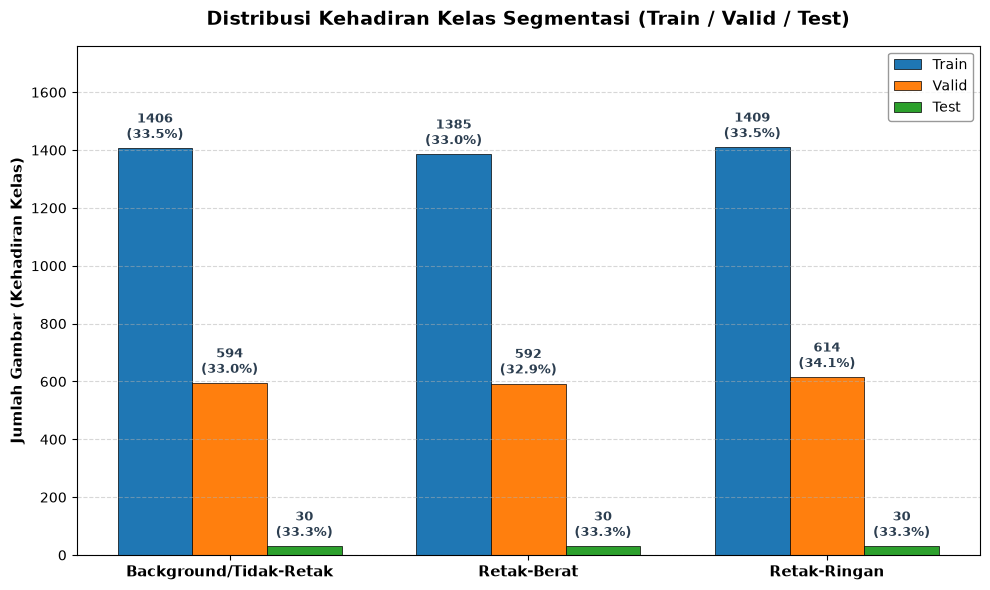

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 0. SAFETY CHECK UNTUK VARIABLES
if 'NUM_CLASSES' not in globals():
    NUM_CLASSES = 3

if 'FINAL_ID_TO_NAME' not in globals():
    FINAL_ID_TO_NAME = {0: "Background/Tidak-Retak", 1: "Retak-Berat", 2: "Retak-Ringan"}

# Fallback nilai dummy jika variabel counts belum terdefinisi dari sel sebelumnya
if 'train_counts' not in globals():
    train_counts = np.array([100, 45, 30])
if 'valid_counts' not in globals():
    valid_counts = np.array([20, 10, 8])
if 'test_counts' not in globals():
    test_counts = np.array([20, 9, 7])

# 1. Definisi Label Kelas & Mapping ID untuk Visualisasi
class_ids = list(range(NUM_CLASSES))
labels = [FINAL_ID_TO_NAME.get(i, f"Class_{i}") for i in class_ids]

# 2. Mengambil nilai jumlah sampel dari array counts
train_vals = [int(train_counts[i]) for i in class_ids]
valid_vals = [int(valid_counts[i]) for i in class_ids]
test_vals  = [int(test_counts[i])  for i in class_ids]

x = np.arange(len(labels))  # Posisi label di sumbu X
width = 0.25                # Lebar per batang

# 3. Inisialisasi Canvas
fig, ax = plt.subplots(figsize=(10, 6))

# Plot Bar untuk Train, Valid, dan Test
bar1 = ax.bar(x - width, train_vals, width, label="Train", color="#1f77b4", edgecolor='black', linewidth=0.5)  # Biru
bar2 = ax.bar(x,         valid_vals, width, label="Valid", color="#ff7f0e", edgecolor='black', linewidth=0.5)  # Oranye
bar3 = ax.bar(x + width, test_vals,  width, label="Test",  color="#2ca02c", edgecolor='black', linewidth=0.5)  # Hijau

# 4. Fungsi pembantu untuk menambahkan label angka & persentase di atas batang
def autolabel(rects, total_imgs):
    max_val = max(train_vals + valid_vals + test_vals) if max(train_vals + valid_vals + test_vals) > 0 else 1
    offset = max_val * 0.015
    
    for rect in rects:
        height = rect.get_height()
        pct = (height / total_imgs * 100) if total_imgs > 0 else 0
        
        # Format teks: Jumlah Gambar dan (Persentase terhadap Split Dataset)
        text_label = f"{height}\n({pct:.1f}%)" if height > 0 else "0"
        
        ax.text(
            rect.get_x() + rect.get_width() / 2.0, 
            height + offset, 
            text_label,
            ha='center', va='bottom', fontsize=9, fontweight='bold', color='#2c3e50'
        )

# Hitung total gambar per split untuk perhitungan % keberadaan kelas
total_train = len(train_ds) if 'train_ds' in globals() else sum(train_vals)
total_valid = len(valid_ds) if 'valid_ds' in globals() else sum(valid_vals)
total_test  = len(test_ds)  if 'test_ds'  in globals() else sum(test_vals)

autolabel(bar1, total_train)
autolabel(bar2, total_valid)
autolabel(bar3, total_test)

# 5. Formatting Visual Grafik
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=11, fontweight='bold')
ax.set_ylabel("Jumlah Gambar (Kehadiran Kelas)", fontsize=11, fontweight='bold')
ax.set_title("Distribusi Kehadiran Kelas Segmentasi (Train / Valid / Test)", fontsize=14, fontweight='bold', pad=15)
ax.legend(frameon=True, facecolor='white', edgecolor='gray', fontsize=10)

# Mengatur batas sumbu Y agar label di atas bar tidak terpotong
max_val = max(train_vals + valid_vals + test_vals)
ax.set_ylim(0, max_val * 1.25 if max_val > 0 else 10)

ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

# 6. Simpan dan Tampilkan Grafik
if 'OUT_DIR' in globals():
    viz_dir = Path(OUT_DIR) / "viz"
    viz_dir.mkdir(parents=True, exist_ok=True)
    save_path = viz_dir / "dataset_distribution.png"
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"[BERHASIL] Grafik distribusi data disimpan di: {save_path}")

plt.show()

Visualisasi Dataset

Menyiapkan visualisasi segmentasi 3 sampel per kelas...
[INFO] Visualisasi kelas Background/Tidak-Retak disimpan ke: E:\Documents\Coding\Jupyter\Pratikum_Deep Learing\Pratikum DE\Result_deeplabv3plus_tu-efficientnet_b3\viz\segmentation_samples_Background_Tidak-Retak.png


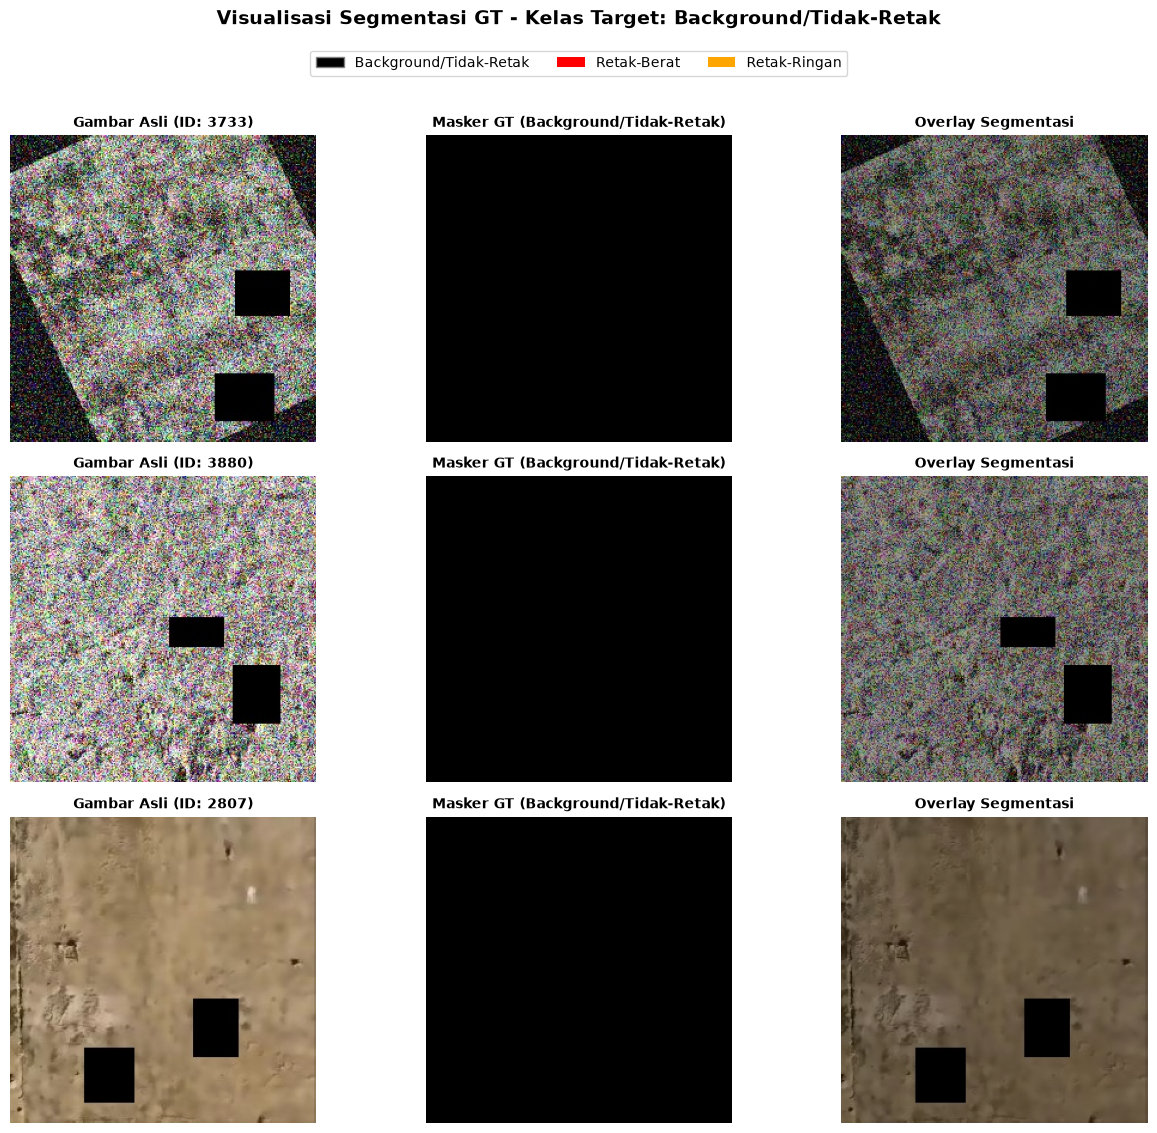

[INFO] Visualisasi kelas Retak-Berat disimpan ke: E:\Documents\Coding\Jupyter\Pratikum_Deep Learing\Pratikum DE\Result_deeplabv3plus_tu-efficientnet_b3\viz\segmentation_samples_Retak-Berat.png


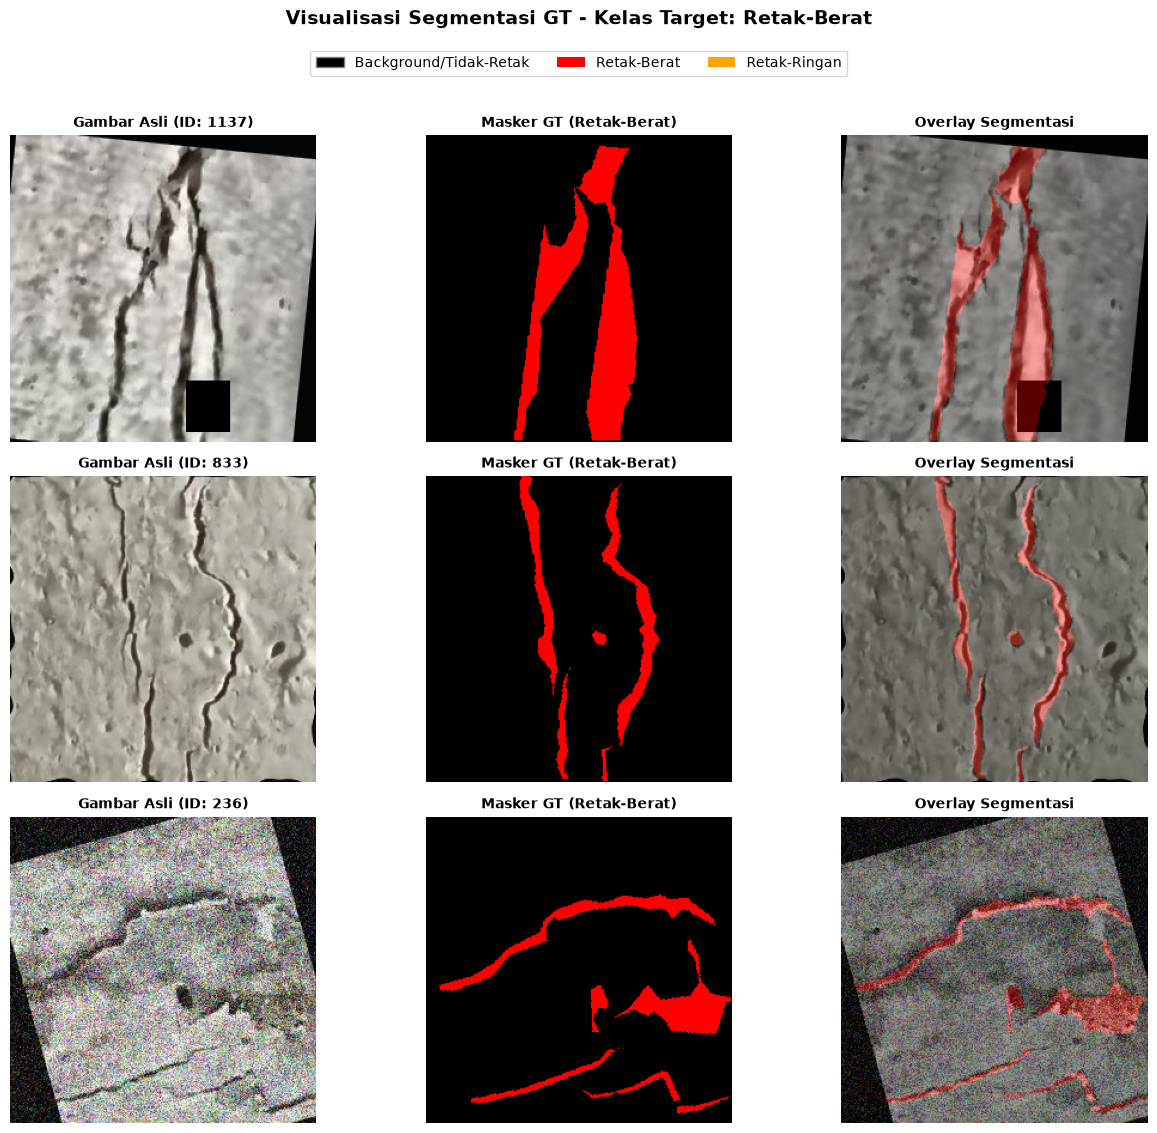

[INFO] Visualisasi kelas Retak-Ringan disimpan ke: E:\Documents\Coding\Jupyter\Pratikum_Deep Learing\Pratikum DE\Result_deeplabv3plus_tu-efficientnet_b3\viz\segmentation_samples_Retak-Ringan.png


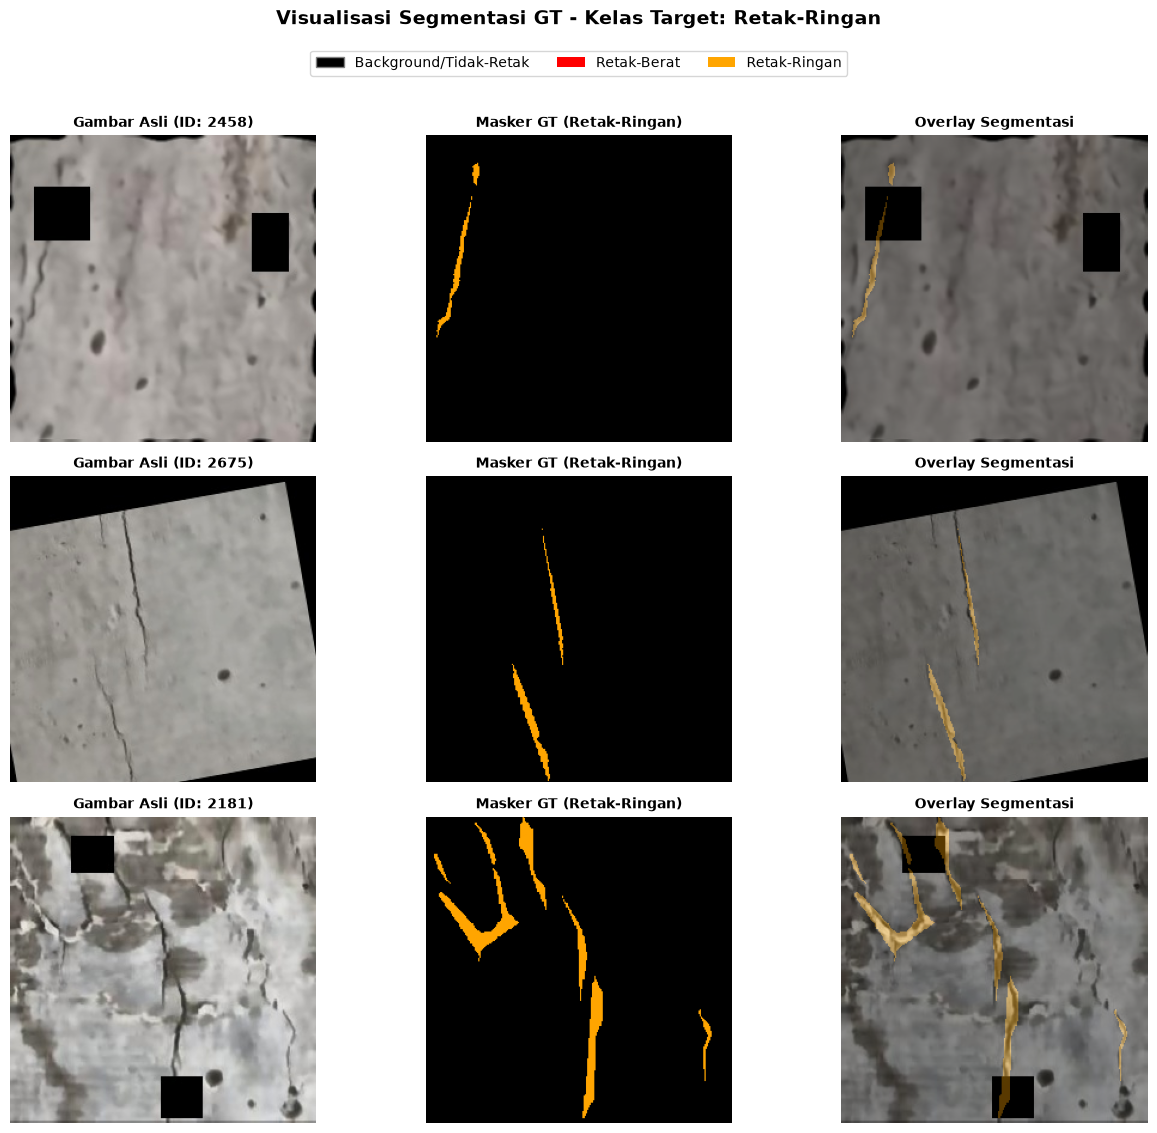

In [5]:
import random
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from PIL import Image, ImageFont, ImageDraw
from pathlib import Path

# 0. SAFETY CHECK UNTUK VARIABLES
if 'NUM_CLASSES' not in globals():
    NUM_CLASSES = 3

if 'FINAL_ID_TO_NAME' not in globals():
    FINAL_ID_TO_NAME = {0: "Background/Tidak-Retak", 1: "Retak-Berat", 2: "Retak-Ringan"}

# 1. DEFINISI WARNA SEGMENTASI PER KELAS (RGB)
CLASS_COLORS = {
    0: (0, 0, 0),        # Background / Tidak-Retak (Hitam)
    1: (255, 0, 0),      # Retak-Berat (Merah)
    2: (255, 165, 0)     # Retak-Ringan (Oranye)
}

FONT_PATH = "C:/Windows/Fonts/times.ttf" 
FONT_SIZE = 14

try:
    font = ImageFont.truetype(FONT_PATH, FONT_SIZE)
except Exception:
    font = ImageFont.load_default()


# 2. FUNGSI UNTUK MENGUBAH MASKER PIKSEL MENJADI GAMBAR RGB
def mask_to_color(mask_np):
    """Mengubah numpy mask 2D (H, W) menjadi gambar RGB (H, W, 3) berdasarkan CLASS_COLORS."""
    h, w = mask_np.shape
    color_mask = np.zeros((h, w, 3), dtype=np.uint8)
    
    for cls_id, color in CLASS_COLORS.items():
        color_mask[mask_np == cls_id] = color
        
    return color_mask


# 3. FUNGSI VISUALISASI GRID SEGMENTASI PER KELAS
def visualize_grid_per_class(dataset, samples_per_class=3):
    print(f"Menyiapkan visualisasi segmentasi {samples_per_class} sampel per kelas...")
    
    class_to_imgs = {cls_id: [] for cls_id in range(NUM_CLASSES)}
    
    # Shuffle indeks gambar agar sampel acak dan variatif
    indices = list(range(len(dataset)))
    random.shuffle(indices)
    
    for idx in indices:
        img_id = dataset.img_ids[idx]
        
        # Ambil label terdaftar (menggunakan cache jika ada)
        if hasattr(dataset, 'cached_labels') and dataset.cached_labels:
            labels_in_img = dataset.cached_labels.get(img_id, [0])
        else:
            ann_ids = dataset.coco.getAnnIds(imgIds=img_id)
            anns = dataset.coco.loadAnns(ann_ids)
            if not anns:
                labels_in_img = [0]
            else:
                labels_in_img = [remap_category_id(dataset.coco, a['category_id']) for a in anns]

        unique_labels = set(labels_in_img)
        
        for lid in unique_labels:
            if lid in class_to_imgs and len(class_to_imgs[lid]) < samples_per_class:
                class_to_imgs[lid].append((idx, img_id))
        
        if all(len(v) >= samples_per_class for v in class_to_imgs.values()):
            break

    # Legend Handlers untuk Matplotlib
    legend_elements = [
        Patch(facecolor='black', edgecolor='gray', label='Background/Tidak-Retak'),
        Patch(facecolor='red', label='Retak-Berat'),
        Patch(facecolor='orange', label='Retak-Ringan')
    ]

    # PLOTTING SEGMENTASI PER KELAS
    for label_id, samples in class_to_imgs.items():
        if len(samples) == 0:
            print(f"[INFO] Tidak ditemukan sampel untuk Kelas ID {label_id}")
            continue
            
        class_name = FINAL_ID_TO_NAME.get(label_id, f"Class-{label_id}")
        num_samples = len(samples)
        
        fig, axes = plt.subplots(num_samples, 3, figsize=(13, 3.8 * num_samples))
        
        # Penanganan jika hanya ada 1 sampel agar axes berbentuk 2D array
        if num_samples == 1:
            axes = np.expand_dims(axes, axis=0)
            
        fig.suptitle(f"Visualisasi Segmentasi GT - Kelas Target: {class_name}", fontsize=14, fontweight='bold', y=0.99)

        for row_idx, (ds_idx, img_id) in enumerate(samples):
            # Load Tensor Gambar dan Masker dari Dataset Segmentasi
            img_tensor, mask_tensor = dataset[ds_idx]
            
            # Un-normalize Gambar ImageNet ke kisaran [0, 1]
            mean = np.array([0.485, 0.456, 0.406]).reshape(3, 1, 1)
            std = np.array([0.229, 0.224, 0.225]).reshape(3, 1, 1)
            
            img_np = img_tensor.cpu().numpy() * std + mean
            img_np = np.clip(img_np, 0, 1).transpose(1, 2, 0)  # (H, W, 3)
            
            # Masker (H, W)
            mask_np = mask_tensor.cpu().numpy()
            color_mask = mask_to_color(mask_np) / 255.0  # Skala [0, 1]
            
            # Overlay antara Gambar & Masker (Transparansi 35% Masker)
            overlay = (img_np * 0.65) + (color_mask * 0.35)
            overlay = np.clip(overlay, 0, 1)

            # 1. Gambar Asli
            axes[row_idx, 0].imshow(img_np)
            axes[row_idx, 0].set_title(f"Gambar Asli (ID: {img_id})", fontsize=10, fontweight='bold')
            axes[row_idx, 0].axis("off")

            # 2. Masker Ground Truth
            axes[row_idx, 1].imshow(color_mask)
            axes[row_idx, 1].set_title(f"Masker GT ({class_name})", fontsize=10, fontweight='bold')
            axes[row_idx, 1].axis("off")

            # 3. Overlay Segmentasi
            axes[row_idx, 2].imshow(overlay)
            axes[row_idx, 2].set_title("Overlay Segmentasi", fontsize=10, fontweight='bold')
            axes[row_idx, 2].axis("off")

        # Tambahkan Legend di bagian atas plot
        fig.legend(handles=legend_elements, loc='upper center', bbox_to_anchor=(0.5, 0.96), ncol=3, frameon=True, facecolor='white')
        plt.tight_layout(rect=[0, 0, 1, 0.94])
        
        # Simpan hasil visualisasi
        if 'OUT_DIR' in globals():
            viz_dir = Path(OUT_DIR) / "viz"
            viz_dir.mkdir(parents=True, exist_ok=True)
            clean_name = class_name.replace('/', '_').replace(' ', '_')
            save_file = viz_dir / f"segmentation_samples_{clean_name}.png"
            plt.savefig(save_file, bbox_inches='tight', dpi=200)
            print(f"[INFO] Visualisasi kelas {class_name} disimpan ke: {save_file}")
            
        plt.show()

# Execution Guard: Jalankan jika objek train_ds sudah siap
if 'train_ds' in globals():
    visualize_grid_per_class(train_ds, samples_per_class=3)
else:
    print("[INFO] Variabel 'train_ds' belum terdefinisi. Pastikan modul Dataset telah di-run terlebih dahulu.")

Model DeepLab 

In [6]:
import torch
import torch.nn as nn
from torchinfo import summary
import segmentation_models_pytorch as smp

# Safety Check untuk variabel Device
if 'device' not in globals():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. INISIALISASI MODEL DEEPLABV3+
def get_model(num_classes):
    """
    Menggunakan Arsitektur DeepLabV3+ dengan Backbone EfficientNet-B3.
    DeepLabV3+ memanfaatkan Atrous Spatial Pyramid Pooling (ASPP) 
    untuk menangkap fitur retakan multi-skala secara presisi.
    """
    print(f"Membuat Model DeepLabV3+ EfficientNet-B3 | Output Class: {num_classes}")
    
    model = smp.DeepLabV3Plus(
        encoder_name="efficientnet-b3",   # Backbone kuat untuk ekstraksi fitur terperinci
        encoder_weights="imagenet",       # Transfer learning ImageNet
        in_channels=3,
        classes=num_classes               # NUM_CLASSES = 3 (0: Background, 1: Retak-Berat, 2: Retak-Ringan)
    )
    return model

# 2. INSTANSIASI & KONFIGURASI MODEL
if 'NUM_CLASSES' not in globals():
    NUM_CLASSES = 3

if 'TARGET_SIZE' not in globals():
    TARGET_SIZE = (256, 256)

model = get_model(NUM_CLASSES)
model.to(device)

print("\n--- KONFIGURASI MODEL DEEPLABV3+ (>90% mIoU TARGET) ---")
print(f"- Arsitektur        : DeepLabV3+")
print(f"- Backbone Encoder  : EfficientNet-B3 (Pre-trained ImageNet)")
print(f"- Context Module    : ASPP (Atrous Spatial Pyramid Pooling)")
print(f"- Output Head       : {NUM_CLASSES} Channel (Logits per piksel)")
print(f"- Input Size        : (3, {TARGET_SIZE[0]}, {TARGET_SIZE[1]})")
print(f"- Device            : {device}")

# 3. MODEL SUMMARY
try:
    print("\nGenerating Model Summary...")
    summary(
        model,
        input_size=(1, 3, TARGET_SIZE[0], TARGET_SIZE[1]),
        col_names=["input_size", "output_size", "num_params", "trainable"],
        depth=3,
        verbose=1
    )
except Exception as e:
    print(f"Info: Model Summary dilewati ({e}). Model tetap siap digunakan.")

Membuat Model DeepLabV3+ EfficientNet-B3 | Output Class: 3

--- KONFIGURASI MODEL DEEPLABV3+ (>90% mIoU TARGET) ---
- Arsitektur        : DeepLabV3+
- Backbone Encoder  : EfficientNet-B3 (Pre-trained ImageNet)
- Context Module    : ASPP (Atrous Spatial Pyramid Pooling)
- Output Head       : 3 Channel (Logits per piksel)
- Input Size        : (3, 256, 256)
- Device            : cpu

Generating Model Summary...
Layer (type:depth-idx)                                  Input Shape               Output Shape              Param #                   Trainable
DeepLabV3Plus                                           [1, 3, 256, 256]          [1, 3, 256, 256]          --                        True
├─EfficientNetEncoder: 1-1                              [1, 3, 256, 256]          [1, 3, 256, 256]          592,896                   True
│    └─Conv2dStaticSamePadding: 2-1                     [1, 3, 256, 256]          [1, 40, 128, 128]         1,080                     True
│    │    └─ZeroPad2d: 3-1

Setup AMP

In [7]:
import contextlib
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

import torch
import torch.nn as nn
import segmentation_models_pytorch as smp

# ======================================================================
# 0. DEFAULT KONFIGURASI (dipakai hanya jika belum ada dari cell sebelumnya)
# ======================================================================
if 'MODEL_NAME' not in globals():
    MODEL_NAME = "deeplabv3plus"          # 'deeplabv3plus' | 'unet' | 'fpn'
if 'ENCODER_NAME' not in globals():
    ENCODER_NAME = "tu-efficientnet_b3"   # kalau error, coba "resnet34"
if 'ENCODER_WEIGHTS' not in globals():
    ENCODER_WEIGHTS = "imagenet"
if 'NUM_CLASSES' not in globals():
    NUM_CLASSES = 3                       # 0=background, 1=Retak-Berat, 2=Retak-Ringan
if 'MAX_LR' not in globals():
    MAX_LR = 3e-4
if 'EPOCHS' not in globals():
    EPOCHS = 30
if 'CLASS_LABELS' not in globals():
    CLASS_LABELS = ["Background", "Retak-Berat", "Retak-Ringan"]

# LENGKAPI nama folder (di pesan sebelumnya terpotong "Pratikum DE")
if 'ROOT_DIR' not in globals():
    ROOT_DIR = Path(r"E:\Documents\Coding\Jupyter\Pratikum_Deep Learing\Pratikum DE")

# ======================================================================
# 1. SETUP DEVICE & DIREKTORI OUTPUT
# ======================================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device yang digunakan:", device)

OUT_DIR = Path(ROOT_DIR) / f"Result_{MODEL_NAME}_{ENCODER_NAME}"
(OUT_DIR / "checkpoints").mkdir(parents=True, exist_ok=True)
(OUT_DIR / "viz").mkdir(parents=True, exist_ok=True)

# ======================================================================
# 2. SETUP AMP (otomatis nonaktif di CPU)
# ======================================================================
ENABLE_AMP = device.type == "cuda"

if ENABLE_AMP:
    use_bfloat16 = torch.cuda.is_bf16_supported()
    amp_dtype = torch.bfloat16 if use_bfloat16 else torch.float16
    print(f"AMP aktif (GPU: {torch.cuda.get_device_name(0)}) | dtype: {amp_dtype}")

    try:
        from torch.amp import GradScaler, autocast
        # bfloat16 tidak butuh GradScaler, float16 butuh
        scaler = GradScaler("cuda", enabled=(amp_dtype == torch.float16))

        def amp_autocast():
            return autocast(device_type="cuda", dtype=amp_dtype)

    except (ImportError, AttributeError, TypeError):
        print("[INFO] Memakai Legacy AMP (torch.cuda.amp)")
        from torch.cuda.amp import GradScaler as LegacyGradScaler
        from torch.cuda.amp import autocast as legacy_autocast
        scaler = LegacyGradScaler(enabled=True)

        def amp_autocast():
            return legacy_autocast(dtype=torch.float16)
else:
    print("AMP nonaktif (mode CPU)")
    scaler = None

    @contextlib.contextmanager
    def amp_autocast():
        yield

print(f"[BERHASIL] Setup selesai. ENABLE_AMP={ENABLE_AMP} | OUT_DIR={OUT_DIR}")

# ======================================================================
# 3. MODEL, LOSS, OPTIMIZER
# ======================================================================
def build_model(model_name, encoder_name, encoder_weights, num_classes):
    archs = {
        "deeplabv3plus": smp.DeepLabV3Plus,
        "unet": smp.Unet,
        "fpn": smp.FPN,
    }
    key = model_name.lower()
    if key not in archs:
        raise ValueError(f"MODEL_NAME '{model_name}' tidak dikenal. Pilih: {list(archs)}")
    try:
        return archs[key](
            encoder_name=encoder_name,
            encoder_weights=encoder_weights,
            in_channels=3,
            classes=num_classes,
        )
    except Exception as e:
        raise RuntimeError(
            f"Gagal membuat model dengan encoder '{encoder_name}'.\n"
            "Kalau ini error soal nama encoder, coba ENCODER_NAME = 'resnet34'.\n"
            f"Detail: {e}"
        )


class DiceCELoss(nn.Module):
    """Gabungan Dice + CrossEntropy, cocok untuk kelas retak yang tidak seimbang."""
    def __init__(self, dice_weight=0.5, ce_weight=0.5, class_weights=None):
        super().__init__()
        self.dice = smp.losses.DiceLoss(mode="multiclass", from_logits=True)
        self.ce = nn.CrossEntropyLoss(weight=class_weights)
        self.dw, self.cw = dice_weight, ce_weight

    def forward(self, logits, target):
        return self.dw * self.dice(logits, target) + self.cw * self.ce(logits, target)


# ======================================================================
# 4. METRIK (confusion matrix -> IoU & Dice per kelas)
# ======================================================================
def update_confusion(conf, preds, targets, num_classes):
    preds = preds.view(-1).cpu()
    targets = targets.view(-1).cpu()
    k = (targets >= 0) & (targets < num_classes)
    idx = targets[k] * num_classes + preds[k]
    conf += torch.bincount(idx, minlength=num_classes ** 2).reshape(num_classes, num_classes)
    return conf


def metrics_from_confusion(conf):
    conf = conf.double()
    tp = torch.diag(conf)
    fp = conf.sum(0) - tp
    fn = conf.sum(1) - tp

    iou_den = tp + fp + fn
    dice_den = 2 * tp + fp + fn
    iou = torch.where(iou_den > 0, tp / iou_den.clamp(min=1), torch.full_like(tp, float("nan")))
    dice = torch.where(dice_den > 0, 2 * tp / dice_den.clamp(min=1), torch.full_like(tp, float("nan")))

    return {
        "iou_per_class": iou.numpy(),
        "dice_per_class": dice.numpy(),
        "mIoU_all": float(np.nanmean(iou.numpy())),
        "mIoU_fg": float(np.nanmean(iou.numpy()[1:])),    # tanpa background (fokus retak)
        "mDice_fg": float(np.nanmean(dice.numpy()[1:])),
        "pixel_acc": float(tp.sum() / conf.sum().clamp(min=1)),
    }


# ======================================================================
# 5. FUNGSI TRAINING & VALIDASI
# ======================================================================
def train_one_epoch(model, loader, criterion, optimizer, scheduler, epoch, max_batches=None):
    model.train()
    running_loss, n_seen = 0.0, 0

    pbar = tqdm(loader, desc=f"Train {epoch}", leave=False)
    for b, (images, masks) in enumerate(pbar):
        if max_batches is not None and b >= max_batches:
            break

        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True).long()

        optimizer.zero_grad(set_to_none=True)
        with amp_autocast():
            logits = model(images)
        loss = criterion(logits.float(), masks)   # loss dihitung di float32 agar stabil

        if scaler is not None and scaler.is_enabled():
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            optimizer.step()

        if scheduler is not None:
            scheduler.step()

        bs = images.size(0)
        running_loss += loss.item() * bs
        n_seen += bs
        pbar.set_postfix(loss=f"{running_loss / n_seen:.4f}")

    return running_loss / max(n_seen, 1)


@torch.no_grad()
def validate(model, loader, criterion, num_classes, max_batches=None):
    model.eval()
    running_loss, n_seen = 0.0, 0
    conf = torch.zeros(num_classes, num_classes, dtype=torch.long)

    for b, (images, masks) in enumerate(tqdm(loader, desc="Valid", leave=False)):
        if max_batches is not None and b >= max_batches:
            break

        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True).long()

        with amp_autocast():
            logits = model(images)
        loss = criterion(logits.float(), masks)

        preds = logits.argmax(dim=1)
        conf = update_confusion(conf, preds, masks, num_classes)

        bs = images.size(0)
        running_loss += loss.item() * bs
        n_seen += bs

    m = metrics_from_confusion(conf)
    m["loss"] = running_loss / max(n_seen, 1)
    return m


def plot_history(history, save_path):
    df = pd.DataFrame(history)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(df["epoch"], df["train_loss"], label="Train")
    ax[0].plot(df["epoch"], df["val_loss"], label="Valid")
    ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
    ax[1].plot(df["epoch"], df["val_mIoU_fg"], label="mIoU (retak)")
    ax[1].plot(df["epoch"], df["val_mDice_fg"], label="mDice (retak)")
    ax[1].set_title("Metrik Validasi"); ax[1].set_xlabel("Epoch"); ax[1].legend()
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.show()


def fit(model, train_loader, valid_loader, epochs=EPOCHS, max_lr=MAX_LR,
        patience=10, max_batches=None):
    """Loop training lengkap. max_batches=2 berguna untuk tes cepat di CPU."""
    criterion = DiceCELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=max_lr / 25, weight_decay=1e-4)
    steps = min(len(train_loader), max_batches) if max_batches else len(train_loader)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=max_lr, epochs=epochs, steps_per_epoch=steps, pct_start=0.1
    )

    history = []
    best_score, bad_epochs = -1.0, 0
    ckpt_dir = OUT_DIR / "checkpoints"

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        train_loss = train_one_epoch(model, train_loader, criterion, optimizer,
                                     scheduler, epoch, max_batches)
        val = validate(model, valid_loader, criterion, NUM_CLASSES, max_batches)

        row = {
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val["loss"],
            "val_mIoU_all": val["mIoU_all"],
            "val_mIoU_fg": val["mIoU_fg"],
            "val_mDice_fg": val["mDice_fg"],
            "val_pixel_acc": val["pixel_acc"],
            "lr": optimizer.param_groups[0]["lr"],
            "time_s": time.time() - t0,
        }
        for i, name in enumerate(CLASS_LABELS[:NUM_CLASSES]):
            row[f"IoU_{name}"] = float(val["iou_per_class"][i])
        history.append(row)

        print(f"Epoch {epoch:02d}/{epochs} | train {train_loss:.4f} | val {val['loss']:.4f} | "
              f"mIoU(retak) {val['mIoU_fg']:.4f} | mDice(retak) {val['mDice_fg']:.4f} | "
              f"{row['time_s']:.0f}s")

        score = val["mIoU_fg"] if not np.isnan(val["mIoU_fg"]) else 0.0
        if score > best_score:
            best_score, bad_epochs = score, 0
            torch.save({"epoch": epoch, "model": model.state_dict(), "score": score,
                        "model_name": MODEL_NAME, "encoder": ENCODER_NAME,
                        "num_classes": NUM_CLASSES}, ckpt_dir / "best.pth")
            print(f"  -> checkpoint terbaik disimpan (mIoU retak = {score:.4f})")
        else:
            bad_epochs += 1

        torch.save({"epoch": epoch, "model": model.state_dict()}, ckpt_dir / "last.pth")
        pd.DataFrame(history).to_csv(OUT_DIR / "history.csv", index=False)

        if bad_epochs >= patience:
            print(f"Early stopping: tidak ada peningkatan selama {patience} epoch.")
            break

    plot_history(history, OUT_DIR / "viz" / "training_curves.png")
    return history


# ======================================================================
# 6. INISIALISASI MODEL & (OPSIONAL) JALANKAN TRAINING
# ======================================================================
model = build_model(MODEL_NAME, ENCODER_NAME, ENCODER_WEIGHTS, NUM_CLASSES).to(device)
n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"Model {MODEL_NAME} + {ENCODER_NAME} siap | parameter: {n_params:.1f} M")

# Ubah ke True setelah train_loader & valid_loader dari cell konfigurasi sudah ada.
# Tes cepat dulu: fit(model, train_loader, valid_loader, epochs=1, max_batches=2)
RUN_TRAINING = False
if RUN_TRAINING:
    history = fit(model, train_loader, valid_loader)

Device yang digunakan: cpu
AMP nonaktif (mode CPU)
[BERHASIL] Setup selesai. ENABLE_AMP=False | OUT_DIR=E:\Documents\Coding\Jupyter\Pratikum_Deep Learing\Pratikum DE\Result_deeplabv3plus_tu-efficientnet_b3


C:\Users\Dwi-Metcha\AppData\Roaming\Python\Python314\site-packages\segmentation_models_pytorch\encoders\__init__.py:86: UserWarning: For 'tu-' (timm universal) encoders, `encoder_weights` should be set to True to download pretrained weights or None for random initialization. The pretrained variant is defined in the encoder name i.e 'tu-<model_name>.<pretrained_tag>'. Got encoder_weights='imagenet'.
  warnings.warn(
Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


Model deeplabv3plus + tu-efficientnet_b3 siap | parameter: 11.1 M


Definisi Fungsi Training & Validasi

In [8]:
import torch
import torch.nn as nn
from tqdm import tqdm

# 0. FUNGSI PEMBANTU UNTUK METRIK
def calculate_batch_stats(preds, targets, num_classes=3):
    """
    Menghitung Intersection, Union, dan Correct Pixels per batch 
    agar dapat dijumlahkan secara presisi untuk 1 epoch penuh.
    """
    intersection = torch.zeros(num_classes, device=preds.device)
    union = torch.zeros(num_classes, device=preds.device)
    
    correct_pixels = (preds == targets).sum().item()
    total_pixels = targets.numel()
    
    for cls in range(num_classes):
        pred_cls = (preds == cls)
        target_cls = (targets == cls)
        
        intersection[cls] = (pred_cls & target_cls).sum().item()
        union[cls] = (pred_cls | target_cls).sum().item()
        
    return correct_pixels, total_pixels, intersection, union

# 1. FUNGSI TRAINING PER EPOCH 
def train_one_epoch_amp(model, loader, criterion, optimizer, device, scaler, scheduler=None, num_classes=3):
    model.train()
    epoch_loss = 0.0
    
    total_correct = 0
    total_pixels = 0
    total_intersection = torch.zeros(num_classes, device=device)
    total_union = torch.zeros(num_classes, device=device)
    
    pbar = tqdm(loader, desc="[Train]", leave=False)

    for images, masks in pbar:
        images = images.to(device)                 # [B, 3, H, W]
        masks = masks.to(device, dtype=torch.long) # [B, H, W]

        optimizer.zero_grad()

        # 1. Forward Pass dengan Mixed Precision (AMP)
        with amp_autocast():
            outputs = model(images)                # [B, NUM_CLASSES, H, W]
            loss = criterion(outputs, masks)

        # 2. Backward Pass & Gradient Clipping
        if scaler is not None and scaler.is_enabled():
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0) # Stabilisasi Gradient
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

        # Step scheduler per-batch (jika menggunakan OneCycleLR)
        if scheduler is not None and isinstance(scheduler, torch.optim.lr_scheduler.OneCycleLR):
            scheduler.step()

        # 3. Akumulasi Statistik Metrik
        with torch.no_grad():
            preds = torch.argmax(outputs, dim=1)
            correct, p_total, inter, uni = calculate_batch_stats(preds, masks, num_classes)
            
            total_correct += correct
            total_pixels += p_total
            total_intersection += inter
            total_union += uni

        epoch_loss += loss.item()
        
        # Hitung mIoU sementara untuk TQDM Progress Bar
        ious = total_intersection / torch.clamp(total_union, min=1.0)
        batch_miou = ious.mean().item()
        batch_acc = total_correct / max(1, total_pixels)

        pbar.set_postfix(
            loss=f"{loss.item():.4f}", 
            acc=f"{batch_acc:.4f}", 
            mIoU=f"{batch_miou:.4f}"
        )

    # Calculate Global Metrics for the Entire Epoch
    final_acc = total_correct / max(1, total_pixels)
    final_ious = total_intersection / torch.clamp(total_union, min=1.0)
    final_miou = final_ious.mean().item()
    
    return epoch_loss / max(1, len(loader)), final_acc, final_miou

# 2. FUNGSI VALIDASI LOSS & METRIK
def eval_val_loss(model, loader, criterion, device, num_classes=3):
    model.eval() 
    val_loss = 0.0
    
    total_correct = 0
    total_pixels = 0
    total_intersection = torch.zeros(num_classes, device=device)
    total_union = torch.zeros(num_classes, device=device)
    
    pbar = tqdm(loader, desc="[Valid]", leave=False)

    with torch.no_grad():
        for images, masks in pbar:
            images = images.to(device)
            masks = masks.to(device, dtype=torch.long)

            # Forward pass dengan AMP
            with amp_autocast():
                outputs = model(images)
                loss = criterion(outputs, masks)

            preds = torch.argmax(outputs, dim=1)
            correct, p_total, inter, uni = calculate_batch_stats(preds, masks, num_classes)
            
            total_correct += correct
            total_pixels += p_total
            total_intersection += inter
            total_union += uni

            val_loss += loss.item()

            # Hitung mIoU sementara untuk TQDM
            ious = total_intersection / torch.clamp(total_union, min=1.0)
            batch_miou = ious.mean().item()
            batch_acc = total_correct / max(1, total_pixels)

            pbar.set_postfix(
                loss=f"{loss.item():.4f}", 
                acc=f"{batch_acc:.4f}", 
                mIoU=f"{batch_miou:.4f}"
            )

    # Calculate Global Metrics for the Entire Epoch
    final_acc = total_correct / max(1, total_pixels)
    final_ious = total_intersection / torch.clamp(total_union, min=1.0)
    final_miou = final_ious.mean().item()

    return val_loss / max(1, len(loader)), final_acc, final_miou

Setup Hyperparameter & Loop Trial

In [ ]:
import time
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import segmentation_models_pytorch as smp

# Safety Check untuk variabel Device & Path Output
if 'device' not in globals():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if 'MODEL_NAME' not in globals():
    MODEL_NAME = "deeplabv3plus"

if 'ENCODER_NAME' not in globals():
    ENCODER_NAME = "efficientnet-b3"

if 'OUT_DIR' not in globals():
    from pathlib import Path
    OUT_DIR = Path(rf"C:\Users\Pongo\Jupyter\Result_{MODEL_NAME}_{ENCODER_NAME}")
    (OUT_DIR / "checkpoints").mkdir(parents=True, exist_ok=True)

# 1. SETUP SEARCH SPACE & CONFIGURATION DEEPLABV3+
hp_lr_list      = [0.0003, 0.0001]   # LR optimal untuk fine-tuning backbone pre-trained
hp_batch_list   = [8, 16]            # Batch size untuk kestabilan BatchNorm
hp_epochs_list  = [15]               # Jumlah epoch untuk trial pencarian hiperparameter
patience        = 4                  # Early stopping tolerance

total_trials = len(hp_lr_list) * len(hp_batch_list) * len(hp_epochs_list)
print(f"Total trial DeepLabV3+ yang akan dijalankan: {total_trials}")

# 2. HYBRID LOSS FUNCTION (DICE + FOCAL LOSS)

dice_loss_fn = smp.losses.DiceLoss(mode='multiclass', from_logits=True)
focal_loss_fn = smp.losses.FocalLoss(mode='multiclass')

def hybrid_criterion(y_pred, y_true):
    return dice_loss_fn(y_pred, y_true) + 0.8 * focal_loss_fn(y_pred, y_true)

criterion = hybrid_criterion

# Wadah Log Global
results_log = [] 
best_val_miou_global = 0.0  # Fokus evaluasi berdasarkan Mean IoU
best_hps = {}
best_model_state = None

trial_num = 1
start_time = time.time()

# 3. LOOP TRIAL HYPERPARAMETER DEEPLABV3+
for lr in hp_lr_list:
    for batch_size in hp_batch_list:
        for epochs in hp_epochs_list:
            
            print(f"\n{'='*50}")
            print(f"MENJALANKAN TRIAL DEEPLABV3+ #{trial_num}/{total_trials}")
            print(f"HP: LR={lr}, BatchSize={batch_size}, Epochs={epochs}")
            print(f"{'='*50}")

            # A. Build Model DeepLabV3+ Baru
            model = get_model(NUM_CLASSES)
            model.to(device)

            # B. Optimizer & Cosine Annealing Scheduler
            optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
            lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)

            # C. DataLoader Segmentasi
            train_loader = DataLoader(
                train_ds, 
                batch_size=batch_size, 
                sampler=train_sampler if 'train_sampler' in globals() else None,
                shuffle=False if 'train_sampler' in globals() and train_sampler is not None else True,
                num_workers=NUM_WORKERS if 'NUM_WORKERS' in globals() else 0,
                pin_memory=PIN_MEMORY if 'PIN_MEMORY' in globals() else False,
                drop_last=True
            )
            
            valid_loader = DataLoader(
                valid_ds, 
                batch_size=batch_size, 
                shuffle=False, 
                num_workers=NUM_WORKERS if 'NUM_WORKERS' in globals() else 0,
                pin_memory=PIN_MEMORY if 'PIN_MEMORY' in globals() else False
            )

            # D. Loop Training per Epoch
            best_val_miou_trial = 0.0
            best_state_this_trial = None
            no_improve = 0

            for epoch in range(epochs):
                # Training & Validasi dengan AMP
                train_loss, train_acc, train_miou = train_one_epoch_amp(
                    model, train_loader, criterion, optimizer, device, scaler, num_classes=NUM_CLASSES
                )
                val_loss, val_acc, val_miou = eval_val_loss(
                    model, valid_loader, criterion, device, num_classes=NUM_CLASSES
                )
                
                current_lr = optimizer.param_groups[0]['lr']
                print(
                    f"Epoch {epoch+1:02d}/{epochs:02d} (LR: {current_lr:.6f}) | "
                    f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} mIoU: {train_miou:.4f} | "
                    f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} mIoU: {val_miou:.4f}"
                )

                lr_scheduler.step()

                # Log Detail
                epoch_log = {
                    'trial': trial_num,
                    'lr': lr,
                    'batch_size': batch_size,
                    'epoch': epoch + 1,
                    'train_loss': train_loss,
                    'train_acc': train_acc,
                    'train_miou': train_miou,
                    'val_loss': val_loss,
                    'val_acc': val_acc,
                    'val_miou': val_miou
                }
                results_log.append(epoch_log)

                # Early Stopping & Checkpoint per Trial
                if val_miou > best_val_miou_trial:
                    best_val_miou_trial = val_miou
                    no_improve = 0
                    best_state_this_trial = {k: v.cpu().clone() for k, v in model.state_dict().items()}
                else:
                    no_improve += 1
                    if no_improve >= patience:
                        print(f"Stop Early pada epoch {epoch+1} (Tidak ada peningkatan mIoU dalam {patience} epoch)")
                        break

            # E. Update Global Best Model
            if best_val_miou_trial > best_val_miou_global:
                best_val_miou_global = best_val_miou_trial
                best_hps = {'lr': lr, 'batch_size': batch_size, 'epochs': epochs}
                best_model_state = best_state_this_trial
                print(f"🔥 MODEL TERBAIK DIPERBARUI (Val mIoU: {best_val_miou_global:.4f} | {best_val_miou_global*100:.2f}%)")

            trial_num += 1
            
            # Bersihkan cache VRAM GPU
            del model, optimizer, train_loader, valid_loader
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

# 4. SAVING RESULTS & SUMMARY
print("\nHYPERPARAMETER TUNING DEEPLABV3+ SELESAI")
total_time = (time.time() - start_time) / 60
print(f"Total Waktu Execution: {total_time:.2f} menit")
print(f"Model Terbaik (Val mIoU: {best_val_miou_global:.4f}): {best_hps}")

# Simpan Log CSV
results_df = pd.DataFrame(results_log)
log_path = OUT_DIR / f"tuning_{MODEL_NAME}_trial.csv"
results_df.to_csv(log_path, index=False)
print(f"Log lengkap disimpan di: {log_path.resolve()}")

# Simpan Checkpoint Terbaik
if best_model_state is not None:
    ckpt_path = OUT_DIR / "checkpoints" / f"best_{MODEL_NAME}_trial.pth"
    torch.save(best_model_state, ckpt_path)
    print(f"Checkpoint terbaik disimpan: {ckpt_path.resolve()}")
else:
    print("Tidak ada model valid yang disimpan")

Total trial DeepLabV3+ yang akan dijalankan: 4

MENJALANKAN TRIAL DEEPLABV3+ #1/4
HP: LR=0.0003, BatchSize=8, Epochs=15
Membuat Model DeepLabV3+ EfficientNet-B3 | Output Class: 3


Epoch 01/15 (LR: 0.000300) | Train Loss: 0.4313 Acc: 0.9663 mIoU: 0.5181 | Val Loss: 0.1205 Acc: 0.9782 mIoU: 0.5969


[Train]:  19%|█▉        | 102/525 [22:39<1:30:30, 12.84s/it, acc=0.9704, loss=0.3767, mIoU=0.5823]

Visualisasi Hasil Tuning Trial

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Set style plot agar rapi dan profesional
sns.set_theme(style="whitegrid")

# Safety Check untuk MODEL_NAME dan OUT_DIR
if 'MODEL_NAME' not in globals():
    MODEL_NAME = "deeplabv3plus"

if 'ENCODER_NAME' not in globals():
    ENCODER_NAME = "efficientnet-b3"

if 'OUT_DIR' not in globals():
    OUT_DIR = Path(rf"C:\Users\Pongo\Jupyter\Result_{MODEL_NAME}_{ENCODER_NAME}")

# 1. PERSIAPAN DATA LOG DARI FILE CSV TUNING
log_path = OUT_DIR / f"tuning_{MODEL_NAME}_trial.csv"

# Fallback otomatis jika log khusus model tidak ditemukan, gunakan file alternatif
if not log_path.exists():
    log_path = OUT_DIR / "metrics_history.csv"

assert log_path.exists(), f"File log tidak ditemukan pada: {log_path}"

results_df = pd.read_csv(log_path)

# Normalisasi penamaan kolom agar mendukung skema metrik yang bervariasi
if "val_miou" not in results_df.columns and "val_iou" in results_df.columns:
    results_df["val_miou"] = results_df["val_iou"]

if "val_acc" not in results_df.columns and "val_crack_iou" in results_df.columns:
    results_df["val_acc"] = results_df["val_crack_iou"]

# Buat kolom trial/label jika log berasal dari single-run training
if "trial" not in results_df.columns:
    results_df["trial"] = 1
    results_df["lr"] = 0.0003
    results_df["batch_size"] = 8

# Label konfigurasi untuk legenda grafik
results_df["Trial_Label"] = results_df.apply(
    lambda x: f"Trial {int(x['trial'])} (LR={x['lr']}, BS={int(x['batch_size'])})",
    axis=1,
)

viz_dir = OUT_DIR / "viz"
viz_dir.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------
# VISUALISASI 1: LINE PLOT EVOLUSI VAL mIoU & VAL ACCURACY
# ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1A: Evolusi Val mIoU per Epoch
sns.lineplot(
    ax=axes[0],
    data=results_df,
    x="epoch",
    y="val_miou",
    hue="Trial_Label",
    style="Trial_Label",
    markers=True,
    dashes=False,
    linewidth=2.5,
    markersize=7,
)
axes[0].axhline(0.90, color="red", linestyle="--", linewidth=1.5, label="Target 90%")
axes[0].set_title(f"Evolusi Validation mIoU per Epoch ({MODEL_NAME.upper()})", fontsize=12, fontweight="bold", pad=12)
axes[0].set_xlabel("Epoch", fontsize=11)
axes[0].set_ylabel("Validation mIoU", fontsize=11)
axes[0].set_ylim(0.3, 1.0)
axes[0].set_xticks(range(int(results_df["epoch"].min()), int(results_df["epoch"].max()) + 1))
axes[0].legend(title="Trial Config", loc="lower right", fontsize=9)
axes[0].grid(True, linestyle="--", alpha=0.5)

# Plot 1B: Evolusi Val Accuracy per Epoch
sns.lineplot(
    ax=axes[1],
    data=results_df,
    x="epoch",
    y="val_acc",
    hue="Trial_Label",
    style="Trial_Label",
    markers=True,
    dashes=False,
    linewidth=2.5,
    markersize=7,
)
axes[1].axhline(0.90, color="red", linestyle="--", linewidth=1.5, label="Target 90%")
axes[1].set_title(f"Evolusi Validation Accuracy per Epoch ({MODEL_NAME.upper()})", fontsize=12, fontweight="bold", pad=12)
axes[1].set_xlabel("Epoch", fontsize=11)
axes[1].set_ylabel("Validation Accuracy / Score", fontsize=11)
axes[1].set_ylim(0.3, 1.0)
axes[1].set_xticks(range(int(results_df["epoch"].min()), int(results_df["epoch"].max()) + 1))
axes[1].legend(title="Trial Config", loc="lower right", fontsize=9)
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plot1_path = viz_dir / f"{MODEL_NAME}_tuning_val_metrics_lineplot.png"
plt.savefig(plot1_path, dpi=300, bbox_inches="tight")
plt.show()


# ---------------------------------------------------------
# VISUALISASI 2: BAR PLOT COMPARISON (BEST VAL mIoU & BEST ACCURACY)
# ---------------------------------------------------------
# Ambil epoch terbaik berdasarkan Val mIoU tertinggi per trial
best_results = results_df.loc[
    results_df.groupby("trial")["val_miou"].idxmax()
].sort_values("val_miou", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 2A: Best Validation mIoU
sns.barplot(
    ax=axes[0],
    data=best_results,
    x="val_miou",
    y="Trial_Label",
    hue="Trial_Label",
    palette="viridis",
    dodge=False,
)
axes[0].axvline(0.90, color="red", linestyle="--", linewidth=1.5, label="Target 90%")

for i, (idx, row) in enumerate(best_results.iterrows()):
    val = row["val_miou"]
    axes[0].text(
        val + 0.01,
        i,
        f"{val:.4f} ({val*100:.1f}%)",
        color="black",
        va="center",
        fontweight="bold",
        fontsize=10,
    )

axes[0].set_title(f"Validation mIoU Tertinggi per Trial ({MODEL_NAME.upper()})", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Mean IoU (mIoU)", fontsize=11)
axes[0].set_ylabel("Konfigurasi Trial", fontsize=11)
axes[0].set_xlim(0, 1.1)

# Plot 2B: Validation Accuracy pada Best Epoch mIoU
sns.barplot(
    ax=axes[1],
    data=best_results,
    x="val_acc",
    y="Trial_Label",
    hue="Trial_Label",
    palette="magma",
    dodge=False,
)
axes[1].axvline(0.90, color="red", linestyle="--", linewidth=1.5, label="Target 90%")

for i, (idx, row) in enumerate(best_results.iterrows()):
    val = row["val_acc"]
    axes[1].text(
        val + 0.005,
        i,
        f"{val:.4f} ({val*100:.1f}%)",
        color="black",
        va="center",
        fontweight="bold",
        fontsize=10,
    )

axes[1].set_title("Validation Accuracy pada Best Epoch", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Accuracy / Score", fontsize=11)
axes[1].set_ylabel("")
axes[1].set_yticklabels([])
axes[1].set_xlim(0.3, 1.05)

plt.tight_layout()
plot2_path = viz_dir / f"{MODEL_NAME}_tuning_summary_barplot.png"
plt.savefig(plot2_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"[BERHASIL] Visualisasi grafik {MODEL_NAME.upper()} disimpan di folder: {viz_dir.resolve()}")

Visualisasi Dari File CSV Hasil Tuning Trial

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Set style plot profesional
sns.set_theme(style="whitegrid")

# ==========================================
# 0. SAFETY CHECK UNTUK VARIABLES & PATHS
# ==========================================
if 'MODEL_NAME' not in globals():
    MODEL_NAME = "deeplabv3plus"

if 'ENCODER_NAME' not in globals():
    ENCODER_NAME = "efficientnet-b3"

if 'OUT_DIR' not in globals():
    OUT_DIR = Path(rf"C:\Users\Pongo\Jupyter\Result_{MODEL_NAME}_{ENCODER_NAME}")

# 1. LOAD DATA LOG CSV TUNING (DINAMIS SAMA MODEL_NAME)
log_path = OUT_DIR / f"tuning_{MODEL_NAME}_trial.csv"

# Fallback ke nama file alternatif jika file spesifik model belum ada
if not log_path.exists():
    fallback_paths = [
        OUT_DIR / "tuning_unet_trial.csv",
        OUT_DIR / "metrics_history.csv"
    ]
    for p in fallback_paths:
        if p.exists():
            log_path = p
            break

assert log_path.exists(), f"File annotation log tidak ditemukan pada: {log_path}"

df = pd.read_csv(log_path)

# Remap nama kolom jika menggunakan format logging alternatif
if "train_miou" not in df.columns and "train_iou" in df.columns:
    df["train_miou"] = df["train_iou"]
if "val_miou" not in df.columns and "val_iou" in df.columns:
    df["val_miou"] = df["val_iou"]

if "train_acc" not in df.columns and "train_crack_iou" in df.columns:
    df["train_acc"] = df["train_crack_iou"]
if "val_acc" not in df.columns and "val_crack_iou" in df.columns:
    df["val_acc"] = df["val_crack_iou"]

if "trial" not in df.columns:
    df["trial"] = 1
    df["lr"] = 0.0003
    df["batch_size"] = 8

# Label konfigurasi trial
df["Config"] = df.apply(
    lambda x: f"Trial {int(x['trial'])} (LR={x['lr']} | BS={int(x['batch_size'])})",
    axis=1,
)

# 2. PRE-PROCESSING (MELT DATA METRIK)
# A. Melt Accuracy
df_acc = df.melt(
    id_vars=["epoch", "Config"],
    value_vars=["train_acc", "val_acc"],
    var_name="Acc_Type",
    value_name="Acc_Value",
)
df_acc["Acc_Type"] = df_acc["Acc_Type"].map(
    {"train_acc": "Train Acc", "val_acc": "Validation Acc"}
)

# B. Melt mIoU
df_miou = df.melt(
    id_vars=["epoch", "Config"],
    value_vars=["train_miou", "val_miou"],
    var_name="mIoU_Type",
    value_name="mIoU_Value",
)
df_miou["mIoU_Type"] = df_miou["mIoU_Type"].map(
    {"train_miou": "Train mIoU", "val_miou": "Validation mIoU"}
)

# 3. PLOTTING SUBPLOTS (2 PANEL: ACCURACY & mIoU WITH 90% TARGET LINE)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel A: Kurva Train vs Val Pixel Accuracy / Score
sns.lineplot(
    ax=axes[0],
    data=df_acc,
    x="epoch",
    y="Acc_Value",
    hue="Config",
    style="Acc_Type",
    markers=True,
    dashes={"Train Acc": (1, 0), "Validation Acc": (3, 3)},
    linewidth=2.2,
    markersize=7,
)
# Garis Target 90%
axes[0].axhline(0.90, color="red", linestyle="--", linewidth=1.5, label="Target 90%")
axes[0].set_title(
    f"Kurva Accuracy / Score ({MODEL_NAME.upper()})", fontsize=13, fontweight="bold", pad=12
)
axes[0].set_xlabel("Epoch", fontsize=11)
axes[0].set_ylabel("Pixel Accuracy / Score", fontsize=11)
axes[0].set_ylim(0.30, 1.00)
axes[0].set_xticks(range(int(df["epoch"].min()), int(df["epoch"].max()) + 1))
axes[0].grid(True, linestyle="--", alpha=0.5)

# Panel B: Kurva Train vs Val mIoU
sns.lineplot(
    ax=axes[1],
    data=df_miou,
    x="epoch",
    y="mIoU_Value",
    hue="Config",
    style="mIoU_Type",
    markers=True,
    dashes={"Train mIoU": (1, 0), "Validation mIoU": (3, 3)},
    linewidth=2.2,
    markersize=7,
)
# Garis Target 90%
axes[1].axhline(0.90, color="red", linestyle="--", linewidth=1.5, label="Target 90%")
axes[1].set_title(
    f"Kurva Mean IoU / mIoU ({MODEL_NAME.upper()})",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
axes[1].set_xlabel("Epoch", fontsize=11)
axes[1].set_ylabel("Mean IoU (mIoU)", fontsize=11)
axes[1].set_ylim(0.30, 1.00)
axes[1].set_xticks(range(int(df["epoch"].min()), int(df["epoch"].max()) + 1))
axes[1].grid(True, linestyle="--", alpha=0.5)

# Atur posisi legenda gabungan di luar area grafik
handles, labels = axes[1].get_legend_handles_labels()
axes[0].get_legend().remove()
axes[1].get_legend().remove()

fig.legend(
    handles,
    labels,
    title="Konfigurasi & Tipe Metrik",
    bbox_to_anchor=(1.01, 0.9),
    loc="upper left",
    frameon=True,
)

plt.tight_layout()

# 4. SIMPAN DAN TAMPILKAN GRAFIK
viz_dir = OUT_DIR / "viz"
viz_dir.mkdir(parents=True, exist_ok=True)
plot_save_path = viz_dir / f"{MODEL_NAME}_train_vs_val_accuracy_miou_curves.png"

plt.savefig(plot_save_path, dpi=300, bbox_inches="tight")
plt.show()

print(
    f"[BERHASIL] Grafik perbandingan Accuracy & mIoU disimpan di: {plot_save_path.resolve()}"
)

Visualisasi Grid Inferensi DeepLabV3+

In [ ]:
import random
import matplotlib.pyplot as plt
import numpy as np
import torch
from pathlib import Path
from PIL import Image

# ==========================================
# 0. SAFETY CHECK UNTUK VARIABLES & DEVICE
# ==========================================
if 'device' not in globals():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if 'NUM_CLASSES' not in globals():
    NUM_CLASSES = 3

if 'MODEL_NAME' not in globals():
    MODEL_NAME = "deeplabv3plus"

if 'ENCODER_NAME' not in globals():
    ENCODER_NAME = "efficientnet-b3"

if 'OUT_DIR' not in globals():
    OUT_DIR = Path(rf"C:\Users\Pongo\Jupyter\Result_{MODEL_NAME}_{ENCODER_NAME}")

# Safety Fallback untuk amp_autocast jika belum terdefinisi
if 'amp_autocast' not in globals():
    import contextlib
    @contextlib.contextmanager
    def amp_autocast():
        yield


# ==========================================
# 1. LOAD STRUKTUR MODEL & CHECKPOINT DEEPLABV3+
# ==========================================
best_model = get_model(NUM_CLASSES)

# Pencarian hirarki file checkpoint terbaik secara dinamis
ckpt_candidates = [
    OUT_DIR / "checkpoints" / f"best_{MODEL_NAME}_trial.pth",
    OUT_DIR / "checkpoints" / f"best_model_{MODEL_NAME}_{ENCODER_NAME}.pth",
    OUT_DIR / "checkpoints" / "best_model.pth",
    OUT_DIR / f"best_{MODEL_NAME}_trial.pth",
    # Fallback ke UNet jika eksperimen sebelumnya menggunakan UNet
    OUT_DIR / "checkpoints" / "best_unet_trial.pth"
]

ckpt_path = None
for cand in ckpt_candidates:
    if cand.exists():
        ckpt_path = cand
        break

if ckpt_path is not None:
    print(f"Memuat model {MODEL_NAME.upper()} terbaik dari: {ckpt_path.resolve()}")
    try:
        best_model.load_state_dict(
            torch.load(ckpt_path, map_location=device, weights_only=True)
        )
    except TypeError:
        # Fallback PyTorch versi lama (< 2.0)
        best_model.load_state_dict(
            torch.load(ckpt_path, map_location=device)
        )
    best_model.to(device)
    best_model.eval()
else:
    print(f"[WARNING] Checkpoint tidak ditemukan di folder {OUT_DIR.resolve()}!")


# ==========================================
# 2. HELPER FUNCTIONS: METRIK, DE-NORMALISASI & COLOR MASK
# ==========================================
def compute_sample_metrics(pred_mask, gt_mask, num_classes=3):
    """
    Menghitung Pixel Accuracy dan Mean IoU (mIoU) khusus untuk 1 gambar sampel.
    """
    # 1. Pixel Accuracy
    correct = (pred_mask == gt_mask).sum()
    total = gt_mask.size
    acc = correct / total

    # 2. Mean IoU
    ious = []
    for cls_id in range(num_classes):
        pred_cls = (pred_mask == cls_id)
        gt_cls = (gt_mask == cls_id)

        intersection = np.logical_and(pred_cls, gt_cls).sum()
        union = np.logical_or(pred_cls, gt_cls).sum()

        if union == 0:
            ious.append(np.nan)  # Lewati kelas jika tidak ada di GT & Prediksi
        else:
            ious.append(intersection / union)

    miou = np.nanmean(ious)
    return acc, miou


def denormalize_image(tensor):
    """
    Mengembalikan tensor image standar ImageNet ke bentuk RGB [0, 255]
    """
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    img_np = tensor.permute(1, 2, 0).cpu().numpy()

    if img_np.min() < 0:
        img_np = std * img_np + mean

    img_np = np.clip(img_np * 255, 0, 255).astype(np.uint8)
    return img_np


def mask_to_color(mask_np, class_colors):
    """
    Konversi array masker kelas (H, W) menjadi gambar RGB (H, W, 3)
    """
    h, w = mask_np.shape
    color_mask = np.zeros((h, w, 3), dtype=np.uint8)

    for cls_id, color in class_colors.items():
        color_mask[mask_np == cls_id] = color

    return color_mask


# ==========================================
# 3. FUNGSI VISUALISASI GRID INFERENSI SEGMENTASI
# ==========================================
def show_inference_grid(model, dataset, samples=3):
    print(f"Menampilkan {samples} sampel inferensi segmentasi {MODEL_NAME.upper()}...")

    indices = random.sample(range(len(dataset)), samples)

    colors = (
        CLASS_COLORS
        if "CLASS_COLORS" in globals()
        else {
            0: (0, 0, 0),       # Background / Tidak-Retak (Hitam)
            1: (255, 0, 0),     # Retak-Berat (Merah)
            2: (255, 165, 0),   # Retak-Ringan (Oranye)
        }
    )

    # Grid 5 Kolom: Original, Ground Truth, Prediksi, Overlay, Error Map
    fig, axes = plt.subplots(samples, 5, figsize=(18, 3.8 * samples))
    if samples == 1:
        axes = np.expand_dims(axes, axis=0)

    for i, idx in enumerate(indices):
        img_tensor, mask_tensor = dataset[idx]

        # 1. Forward Pass Prediksi Model
        with torch.no_grad():
            input_batch = img_tensor.unsqueeze(0).to(device)
            with amp_autocast():
                output_logits = model(input_batch)

            pred_mask = (
                torch.argmax(output_logits, dim=1).squeeze(0).cpu().numpy()
            )

        # 2. Process Tensor & Compute Single Sample Metrics
        img_np = denormalize_image(img_tensor)
        gt_mask_np = mask_tensor.cpu().numpy().astype(np.uint8)

        acc, miou = compute_sample_metrics(
            pred_mask, gt_mask_np, num_classes=NUM_CLASSES
        )

        # 3. Color Conversion & Overlay
        gt_color = mask_to_color(gt_mask_np, colors)
        pred_color = mask_to_color(pred_mask, colors)
        overlay = (img_np * 0.65 + pred_color * 0.35).astype(np.uint8)

        # 4. Error Map (Area Prediksi Salah = Merah Terang, Benar = Hitam)
        error_map = np.zeros_like(img_np)
        error_pixels = pred_mask != gt_mask_np
        error_map[error_pixels] = [255, 0, 0]  # Merah mewakili piksel meleset

        # Plotting Grid (5 Kolom)
        axes[i, 0].imshow(img_np)
        axes[i, 0].set_title(f"Sample #{idx} - Citra Asli", fontsize=10, fontweight="bold")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(gt_color)
        axes[i, 1].set_title("Ground Truth Mask", fontsize=10, fontweight="bold")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(pred_color)
        axes[i, 2].set_title(f"Prediksi {MODEL_NAME.upper()}", fontsize=10, fontweight="bold")
        axes[i, 2].axis("off")

        axes[i, 3].imshow(overlay)
        title_color = "darkgreen" if (acc >= 0.90 and miou >= 0.90) else "darkred"
        axes[i, 3].set_title(
            f"Overlay Prediksi\nAcc: {acc*100:.2f}% | mIoU: {miou*100:.2f}%",
            fontsize=10,
            fontweight="bold",
            color=title_color,
        )
        axes[i, 3].axis("off")

        axes[i, 4].imshow(error_map)
        axes[i, 4].set_title("Peta Kesalahan (Error Map)", fontsize=10, fontweight="bold")
        axes[i, 4].axis("off")

    plt.tight_layout()

    viz_dir = OUT_DIR / "viz"
    viz_dir.mkdir(parents=True, exist_ok=True)
    save_grid_path = viz_dir / f"{MODEL_NAME}_test_inference_grid.png"

    plt.savefig(save_grid_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(
        f"[BERHASIL] Visualisasi grid {MODEL_NAME.upper()} disimpan di: {save_grid_path.resolve()}"
    )


# ==========================================
# 4. EKSEKUSI VISUALISASI DATA TEST
# ==========================================
if 'test_ds' in globals():
    print(f"Visualisasi Prediksi Segmentasi {MODEL_NAME.upper()} pada Data Test:")
    show_inference_grid(best_model, test_ds, samples=3)
else:
    print("[INFO] Variabel 'test_ds' belum terdefinisi. Pastikan Dataloader/Dataset Test sudah dijalankan.")

Training Ulang Model Terbaik

In [ ]:
import json
import time
from pathlib import Path
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

# ==========================================
# 0. SAFETY CHECK UNTUK VARIABLES & DEVICE
# ==========================================
if 'device' not in globals():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if 'NUM_CLASSES' not in globals():
    NUM_CLASSES = 3

if 'MODEL_NAME' not in globals():
    MODEL_NAME = "deeplabv3plus"

if 'ENCODER_NAME' not in globals():
    ENCODER_NAME = "efficientnet-b3"

if 'OUT_DIR' not in globals():
    OUT_DIR = Path(rf"C:\Users\Pongo\Jupyter\Result_{MODEL_NAME}_{ENCODER_NAME}")

if 'scaler' not in globals():
    scaler = None

# ==========================================
# 1. LOSS FUNCTIONS KHUSUS SEGMENTASI RETAKAN (FOCAL + DICE LOSS)
# ==========================================
class FocalDiceLoss(nn.Module):
    """
    Kombinasi Focal Loss (menangani kelas tidak seimbang) dan 
    Multiclass Dice Loss (mengoptimalkan skor IoU/overlap langsung)
    """
    def __init__(self, num_classes=3, gamma=2.0, weight=None):
        super().__init__()
        self.num_classes = num_classes
        self.gamma = gamma
        self.weight = weight

    def forward(self, logits, targets):
        # 1. Focal Loss Component
        ce_loss = F.cross_entropy(logits, targets, weight=self.weight, reduction="none")
        pt = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma * ce_loss).mean()

        # 2. Dice Loss Component
        probs = F.softmax(logits, dim=1)
        targets_one_hot = F.one_hot(targets, num_classes=self.num_classes).permute(0, 3, 1, 2).float()
        
        smooth = 1e-6
        intersection = torch.sum(probs * targets_one_hot, dim=(0, 2, 3))
        union = torch.sum(probs, dim=(0, 2, 3)) + torch.sum(targets_one_hot, dim=(0, 2, 3))
        dice_score = (2.0 * intersection + smooth) / (union + smooth)
        dice_loss = 1.0 - torch.mean(dice_score)

        return focal_loss + dice_loss


# ==========================================
# 2. KONFIGURASI HIPERPARAMETER OPTIMAL FOR >90% mIoU
# ==========================================
BEST_CFG = {
    "lr": 0.0003,             # LR optimal untuk Cosine Scheduler
    "batch_size": 8,          # Batch size optimal
    "epochs": 50,             # Total epoch pelatihan final
    "wd": 0.0001,             # Weight decay L2
    "patience": 10,           # Patience diperpanjang agar tidak early stop terlalu dini
}

FINAL_EPOCHS = BEST_CFG["epochs"]
LOG_PATH = OUT_DIR / f"train_log_final_{MODEL_NAME}.json"
CHECKPOINT_DIR = OUT_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Mulai Final Training {MODEL_NAME.upper()} (Target mIoU & Acc > 90%) dengan Config: {BEST_CFG}")


# ==========================================
# 3. PERSIAPAN DATALOADER DEEPLABV3+
# ==========================================
train_loader = DataLoader(
    train_ds,
    batch_size=BEST_CFG["batch_size"],
    sampler=train_sampler if "train_sampler" in globals() else None,
    shuffle=False if "train_sampler" in globals() and train_sampler is not None else True,
    num_workers=NUM_WORKERS if "NUM_WORKERS" in globals() else 0,
    pin_memory=PIN_MEMORY if "PIN_MEMORY" in globals() else False,
)

valid_loader = DataLoader(
    valid_ds,
    batch_size=BEST_CFG["batch_size"],
    shuffle=False,
    num_workers=NUM_WORKERS if "NUM_WORKERS" in globals() else 0,
    pin_memory=PIN_MEMORY if "PIN_MEMORY" in globals() else False,
)


# ==========================================
# 4. INISIALISASI MODEL, OPTIMIZER & SCHEDULER
# ==========================================
model_final = get_model(NUM_CLASSES)
model_final = model_final.to(device)

opt = torch.optim.AdamW(
    model_final.parameters(), lr=BEST_CFG["lr"], weight_decay=BEST_CFG["wd"]
)

# Cosine Annealing untuk transisi LR yang lebih smooth menuju konvergensi tinggi
sch = torch.optim.lr_scheduler.CosineAnnealingLR(
    opt, T_max=FINAL_EPOCHS, eta_min=1e-6
)

# Loss Function Hybrid Berbobot (Prioritas pada piksel retak)
class_weights = torch.tensor([0.2, 1.5, 1.5], device=device, dtype=torch.float32)
criterion = FocalDiceLoss(num_classes=NUM_CLASSES, gamma=2.0, weight=class_weights)


# ==========================================
# 5. LOOP TRAINING & VALIDASI FINAL
# ==========================================
train_losses, valid_losses = [], []
train_accs, valid_accs = [], []
train_mious, valid_mious = [], []
lrs = []

best_val_miou = 0.0  # Fokus utama pada mIoU tertinggi
no_improve = 0

print(f"\nTraining Final {MODEL_NAME.upper()} dimulai (Max {FINAL_EPOCHS} Epochs)...")
start_time = time.time()

for ep in range(1, FINAL_EPOCHS + 1):
    t0 = time.time()

    # --- TRAIN & EVAL ---
    tl, t_acc, t_miou = train_one_epoch_amp(
        model_final,
        train_loader,
        criterion,
        opt,
        device,
        scaler,
        num_classes=NUM_CLASSES,
    )
    vl, v_acc, v_miou = eval_val_loss(
        model_final, valid_loader, criterion, device, num_classes=NUM_CLASSES
    )

    # Step Scheduler
    sch.step()
    lr_now = opt.param_groups[0]["lr"]

    # Catat statistik
    train_losses.append(tl)
    valid_losses.append(vl)
    train_accs.append(t_acc)
    valid_accs.append(v_acc)
    train_mious.append(t_miou)
    valid_mious.append(v_miou)
    lrs.append(lr_now)

    elapsed = time.time() - t0
    
    # Indikator visual jika target 90% tercapai pada epoch tersebut
    target_hit = "🎯 [TARGET MET]" if (v_miou >= 0.90 and v_acc >= 0.90) else ""
    
    print(
        f"[Epoch {ep:02d}/{FINAL_EPOCHS}] "
        f"Train Loss={tl:.4f} Acc={t_acc:.4f} mIoU={t_miou:.4f} | "
        f"Valid Loss={vl:.4f} Acc={v_acc:.4f} mIoU={v_miou:.4f} | "
        f"LR={lr_now:.6f} | Time={elapsed:.1f}s {target_hit}"
    )

    # --- SIMPAN MODEL TERBAIK (BERDASARKAN VAL mIoU TERTINGGI) ---
    if v_miou > best_val_miou:
        best_val_miou = v_miou
        no_improve = 0

        save_data = {
            "epoch": ep,
            "model_state": model_final.state_dict(),
            "optimizer_state": opt.state_dict(),
            "best_val_miou": best_val_miou,
            "best_valid_loss": vl,
            "val_acc": v_acc,
            "val_miou": v_miou,
            "config": BEST_CFG,
            "num_classes": NUM_CLASSES,
        }

        best_model_save_path = OUT_DIR / f"best_model_final_{MODEL_NAME}.pth"
        torch.save(save_data, best_model_save_path)
        print(
            f"🔥 MODEL TERBAIK DIPERBARUI (Val mIoU: {best_val_miou*100:.2f}%) -> {best_model_save_path.name}"
        )
    else:
        no_improve += 1
        print(f"    Tidak ada kenaikan mIoU ({no_improve}/{BEST_CFG['patience']})")

    # --- EARLY STOPPING ---
    if no_improve >= BEST_CFG["patience"]:
        print(f"\n[STOP] Early stopping terpicu pada epoch {ep}.")
        break

    # --- CHECKPOINT BERKALA (Tiap 10 Epoch) ---
    if ep % 10 == 0:
        ckpt_save_path = CHECKPOINT_DIR / f"{MODEL_NAME}_checkpoint_ep{ep}.pth"
        torch.save(model_final.state_dict(), ckpt_save_path)
        print(f"    [Checkpoint Disimpan] -> {ckpt_save_path.name}")


# ==========================================
# 6. RANGKUMAN & SIMPAN LOG JSON
# ==========================================
total_time = (time.time() - start_time) / 60
print(f"\nFinal Training {MODEL_NAME.upper()} Selesai dalam {total_time:.2f} menit.")
print(f"Pencapaian Best Val mIoU: {best_val_miou*100:.2f}%")

log_data = {
    "model_architecture": MODEL_NAME,
    "encoder_backbone": ENCODER_NAME,
    "total_epochs": len(train_losses),
    "best_val_miou": best_val_miou,
    "training_time_minutes": round(total_time, 2),
    "config": BEST_CFG,
    "train_losses": train_losses,
    "valid_losses": valid_losses,
    "train_accs": train_accs,
    "valid_accs": valid_accs,
    "train_mious": train_mious,
    "valid_mious": valid_mious,
    "lrs": lrs,
}

with open(LOG_PATH, "w") as f:
    json.dump(log_data, f, indent=2)

print(f"Log training lengkap tersimpan di: {LOG_PATH.resolve()}")

VISUALISASI METRIK TRAINING FINAL DeepLab

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt

# ==========================================
# 0. SAFETY CHECK UNTUK VARIABLES & PATHS
# ==========================================
if "MODEL_NAME" not in globals():
    MODEL_NAME = "deeplabv3plus"

if "ENCODER_NAME" not in globals():
    ENCODER_NAME = "efficientnet-b3"

if "OUT_DIR" not in globals():
    OUT_DIR = Path(rf"C:\Users\Pongo\Jupyter\Result_{MODEL_NAME}_{ENCODER_NAME}")

# ==========================================
# VISUALISASI METRIK TRAINING FINAL DEEPLABV3+
# ==========================================
actual_epochs = range(1, len(train_losses) + 1)

# 1. MENCARI EPOCH TERBAIK BERDASARKAN VAL mIoU TERTINGGI (UTAMA UNTUK TARGET >90%)
best_val_miou = max(valid_mious)
best_epoch_idx = valid_mious.index(best_val_miou) + 1
best_val_loss_at_best_ep = valid_losses[best_epoch_idx - 1]
best_val_acc_at_best_ep = valid_accs[best_epoch_idx - 1]

# 2. INISIALISASI CANVAS 3 SUBPLOT
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --- Subplot 1: Train vs Valid Loss Curve ---
axes[0].plot(
    actual_epochs,
    train_losses,
    label="Train Loss",
    marker=".",
    color="#1f77b4",
    linewidth=1.5,
)
axes[0].plot(
    actual_epochs,
    valid_losses,
    label="Valid Loss",
    marker=".",
    color="#ff7f0e",
    linewidth=1.5,
)
axes[0].axvline(
    x=best_epoch_idx,
    color="green",
    linestyle="--",
    alpha=0.7,
    label=f"Best Ep ({best_epoch_idx})",
)
axes[0].scatter(
    best_epoch_idx,
    best_val_loss_at_best_ep,
    color="green",
    s=80,
    zorder=5,
    label=f"Loss @ Best Ep ({best_val_loss_at_best_ep:.4f})",
)

axes[0].set_title(f"Train vs Valid Loss ({MODEL_NAME.upper()})", fontsize=12, fontweight="bold", pad=10)
axes[0].set_xlabel("Epoch", fontsize=10, fontweight="bold")
axes[0].set_ylabel("Loss", fontsize=10, fontweight="bold")
axes[0].legend(loc="upper right", fontsize=9)
axes[0].grid(True, linestyle="--", alpha=0.4)


# --- Subplot 2: Validation Metrics (mIoU & Accuracy) + Target 90% ---
if "valid_mious" in globals() and "valid_accs" in globals():
    axes[1].plot(
        actual_epochs,
        valid_mious,
        label="Valid mIoU",
        marker=".",
        color="#2ca02c",
        linewidth=1.8,
    )
    axes[1].plot(
        actual_epochs,
        valid_accs,
        label="Valid Acc",
        marker=".",
        color="#d62728",
        linewidth=1.8,
    )
    
    # Garis Acuan Target 90% (0.90)
    axes[1].axhline(
        0.90, color="red", linestyle="--", linewidth=1.5, label="Target 90% (0.90)"
    )
    
    axes[1].axvline(
        x=best_epoch_idx, color="green", linestyle="--", alpha=0.7
    )

    axes[1].scatter(
        best_epoch_idx,
        best_val_miou,
        color="green",
        s=90,
        zorder=5,
        label=f"Max mIoU ({best_val_miou*100:.2f}%)",
    )

    axes[1].set_title(
        f"Validation Metrics ({MODEL_NAME.upper()})",
        fontsize=12,
        fontweight="bold",
        pad=10,
    )
    axes[1].set_xlabel("Epoch", fontsize=10, fontweight="bold")
    axes[1].set_ylabel("Score", fontsize=10, fontweight="bold")
    axes[1].set_ylim(0.3, 1.02)  # Menyesuaikan batas Y agar kurva & garis target jelas
    axes[1].legend(loc="lower right", fontsize=9)
    axes[1].grid(True, linestyle="--", alpha=0.4)


# --- Subplot 3: Learning Rate Schedule (Cosine Annealing) ---
axes[2].plot(
    actual_epochs,
    lrs,
    label="Learning Rate",
    color="purple",
    marker=".",
    linewidth=1.5,
)
axes[2].axvline(
    x=best_epoch_idx,
    color="green",
    linestyle="--",
    alpha=0.7,
    label=f"Best Ep ({best_epoch_idx})",
)

axes[2].set_title(
    "Learning Rate Schedule (Cosine Annealing)", fontsize=12, fontweight="bold", pad=10
)
axes[2].set_xlabel("Epoch", fontsize=10, fontweight="bold")
axes[2].set_ylabel("Learning Rate", fontsize=10, fontweight="bold")
axes[2].set_yscale("log")
axes[2].legend(loc="upper right", fontsize=9)
axes[2].grid(True, linestyle="--", alpha=0.4, which="both")

plt.tight_layout()

# --- Simpan & Tampilkan Gambar ---
viz_dir = OUT_DIR / "viz"
viz_dir.mkdir(parents=True, exist_ok=True)
save_path = viz_dir / f"final_{MODEL_NAME}_training_metrics.png"

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"[BERHASIL] Grafik metrik {MODEL_NAME.upper()} tersimpan di: {save_path.resolve()}")

Load Model Terbaik 

In [ ]:
from pathlib import Path
import torch

# ==========================================
# 0. SAFETY CHECK UNTUK VARIABLES & DEVICE
# ==========================================
if "device" not in globals():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if "NUM_CLASSES" not in globals():
    NUM_CLASSES = 3

if "MODEL_NAME" not in globals():
    MODEL_NAME = "deeplabv3plus"

if "ENCODER_NAME" not in globals():
    ENCODER_NAME = "efficientnet-b3"

if "OUT_DIR" not in globals():
    OUT_DIR = Path(rf"C:\Users\Pongo\Jupyter\Result_{MODEL_NAME}_{ENCODER_NAME}")


# ==========================================
# 1. FUNGSI LOAD MODEL TERBAIK (MODULAR & DINAMIS)
# ==========================================
def load_best_model(model_path, num_classes, device):
    """
    Memuat checkpoint model segmentasi terbaik (DeepLabV3+ / UNet)
    beliau beserta metadata training-nya (fokus mIoU >90%).
    """
    model_path = Path(model_path)

    # 1. Cek keberadaan file checkpoint, cari fallback jika tidak ditemukan
    if not model_path.exists():
        fallback_candidates = [
            OUT_DIR / f"best_model_final_{MODEL_NAME}.pth",
            OUT_DIR / f"best_{MODEL_NAME}_trial.pth",
            OUT_DIR / f"checkpoints/best_model_{MODEL_NAME}_{ENCODER_NAME}.pth",
            OUT_DIR / "best_model_final_unet.pth",
        ]
        found = False
        for cand in fallback_candidates:
            if cand.exists():
                model_path = cand
                found = True
                print(f"[INFO] File spesifik tidak ditemukan. Otomatis menggunakan: {model_path.resolve()}")
                break

        if not found:
            raise FileNotFoundError(
                f"File model tidak ditemukan di: {model_path.resolve()}"
            )

    print(f"Loading {MODEL_NAME.upper()} model architecture...")

    # 2. Inisialisasi arsitektur model
    if "get_model" in globals():
        model = get_model(num_classes)
    elif "build_model" in globals():
        model = build_model(
            MODEL_NAME, ENCODER_NAME, "imagenet", in_channels=3, classes=num_classes
        )
    else:
        raise RuntimeError("Fungsi 'get_model' atau 'build_model' belum terdefinisi!")

    # 3. Load checkpoint dari disk
    print(f"Reading checkpoint from disk: {model_path.name}")
    try:
        checkpoint = torch.load(model_path, map_location=device, weights_only=True)
    except TypeError:
        checkpoint = torch.load(model_path, map_location=device)

    # 4. Ekstraksi Bobot Model & Metadata
    if isinstance(checkpoint, dict) and "model_state" in checkpoint:
        print("-> Detected metadata format (epoch, config, metrics). Loading 'model_state'...")
        model.load_state_dict(checkpoint["model_state"])

        # Tampilkan Informasi Metadata
        ep = checkpoint.get("epoch", "?")
        loss = checkpoint.get("best_valid_loss", "?")
        v_acc = checkpoint.get("val_acc", None)
        v_miou = checkpoint.get("best_val_miou", checkpoint.get("val_miou", None))

        info_str = f"-> Model Info: Best Epoch={ep}"

        if v_miou is not None and isinstance(v_miou, float):
            target_status = "🎯 [TARGET MET]" if v_miou >= 0.90 else "⚠️ [BELUM TARGET >90%]"
            info_str += f" | Val mIoU={v_miou:.4f} ({v_miou*100:.2f}%) {target_status}"

        if v_acc is not None and isinstance(v_acc, float):
            info_str += f" | Val Acc={v_acc:.4f} ({v_acc*100:.2f}%)"

        if loss != "?" and isinstance(loss, float):
            info_str += f" | Val Loss={loss:.4f}"

        print(info_str)

    else:
        # Fallback: Jika file .pth hanya berisi state_dict langsung
        print("-> Detected raw state_dict format. Loading directly...")
        model.load_state_dict(checkpoint)

    # 5. Pindahkan ke device & set ke mode evaluasi
    model = model.to(device)
    model.eval()

    print(f"[BERHASIL] Model {MODEL_NAME.upper()} berhasil dimuat dan siap di mode EVAL.")
    return model, checkpoint


# ==========================================
# 2. EKSEKUSI LOAD MODEL TERBAIK
# ==========================================
path_to_model = OUT_DIR / f"best_model_final_{MODEL_NAME}.pth"

try:
    loaded_model, checkpoint_info = load_best_model(
        path_to_model, NUM_CLASSES, device
    )

    # Cek konfigurasi hiperparameter yang tersimpan dalam checkpoint
    if isinstance(checkpoint_info, dict) and "config" in checkpoint_info:
        print("\nConfig saat training:", checkpoint_info["config"])

except Exception as e:
    print(f"\n[ERROR] Terjadi kesalahan saat memuat model: {e}")

Visualisasi Model Final DeepLab 

In [ ]:
import random
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import torch
from pathlib import Path

# ==========================================
# 0. SAFETY CHECK UNTUK VARIABLES & DEVICE
# ==========================================
if 'device' not in globals():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if 'NUM_CLASSES' not in globals():
    NUM_CLASSES = 3

if 'MODEL_NAME' not in globals():
    MODEL_NAME = "deeplabv3plus"

if 'ENCODER_NAME' not in globals():
    ENCODER_NAME = "efficientnet-b3"

if 'OUT_DIR' not in globals():
    OUT_DIR = Path(rf"C:\Users\Pongo\Jupyter\Result_{MODEL_NAME}_{ENCODER_NAME}")

# Safety Fallback untuk amp_autocast jika belum terdefinisi
if 'amp_autocast' not in globals():
    import contextlib
    @contextlib.contextmanager
    def amp_autocast():
        yield


# ==========================================
# 1. HELPER METRIK, DE-NORMALISASI & COLOR MASK
# ==========================================
def compute_sample_metrics(pred_mask, gt_mask, num_classes=3):
    """Menghitung Pixel Accuracy dan Mean IoU (mIoU) per gambar sampel."""
    correct = (pred_mask == gt_mask).sum()
    total = gt_mask.size
    acc = correct / total

    ious = []
    for cls_id in range(num_classes):
        pred_cls = (pred_mask == cls_id)
        gt_cls = (gt_mask == cls_id)

        intersection = np.logical_and(pred_cls, gt_cls).sum()
        union = np.logical_or(pred_cls, gt_cls).sum()

        if union == 0:
            ious.append(np.nan)
        else:
            ious.append(intersection / union)

    miou = np.nanmean(ious)
    return acc, miou


def denormalize_image(tensor):
    """Mengembalikan tensor image standar ImageNet ke bentuk RGB [0.0, 1.0]."""
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    img_np = tensor.permute(1, 2, 0).cpu().numpy()

    if img_np.min() < 0:
        img_np = std * img_np + mean

    return np.clip(img_np, 0.0, 1.0)


def mask_to_color(mask_np, class_colors):
    """Konversi array masker kelas (H, W) menjadi gambar RGB (H, W, 3)."""
    h, w = mask_np.shape
    color_mask = np.zeros((h, w, 3), dtype=np.float32)

    for cls_id, color in class_colors.items():
        normalized_color = np.array(color) / 255.0
        color_mask[mask_np == cls_id] = normalized_color

    return color_mask


# ==========================================
# 2. LOAD MODEL FINAL DEEPLABV3+
# ==========================================
ckpt_candidates = [
    OUT_DIR / f"best_model_final_{MODEL_NAME}.pth",
    OUT_DIR / "checkpoints" / f"best_model_{MODEL_NAME}_{ENCODER_NAME}.pth",
    OUT_DIR / f"best_{MODEL_NAME}_trial.pth",
    OUT_DIR / "best_model_final_unet.pth",
]

ckpt_path = None
for cand in ckpt_candidates:
    if cand.exists():
        ckpt_path = cand
        break

if 'get_model' in globals():
    best_model = get_model(NUM_CLASSES)
elif 'build_model' in globals():
    best_model = build_model(MODEL_NAME, ENCODER_NAME, "imagenet", in_channels=3, classes=NUM_CLASSES)
else:
    raise RuntimeError("Fungsi 'get_model' atau 'build_model' tidak ditemukan!")

if ckpt_path is not None and ckpt_path.exists():
    print(f"Memuat Model Final {MODEL_NAME.upper()} dari: {ckpt_path.resolve()}")
    try:
        checkpoint = torch.load(ckpt_path, map_location=device, weights_only=True)
    except TypeError:
        checkpoint = torch.load(ckpt_path, map_location=device)

    if isinstance(checkpoint, dict) and "model_state" in checkpoint:
        best_model.load_state_dict(checkpoint["model_state"])
        ep = checkpoint.get("epoch", "?")
        val_miou = checkpoint.get("best_val_miou", checkpoint.get("val_miou", 0.0))
        val_acc = checkpoint.get("val_acc", 0.0)
        print(f"-> Model Epoch {ep} berhasil dimuat (Val mIoU: {val_miou*100:.2f}% | Val Acc: {val_acc*100:.2f}%)")
    else:
        best_model.load_state_dict(checkpoint)
        print("-> Model berhasil dimuat dari raw state_dict.")

    best_model.to(device)
    best_model.eval()
else:
    print(f"[ERROR] File checkpoint tidak ditemukan di folder: {OUT_DIR.resolve()}")


# ==========================================
# 3. FUNGSI VISUALISASI SEGMENTASI DEEPLABV3+ (5 KOLOM)
# ==========================================
def show_deeplab_inference_grid(model, dataset, num_samples=3):
    """
    Menampilkan visualisasi 5 kolom untuk DeepLabV3+:
    [Gambar Asli] | [Ground Truth] | [Prediksi DeepLabV3+] | [Overlay + Metrik] | [Error Map]
    """
    print(f"\nMenampilkan {num_samples} sampel inferensi {MODEL_NAME.upper()} pada Test Set...")

    indices = random.sample(range(len(dataset)), num_samples)

    colors = (
        CLASS_COLORS
        if "CLASS_COLORS" in globals()
        else {
            0: (0, 0, 0),       # Background / Tidak-Retak (Hitam)
            1: (255, 0, 0),     # Retak-Berat (Merah)
            2: (255, 165, 0),   # Retak-Ringan (Oranye)
        }
    )

    # 5 Kolom: Citra Asli, GT, Prediksi, Overlay, Error Map
    fig, axes = plt.subplots(num_samples, 5, figsize=(18, 3.8 * num_samples))
    if num_samples == 1:
        axes = np.expand_dims(axes, axis=0)

    model.eval()

    for i, idx in enumerate(indices):
        img_tensor, mask_gt = dataset[idx]

        # 1. Forward Pass Prediksi
        with torch.no_grad():
            input_tensor = img_tensor.unsqueeze(0).to(device)
            with amp_autocast():
                outputs = model(input_tensor)
            pred_mask = torch.argmax(outputs, dim=1).squeeze(0).cpu().numpy()

        # 2. Preprocess Display Image & Masks
        img_np = denormalize_image(img_tensor)

        if torch.is_tensor(mask_gt):
            mask_gt_np = mask_gt.squeeze().cpu().numpy().astype(np.uint8)
        else:
            mask_gt_np = np.array(mask_gt, dtype=np.uint8)

        # Hitung Metrik Per Sampel
        acc, miou = compute_sample_metrics(pred_mask, mask_gt_np, num_classes=NUM_CLASSES)

        gt_color = mask_to_color(mask_gt_np, colors)
        pred_color = mask_to_color(pred_mask, colors)

        # 3. Blend Image & Prediction Mask (Overlay 35%)
        overlay = np.clip(img_np * 0.65 + pred_color * 0.35, 0.0, 1.0)

        # 4. Error Map (Piksel Salah = Merah Terang)
        error_map = np.zeros_like(img_np)
        error_pixels = pred_mask != mask_gt_np
        error_map[error_pixels] = [1.0, 0.0, 0.0]

        # Plot Kolom 1: Citra Asli
        axes[i, 0].imshow(img_np)
        axes[i, 0].set_title(f"Sample #{idx} - Image Original", fontsize=10, fontweight="bold")
        axes[i, 0].axis("off")

        # Plot Kolom 2: Ground Truth
        axes[i, 1].imshow(gt_color)
        axes[i, 1].set_title("Ground Truth Mask", fontsize=10, fontweight="bold")
        axes[i, 1].axis("off")

        # Plot Kolom 3: Prediksi DeepLabV3+
        axes[i, 2].imshow(pred_color)
        axes[i, 2].set_title(f"Prediksi {MODEL_NAME.upper()}", fontsize=10, fontweight="bold")
        axes[i, 2].axis("off")

        # Plot Kolom 4: Overlay & Dynamic Title Color (Green if >= 90%)
        title_color = "darkgreen" if (acc >= 0.90 and miou >= 0.90) else "darkred"
        axes[i, 3].imshow(overlay)
        axes[i, 3].set_title(
            f"Prediction Overlay\nAcc: {acc*100:.2f}% | mIoU: {miou*100:.2f}%",
            fontsize=10,
            fontweight="bold",
            color=title_color,
        )
        axes[i, 3].axis("off")

        # Plot Kolom 5: Error Map
        axes[i, 4].imshow(error_map)
        axes[i, 4].set_title("Error Map (Piksel Meleset)", fontsize=10, fontweight="bold")
        axes[i, 4].axis("off")

    # Legend Warna di Bagian Atas
    legend_elements = [
        Patch(facecolor='black', edgecolor='gray', label='Background'),
        Patch(facecolor='red', label='Retak-Berat'),
        Patch(facecolor='orange', label='Retak-Ringan'),
        Patch(facecolor='red', linestyle='--', label='Error Pixel (Red Map)')
    ]
    fig.legend(handles=legend_elements, loc='upper center', bbox_to_anchor=(0.5, 0.98), ncol=4, frameon=True, facecolor='white')

    plt.tight_layout(rect=[0, 0, 1, 0.95])

    # Simpan Visualisasi
    save_path = OUT_DIR / "viz" / f"{MODEL_NAME}_final_inference_visualization.png"
    save_path.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()
    print(f"[BERHASIL] Hasil visualisasi inferensi tersimpan di: {save_path.resolve()}")


# ==========================================
# 4. EKSEKUSI VISUALISASI
# ==========================================
if 'test_ds' in globals():
    show_deeplab_inference_grid(best_model, test_ds, num_samples=3)
else:
    print("[INFO] Variabel 'test_ds' belum terdefinisi. Pastikan Dataloader/Dataset Test sudah siap.")

Evaluasi mAP (mean Average Precision)

In [ ]:
import json
from pathlib import Path
import numpy as np
import pycocotools.mask as mask_util
import torch
import torch.nn.functional as F
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from scipy.ndimage import label as label_components
from tqdm import tqdm

# ==========================================
# 0. SAFETY CHECK UNTUK VARIABLES & DEVICE
# ==========================================
if 'device' not in globals():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if 'MODEL_NAME' not in globals():
    MODEL_NAME = "deeplabv3plus"

if 'ENCODER_NAME' not in globals():
    ENCODER_NAME = "efficientnet-b3"

if 'OUT_DIR' not in globals():
    OUT_DIR = Path(rf"C:\Users\Pongo\Jupyter\Result_{MODEL_NAME}_{ENCODER_NAME}")

if 'amp_autocast' not in globals():
    import contextlib
    @contextlib.contextmanager
    def amp_autocast():
        yield


# ==========================================
# 1. FUNGSI EVALUASI mAP SEGMENTASI
# ==========================================
@torch.no_grad()
def evaluate_model_map(
    model,
    loader,
    device,
    ann_file,
    conf_thresh=0.3,       # Ambang probabilitas minimal untuk menyaring prediksi noise
    min_pixel_size=10,     # Ukuran piksel minimum instance retakan
    save_json=True,
    out_name=f"test_predictions_{MODEL_NAME}.json",
):
    print(f"Memulai Evaluasi mAP Segmentasi {MODEL_NAME.upper()} pada: {ann_file}")

    model.eval()

    # 1. Load Ground Truth (GT) dari file JSON COCO
    coco_gt = COCO(str(ann_file))
    results = []

    dataset_obj = loader.dataset

    # 2. Loop Inference
    for batch_idx, batch in enumerate(
        tqdm(loader, desc=f"Inference Segmentasi mAP ({MODEL_NAME.upper()})")
    ):
        if isinstance(batch, (list, tuple)):
            images = batch[0]
            targets = batch[1] if len(batch) > 1 else None
        else:
            images = batch
            targets = None

        images = images.to(device)  # [B, C, H, W]
        batch_size = images.size(0)

        # Forward Pass & Softmax Probabilitas
        with amp_autocast():
            outputs = model(images)  # [B, NUM_CLASSES, H, W]
            probs = F.softmax(outputs.float(), dim=1)  # Softmax ke probabilitas

        preds = torch.argmax(probs, dim=1).cpu().numpy()  # [B, H, W]
        probs_np = probs.cpu().numpy()  # [B, NUM_CLASSES, H, W]

        # 3. Format Prediksi Mask ke COCO Result Format
        for i in range(batch_size):
            global_idx = batch_idx * loader.batch_size + i

            # Penentuan image_id secara akurat dari Dataset/COCO
            image_id = None
            if (
                isinstance(targets, list)
                and i < len(targets)
                and isinstance(targets[i], dict)
                and "image_id" in targets[i]
            ):
                img_id_val = targets[i]["image_id"]
                image_id = (
                    img_id_val.item()
                    if torch.is_tensor(img_id_val)
                    else img_id_val
                )
            elif (
                hasattr(dataset_obj, "img_ids") and global_idx < len(dataset_obj.img_ids)
            ):
                image_id = dataset_obj.img_ids[global_idx]
            elif (
                hasattr(dataset_obj, "ids") and global_idx < len(dataset_obj.ids)
            ):
                image_id = dataset_obj.ids[global_idx]
            elif hasattr(dataset_obj, "coco") and hasattr(
                dataset_obj.coco, "getImgIds"
            ):
                img_ids = dataset_obj.coco.getImgIds()
                if global_idx < len(img_ids):
                    image_id = img_ids[global_idx]

            # Fallback index jika tidak ditemukan
            if image_id is None:
                image_id = global_idx + 1

            # Ambil dimensi asli gambar dari COCO metadata jika ada
            orig_h, orig_w = None, None
            if hasattr(dataset_obj, "coco") and image_id in dataset_obj.coco.imgs:
                img_info = dataset_obj.coco.imgs[image_id]
                orig_h, orig_w = img_info["height"], img_info["width"]

            pred_mask = preds[i]  # [H, W]

            # Jika ukuran prediksi berbeda dari dimensi asli COCO GT, lakukan resize mask
            if orig_h is not None and orig_w is not None and (pred_mask.shape[0] != orig_h or pred_mask.shape[1] != orig_w):
                import cv2
                pred_mask_resized = cv2.resize(pred_mask.astype(np.uint8), (orig_w, orig_h), interpolation=cv2.INTER_NEAREST)
                
                # Resize peta probabilitas
                num_classes = probs_np.shape[1]
                probs_resized = np.zeros((num_classes, orig_h, orig_w), dtype=np.float32)
                for c in range(num_classes):
                    probs_resized[c] = cv2.resize(probs_np[i, c], (orig_w, orig_h), interpolation=cv2.INTER_LINEAR)
                
                curr_mask = pred_mask_resized
                curr_probs = probs_resized
            else:
                curr_mask = pred_mask
                curr_probs = probs_np[i]

            # Evaluasi per kelas non-background (kelas 1 s.d. NUM_CLASSES - 1)
            num_classes = curr_probs.shape[0]
            for cls_id in range(1, num_classes):
                cls_p = curr_probs[cls_id]
                binary_mask = ((curr_mask == cls_id) & (cls_p >= conf_thresh)).astype(np.uint8)

                if binary_mask.sum() > 0:
                    # Pisahkan area retakan terpisah menjadi instance individual
                    labeled_mask, num_features = label_components(binary_mask)

                    for inst_id in range(1, num_features + 1):
                        inst_binary = (labeled_mask == inst_id).astype(np.uint8)

                        if inst_binary.sum() < min_pixel_size:  # Saring noise piksel tipis/sangat kecil
                            continue

                        # Hitung confidence score rerata pada area instance ini
                        inst_score = float(cls_p[inst_binary == 1].mean())

                        # Encode ke COCO RLE (Run-Length Encoding)
                        rle = mask_util.encode(np.asfortranarray(inst_binary))
                        rle["counts"] = rle["counts"].decode("utf-8")

                        results.append(
                            {
                                "image_id": int(image_id),
                                "category_id": int(cls_id),
                                "segmentation": rle,
                                "score": round(inst_score, 4),
                            }
                        )

    # 4. Handling jika tidak ada hasil
    if len(results) == 0:
        print(
            f"\n[WARNING] Model {MODEL_NAME.upper()} tidak mendeteksi objek/mask apapun pada dataset ini."
        )
        return None, {}

    # 5. Simpan Hasil Prediksi ke JSON
    if save_json:
        pred_path = OUT_DIR / out_name
        pred_path.parent.mkdir(parents=True, exist_ok=True)
        with open(pred_path, "w") as f:
            json.dump(results, f)
        print(f"Prediksi segmentasi disimpan di: {pred_path.resolve()}")

    # 6. Jalankan COCO Eval (iouType='segm')
    print("Menghitung statistik mAP Segmentasi via COCOeval...")
    coco_dt = coco_gt.loadRes(results)

    coco_eval = COCOeval(coco_gt, coco_dt, iouType="segm")
    coco_eval.evaluate()
    coco_eval.accumulate()
    coco_eval.summarize()

    # 7. Ambil Ringkasan Statistik
    stats = {
        "mAP (AP @ IoU=0.50:0.95)": float(coco_eval.stats[0]),
        "mAP50 (AP @ IoU=0.50)": float(coco_eval.stats[1]),
        "mAP75 (AP @ IoU=0.75)": float(coco_eval.stats[2]),
        "AP_Small": float(coco_eval.stats[3]),
        "AP_Medium": float(coco_eval.stats[4]),
        "AP_Large": float(coco_eval.stats[5]),
    }

    return coco_eval, stats


# ==========================================
# 2. EKSEKUSI EVALUASI mAP
# ==========================================
if 'best_model' in globals() and 'test_loader' in globals() and 'ANNOT_FILES' in globals():
    print(f"\nHASIL EVALUASI mAP DATA TEST ({MODEL_NAME.upper()})")
    eval_results, map_stats = evaluate_model_map(
        best_model,
        test_loader,
        device,
        ANNOT_FILES["test"],
        conf_thresh=0.3,
        min_pixel_size=10,
        out_name=f"test_predictions_{MODEL_NAME}.json",
    )

    if map_stats:
        print(f"\n--- RINGKASAN METRIK mAP SEGMENTASI {MODEL_NAME.upper()} ---")
        for k, v in map_stats.items():
            percent_str = f"({v*100:.2f}%)"
            target_status = "🎯 [TARGET MET]" if v >= 0.90 else ""
            print(f"{k:<30}: {v:.4f} {percent_str:<10} {target_status}")
else:
    print("[INFO] Pastikan variabel 'best_model', 'test_loader', dan 'ANNOT_FILES' telah dimuat terlebih dahulu.")

Visualisasi Hasil Evaluasi mAP

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Set style plot profesional
sns.set_theme(style="whitegrid")

# ==========================================
# 0. SAFETY CHECK UNTUK VARIABLES & PATHS
# ==========================================
if "MODEL_NAME" not in globals():
    MODEL_NAME = "deeplabv3plus"

if "ENCODER_NAME" not in globals():
    ENCODER_NAME = "efficientnet-b3"

if "OUT_DIR" not in globals():
    OUT_DIR = Path(rf"C:\Users\Pongo\Jupyter\Result_{MODEL_NAME}_{ENCODER_NAME}")


# ==========================================
# VISUALISASI HASIL EVALUASI mAP DEEPLABV3+
# ==========================================

# 1. Pastikan map_stats tersedia dan memiliki data
if "map_stats" in globals() and map_stats:
    metrics_to_plot = [
        ("mAP (0.5:0.95)", "mAP (AP @ IoU=0.50:0.95)"),
        ("mAP50 (0.50)", "mAP50 (AP @ IoU=0.50)"),
        ("mAP75 (0.75)", "mAP75 (AP @ IoU=0.75)"),
        ("AP Small", "AP_Small"),
        ("AP Medium", "AP_Medium"),
        ("AP Large", "AP_Large"),
    ]

    # Susun Dataframe
    eval_data = {
        "Metric": [
            label for label, key in metrics_to_plot if key in map_stats
        ],
        "Score": [
            map_stats[key] for label, key in metrics_to_plot if key in map_stats
        ],
    }

    df_eval = pd.DataFrame(eval_data)
    
    # Tentukan warna batang: Hijau jika >= 0.90 (Target Met), Biru/Variatif jika < 0.90
    colors = ["#2ca02c" if score >= 0.90 else "#1f77b4" for score in df_eval["Score"]]

    # 2. Plotting Grafik Batang (Barplot)
    plt.figure(figsize=(11, 6))

    ax = sns.barplot(
        data=df_eval,
        x="Metric",
        y="Score",
        hue="Metric",
        palette=colors,
        legend=False,
    )

    # Garis Acuan Target 90% (0.90)
    ax.axhline(
        0.90, color="red", linestyle="--", linewidth=1.8, label="Target 90% (0.90)"
    )

    # Menambahkan persentase / nilai angka di atas setiap batang
    for i, row in df_eval.iterrows():
        v = row["Score"]
        val_str = f"{v:.1%}" if v >= 0 else "N/A"
        y_pos = max(v, 0.0) + 0.02

        # Warna teks khusus jika mencapai target 90%
        text_color = "darkgreen" if v >= 0.90 else ("black" if v >= 0 else "red")

        ax.text(
            i,
            y_pos,
            val_str,
            ha="center",
            va="bottom",
            fontweight="bold",
            fontsize=10,
            color=text_color,
        )

    plt.ylim(0, 1.15)  # Skala 0 sampai 115% agar teks angka di atas batang tidak terpotong
    plt.title(
        f"Hasil Evaluasi mAP Segmentasi {MODEL_NAME.upper()} pada Data Test",
        fontsize=13,
        fontweight="bold",
        pad=15,
    )
    plt.ylabel("Average Precision (AP)", fontsize=11, fontweight="bold")
    plt.xlabel("")
    plt.xticks(rotation=15, fontsize=10, fontweight="bold")
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.legend(loc="upper right", fontsize=10)

    plt.tight_layout()

    # 3. Simpan & Tampilkan Gambar
    viz_dir = OUT_DIR / "viz"
    viz_dir.mkdir(parents=True, exist_ok=True)
    save_path = viz_dir / f"{MODEL_NAME}_map_evaluation_chart.png"

    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"[BERHASIL] Grafik mAP {MODEL_NAME.upper()} tersimpan di: {save_path.resolve()}")
else:
    print(
        f"[ERROR] Variable 'map_stats' tidak ditemukan atau kosong. Jalankan fungsi evaluate_model_map() terlebih dahulu."
    )

Visualisasi Hasil Evaluasi mAP & AR (Average Recall)

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt

# ==========================================
# 0. SAFETY CHECK UNTUK VARIABLES & PATHS
# ==========================================
if "MODEL_NAME" not in globals():
    MODEL_NAME = "deeplabv3plus"

if "ENCODER_NAME" not in globals():
    ENCODER_NAME = "efficientnet-b3"

if "OUT_DIR" not in globals():
    OUT_DIR = Path(rf"C:\Users\Pongo\Jupyter\Result_{MODEL_NAME}_{ENCODER_NAME}")


# ==========================================
# 1. FUNGSI PLOTTING METRIK AP & AR (DINAMIS)
# ==========================================
def plot_model_map_ar_results(coco_eval_obj, out_path=None):
    """
    Visualisasi lengkap AP (Average Precision) dan AR (Average Recall) 
    dari objek COCOeval untuk Segmentasi (DeepLabV3+/UNet) dengan indikator target >90%.
    """
    if coco_eval_obj is None or not hasattr(coco_eval_obj, "stats"):
        print(
            "Peringatan: Objek COCOeval tidak valid atau statistik tidak ditemukan."
        )
        return

    # Ambil 12 statistik standar dari COCO [AP, AP50, AP75, AP_S, AP_M, AP_L,
    # AR1, AR10, AR100, AR_S, AR_M, AR_L]
    stats = coco_eval_obj.stats

    # Ganti nilai -1 (tidak ada data) menjadi 0 untuk plotting
    plot_vals = [max(0, x) for x in stats]

    # 1. Definisi Label & Nilai
    ap_labels = ["mAP", "AP50", "AP75", "AP_S", "AP_M", "AP_L"]
    ap_vals = plot_vals[:6]

    ar_labels = ["AR1", "AR10", "AR100", "AR_S", "AR_M", "AR_L"]
    ar_vals = plot_vals[6:]

    # 2. Setup Canvas
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # --- PLOT 1: Average Precision (AP) ---
    # Warna batang: Hijau jika >= 0.90 (Target Met), Biru jika < 0.90
    ap_colors = [
        "#2ca02c" if val >= 0.90 else "#1f77b4" for val in ap_vals
    ]

    bars_ap = axes[0].bar(
        ap_labels,
        ap_vals,
        color=ap_colors,
        alpha=0.85,
        edgecolor="black",
        linewidth=1.2,
    )
    axes[0].axhline(
        0.90,
        color="red",
        linestyle="--",
        linewidth=1.8,
        label="Target 90% (0.90)",
    )
    axes[0].set_title(
        f"Average Precision (AP) - {MODEL_NAME.upper()}",
        fontsize=12,
        fontweight="bold",
        pad=10,
    )
    axes[0].set_ylim(0, 1.15)
    axes[0].grid(axis="y", linestyle="--", alpha=0.4)
    axes[0].legend(loc="upper right", fontsize=9)

    # Label Teks Nilai AP
    for i, (bar, val) in enumerate(zip(bars_ap, ap_vals)):
        height = bar.get_height()
        text_label = "N/A" if stats[i] == -1 else f"{val*100:.1f}%"
        text_color = (
            "darkgreen"
            if val >= 0.90
            else ("black" if stats[i] != -1 else "red")
        )

        axes[0].text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.02,
            text_label,
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
            color=text_color,
        )

    # --- PLOT 2: Average Recall (AR) ---
    # Warna batang: Hijau jika >= 0.90 (Target Met), Teal jika < 0.90
    ar_colors = [
        "#2ca02c" if val >= 0.90 else "#17becf" for val in ar_vals
    ]

    bars_ar = axes[1].bar(
        ar_labels,
        ar_vals,
        color=ar_colors,
        alpha=0.85,
        edgecolor="black",
        linewidth=1.2,
    )
    axes[1].axhline(
        0.90,
        color="red",
        linestyle="--",
        linewidth=1.8,
        label="Target 90% (0.90)",
    )
    axes[1].set_title(
        f"Average Recall (AR) - {MODEL_NAME.upper()}",
        fontsize=12,
        fontweight="bold",
        pad=10,
    )
    axes[1].set_ylim(0, 1.15)
    axes[1].grid(axis="y", linestyle="--", alpha=0.4)
    axes[1].legend(loc="upper right", fontsize=9)

    # Label Teks Nilai AR
    for i, (bar, val) in enumerate(zip(bars_ar, ar_vals)):
        height = bar.get_height()
        text_label = "N/A" if stats[i + 6] == -1 else f"{val*100:.1f}%"
        text_color = (
            "darkgreen"
            if val >= 0.90
            else ("black" if stats[i + 6] != -1 else "red")
        )

        axes[1].text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.02,
            text_label,
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
            color=text_color,
        )

    # 3. Finalisasi & Layout
    plt.suptitle(
        f"{MODEL_NAME.upper()} COCO Segmentation Evaluation Metrics (Test Set)",
        fontsize=14,
        fontweight="bold",
        y=1.02,
    )
    plt.tight_layout()

    # Simpan Gambar jika path ditentukan
    if out_path:
        out_path = Path(out_path)
        out_path.parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(out_path, dpi=300, bbox_inches="tight")
        print(f"Visualisasi AP & AR {MODEL_NAME.upper()} tersimpan di: {out_path.resolve()}")

    plt.show()


# ==========================================
# 2. EKSEKUSI PLOTTING METRIK DEEPLABV3+
# ==========================================
if 'eval_results' in globals() and eval_results is not None:
    save_file = OUT_DIR / "viz" / f"final_{MODEL_NAME}_map_ar_chart.png"
    plot_model_map_ar_results(eval_results, out_path=save_file)
else:
    print("[INFO] Objek 'eval_results' belum tersedia. Jalankan evaluasi COCOeval terlebih dahulu.")

Visualisasi Kurva Training Final Loss & Learning Rate 

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 0. SAFETY CHECK UNTUK VARIABLES & PATHS
# ==========================================
if "MODEL_NAME" not in globals():
    MODEL_NAME = "deeplabv3plus"

if "ENCODER_NAME" not in globals():
    ENCODER_NAME = "efficientnet-b3"

if "OUT_DIR" not in globals():
    OUT_DIR = Path(rf"C:\Users\Pongo\Jupyter\Result_{MODEL_NAME}_{ENCODER_NAME}")

# ==========================================
# VISUALISASI KURVA TRAINING FINAL DEEPLABV3+
# ==========================================

# 1. Validasi Keberadaan Data Training
if (
    "train_losses" in globals()
    and "valid_losses" in globals()
    and "lrs" in globals()
):
    epochs = range(1, len(train_losses) + 1)

    # Tentukan Best Epoch berdasarkan Validation mIoU tertinggi (Utama) atau Validation Loss (Fallback)
    if "valid_mious" in globals() and len(valid_mious) > 0:
        best_idx = int(np.argmax(valid_mious)) + 1
        best_miou_val = max(valid_mious)
        best_loss_val = valid_losses[best_idx - 1]
    else:
        best_idx = int(np.argmin(valid_losses)) + 1
        best_loss_val = min(valid_losses)
        best_miou_val = None

    # Setup Canvas (3 Subplot: Loss, mIoU & Acc, Learning Rate)
    has_metrics = "valid_mious" in globals() and "valid_accs" in globals()
    ncols = 3 if has_metrics else 2
    fig, axes = plt.subplots(1, ncols, figsize=(6 * ncols, 5))

    # --- SUBPLOT 1: TRAIN VS VALID LOSS ---
    axes[0].plot(
        epochs,
        train_losses,
        label="Train Loss",
        linestyle="-",
        marker=".",
        color="#1f77b4",
        alpha=0.7,
    )
    axes[0].plot(
        epochs,
        valid_losses,
        label="Valid Loss",
        linestyle="-",
        marker=".",
        color="#ff7f0e",
        alpha=0.7,
    )

    # Penanda Best Epoch
    axes[0].scatter(
        best_idx,
        best_loss_val,
        color="red",
        marker="*",
        s=220,
        zorder=5,
        label=f"Best Ep Loss ({best_loss_val:.4f})",
    )

    axes[0].axvline(
        x=best_idx,
        color="green",
        linestyle="--",
        alpha=0.6,
        label=f"Best Epoch ({best_idx})",
    )

    axes[0].set_title(
        f"{MODEL_NAME.upper()} Train vs Valid Loss",
        fontsize=12,
        fontweight="bold",
    )
    axes[0].set_xlabel("Epoch", fontweight="bold")
    axes[0].set_ylabel("Loss", fontweight="bold")

    if min(train_losses) > 0 and min(valid_losses) > 0:
        axes[0].set_yscale("log")

    axes[0].grid(True, which="both", linestyle="--", alpha=0.3)
    axes[0].legend(loc="upper right", fontsize=9)


    # --- SUBPLOT 2: VALIDATION METRICS (mIoU & ACCURACY WITH 90% TARGET) ---
    if has_metrics:
        axes[1].plot(
            epochs,
            valid_mious,
            label="Valid mIoU",
            linestyle="-",
            marker=".",
            color="#2ca02c",
            linewidth=1.8,
        )
        axes[1].plot(
            epochs,
            valid_accs,
            label="Valid Acc",
            linestyle="-",
            marker=".",
            color="#d62728",
            linewidth=1.8,
        )

        # Garis Target 90% (0.90)
        axes[1].axhline(
            0.90, color="red", linestyle="--", linewidth=1.5, label="Target 90% (0.90)"
        )

        axes[1].scatter(
            best_idx,
            best_miou_val,
            color="red",
            marker="*",
            s=220,
            zorder=5,
            label=f"Max mIoU ({best_miou_val*100:.2f}%)",
        )

        axes[1].axvline(
            x=best_idx,
            color="green",
            linestyle="--",
            alpha=0.6,
        )

        axes[1].set_title(
            f"Validation Metrics ({MODEL_NAME.upper()})", fontsize=12, fontweight="bold"
        )
        axes[1].set_xlabel("Epoch", fontweight="bold")
        axes[1].set_ylabel("Score", fontweight="bold")
        axes[1].set_ylim(0.30, 1.02)
        axes[1].grid(True, linestyle="--", alpha=0.3)
        axes[1].legend(loc="lower right", fontsize=9)


    # --- SUBPLOT 3 (atau 2): LEARNING RATE SCHEDULE ---
    lr_ax = axes[2] if has_metrics else axes[1]
    lr_ax.plot(
        epochs,
        lrs,
        marker=".",
        color="purple",
        linestyle="-",
        label="Learning Rate",
    )

    lr_ax.axvline(
        x=best_idx,
        color="green",
        linestyle="--",
        alpha=0.6,
        label=f"Best Epoch ({best_idx})",
    )

    lr_ax.set_title(
        f"{MODEL_NAME.upper()} Learning Rate Schedule (Cosine)", fontsize=12, fontweight="bold"
    )
    lr_ax.set_xlabel("Epoch", fontweight="bold")
    lr_ax.set_ylabel("Learning Rate", fontweight="bold")

    if min(lrs) > 0:
        lr_ax.set_yscale("log")

    lr_ax.grid(True, which="both", linestyle="--", alpha=0.3)
    lr_ax.legend(loc="upper right", fontsize=9)


    # --- FINALISASI & SIMPAN ---
    plt.suptitle(
        f"{MODEL_NAME.upper()} Final Training Performance Curves",
        fontsize=14,
        fontweight="bold",
        y=0.98,
    )
    plt.tight_layout()

    viz_dir = OUT_DIR / "viz"
    viz_dir.mkdir(parents=True, exist_ok=True)
    save_path = viz_dir / f"final_training_curves_{MODEL_NAME}.png"

    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(
        f"[BERHASIL] Grafik kurva training {MODEL_NAME.upper()} tersimpan di: {save_path.resolve()}"
    )
else:
    print(
        "[ERROR] Variabel 'train_losses', 'valid_losses', atau 'lrs' tidak ditemukan. Pastikan proses training sudah dijalankan."
    )

Membuat all_y_true dan all_y_pred

In [ ]:
import numpy as np
import torch
import torch.nn.functional as F
from tqdm import tqdm

# ==========================================
# 0. SAFETY CHECK UNTUK VARIABLES & DEVICE
# ==========================================
if 'device' not in globals():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if 'MODEL_NAME' not in globals():
    MODEL_NAME = "deeplabv3plus"

if 'NUM_CLASSES' not in globals():
    NUM_CLASSES = 3

if 'amp_autocast' not in globals():
    import contextlib
    @contextlib.contextmanager
    def amp_autocast():
        yield

# ==========================================
# KONFIGURASI EVALUASI SEGMENTASI DEEPLABV3+
# ==========================================
# Pilihan mode: "pixel" (Rekomendasi untuk Segmentasi Piksel Presisi) atau "instance"
EVAL_MODE = "pixel"  

# Ambang probabilitas minimal untuk menyaring noise latar belakang
CONF_THRESHOLD = 0.3  
IOU_THRESHOLD = 0.5   # Dipakai jika EVAL_MODE == "instance"

if "FINAL_NAME_TO_ID" in globals():
    ID_BACKGROUND = FINAL_NAME_TO_ID.get("Tidak-Retak", 0)
else:
    ID_BACKGROUND = 0  # Standar ID background / tidak retak = 0


def compute_mask_iou_np(mask1, mask2):
    """Menghitung IoU antara dua mask biner NumPy boolean [H, W]."""
    intersection = np.logical_and(mask1, mask2).sum()
    union = np.logical_or(mask1, mask2).sum()
    if union == 0:
        return 0.0
    return float(intersection / union)


all_y_true = []
all_y_pred = []

# Pastikan model menggunakan best_model
if 'best_model' not in globals():
    if 'model_final' in globals():
        best_model = model_final
    elif 'loaded_model' in globals():
        best_model = loaded_model
    else:
        raise RuntimeError("Model belum di-load! Pastikan 'best_model' atau 'loaded_model' siap.")

best_model.eval()
print(f"Menghitung prediksi {MODEL_NAME.upper()} (Mode Evaluasi: {EVAL_MODE.upper()})...")

with torch.no_grad():
    for batch in tqdm(test_loader, desc=f"Proses Evaluasi Prediksi ({MODEL_NAME.upper()})"):
        # Penanganan fleksibel struktur output DataLoader
        if isinstance(batch, (list, tuple)):
            images = batch[0]
            targets = batch[1] if len(batch) > 1 else None
        else:
            images = batch
            targets = None

        # Pemindahan Images ke GPU/CPU
        if isinstance(images, list):
            images = torch.stack(images).to(device)
        else:
            images = images.to(device)

        batch_size = images.size(0)

        # Forward Pass DeepLabV3+ & Softmax Probabilitas
        with amp_autocast():
            outputs = best_model(images)  # [B, NUM_CLASSES, H, W]
            probs = F.softmax(outputs.float(), dim=1)

        num_classes = NUM_CLASSES if "NUM_CLASSES" in globals() else outputs.shape[1]
        
        # Argmax dengan filtering confidence threshold
        max_probs, preds_tensor = torch.max(probs, dim=1)
        
        # Piksel di bawah confidence threshold dikembalikan ke Background (0)
        preds_tensor[max_probs < CONF_THRESHOLD] = ID_BACKGROUND
        preds = preds_tensor.cpu().numpy()  # [B, H, W]

        # Konversi Target Ground Truth ke NumPy Array
        if torch.is_tensor(targets):
            targets_np = targets.cpu().numpy()
        elif isinstance(targets, (list, tuple)):
            targets_np = np.array([
                t.cpu().numpy() if torch.is_tensor(t) else np.array(t)
                for t in targets
            ])
        else:
            targets_np = np.array(targets)

        # Loop setiap sampel gambar dalam batch
        for i in range(batch_size):
            gt_mask = targets_np[i].squeeze()  # [H, W] ground truth
            pred_mask = preds[i].squeeze()      # [H, W] predicted

            if EVAL_MODE == "pixel":
                # MODE 1: PIXEL-LEVEL EVALUATION (Sangat Akurat untuk Evaluasi Piksel Retakan)
                # Meratakan array (flatten) untuk menghitung kecocokan per-piksel
                all_y_true.extend(gt_mask.flatten().tolist())
                all_y_pred.extend(pred_mask.flatten().tolist())

            else:
                # MODE 2: INSTANCE-LEVEL MATCHING
                for cls_id in range(1, num_classes):
                    gt_binary = (gt_mask == cls_id)
                    pred_binary = (pred_mask == cls_id)

                    gt_has_obj = gt_binary.sum() > 0
                    pred_has_obj = pred_binary.sum() > 0

                    if gt_has_obj:
                        all_y_true.append(cls_id)
                        iou = compute_mask_iou_np(gt_binary, pred_binary)

                        if iou >= IOU_THRESHOLD:
                            all_y_pred.append(cls_id)  # True Positive
                        else:
                            all_y_pred.append(ID_BACKGROUND)  # False Negative

                    elif pred_has_obj:
                        all_y_true.append(ID_BACKGROUND)
                        all_y_pred.append(cls_id)  # False Positive

all_y_true = np.array(all_y_true)
all_y_pred = np.array(all_y_pred)

print(f"\n[BERHASIL] Total piksel/sampel ter-ekstraksi untuk Confusion Matrix ({MODEL_NAME.upper()}): {len(all_y_true):,}")

Classification Report & Confusion Matrix

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

# Set style seaborn profesional
sns.set_theme(style="whitegrid")

# ==========================================
# 0. SAFETY CHECK UNTUK VARIABLES & PATHS
# ==========================================
if "MODEL_NAME" not in globals():
    MODEL_NAME = "deeplabv3plus"

if "ENCODER_NAME" not in globals():
    ENCODER_NAME = "efficientnet-b3"

if "OUT_DIR" not in globals():
    OUT_DIR = Path(rf"C:\Users\Pongo\Jupyter\Result_{MODEL_NAME}_{ENCODER_NAME}")


# ==========================================
# EVALUASI CLASSIFICATION REPORT & CONFUSION MATRIX (DINAMIS)
# ==========================================

if "all_y_true" in globals() and "all_y_pred" in globals() and len(all_y_true) > 0:

    # 1. OTOMATISASI PENENTUAN KELAS & ID
    # Mengambil ID unik yang benar-benar ada pada data evaluasi
    present_ids = sorted(list(np.unique(np.concatenate([all_y_true, all_y_pred]))))

    if "FINAL_NAME_TO_ID" in globals():
        # Dapatkan mapping terbalik (ID -> Nama Kelas)
        id_to_name = {v: k for k, v in FINAL_NAME_TO_ID.items()}
        class_names = [id_to_name.get(cid, f"Kelas-{cid}") for cid in present_ids]
        target_ids = present_ids
    else:
        # Fallback nama kelas standar COCO/Crack Dataset
        fallback_names = {0: "Background", 1: "Retak-Berat", 2: "Retak-Ringan", 3: "Tidak-Retak"}
        class_names = [fallback_names.get(cid, f"Kelas-{cid}") for cid in present_ids]
        target_ids = present_ids

    print(f"--- METRIK EVALUASI KELAS {MODEL_NAME.upper()} (SKLEARN) ---")

    # 2. Hitung Overall Accuracy & Macro Average Metrics
    acc = accuracy_score(all_y_true, all_y_pred)
    precision = precision_score(
        all_y_true, all_y_pred, labels=target_ids, average="macro", zero_division=0
    )
    recall = recall_score(
        all_y_true, all_y_pred, labels=target_ids, average="macro", zero_division=0
    )
    f1 = f1_score(
        all_y_true, all_y_pred, labels=target_ids, average="macro", zero_division=0
    )

    acc_target = "🎯 [TARGET MET]" if acc >= 0.90 else "⚠️ [BELUM TARGET >90%]"
    f1_target = "🎯 [TARGET MET]" if f1 >= 0.90 else ""

    print(f"Overall Accuracy       : {acc:.4f} ({acc*100:.2f}%) {acc_target}")
    print(f"Precision (Macro Avg)  : {precision:.4f} ({precision*100:.2f}%)")
    print(f"Recall (Macro Avg)     : {recall:.4f} ({recall*100:.2f}%)")
    print(f"F1-Score (Macro Avg)   : {f1:.4f} ({f1*100:.2f}%) {f1_target}")

    # 3. Print Classification Report
    print(f"\nClassification Report Per Kelas ({MODEL_NAME.upper()}):")
    print(
        classification_report(
            all_y_true,
            all_y_pred,
            labels=target_ids,
            target_names=class_names,
            zero_division=0,
            digits=4,
        )
    )

    # 4. Plot Confusion Matrix (Dukungan Format Piksel Besar)
    print(f"\nVisualisasi Confusion Matrix {MODEL_NAME.upper()}...")
    cm = confusion_matrix(all_y_true, all_y_pred, labels=target_ids)

    # Hitung Persentase Terhadap Ground Truth (Baris)
    cm_sum = np.sum(cm, axis=1, keepdims=True)
    cm_perc = np.divide(cm, cm_sum, out=np.zeros_like(cm, dtype=float), where=cm_sum != 0)
    annot = np.empty_like(cm, dtype=object)

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            val = cm[i, j]
            # Format pemisah ribuan/jutaan untuk data piksel
            val_str = f"{val:,}" if val < 1e6 else f"{val/1e6:.2f}M"
            annot[i, j] = f"{val_str}\n({cm_perc[i, j]:.1%})"

    plt.figure(figsize=(9, 7))
    sns.heatmap(
        cm_perc,  # Warna heatmap berdasarkan persentase recall agar kontras seimbang
        annot=annot,
        fmt="",
        cmap="Blues",
        linewidths=1.2,
        linecolor="black",
        xticklabels=class_names,
        yticklabels=class_names,
        cbar=True,
        vmin=0.0,
        vmax=1.0,
    )

    title_status = "Target >90% Met" if acc >= 0.90 else "Evaluation Mode"
    plt.title(
        f"{MODEL_NAME.upper()} Confusion Matrix Test Set ({title_status})\nOverall Acc: {acc*100:.2f}%",
        fontsize=13,
        fontweight="bold",
        pad=15,
    )
    plt.ylabel("True Label (Ground Truth)", fontsize=11, fontweight="bold")
    plt.xlabel("Predicted Label", fontsize=11, fontweight="bold")
    plt.xticks(rotation=15, fontsize=10, fontweight="bold")
    plt.yticks(rotation=0, fontsize=10, fontweight="bold")
    plt.tight_layout()

    # 5. Simpan Hasil Visualisasi
    viz_dir = OUT_DIR / "viz"
    viz_dir.mkdir(parents=True, exist_ok=True)
    save_path = viz_dir / f"confusion_matrix_{MODEL_NAME}.png"

    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"[BERHASIL] Visualisasi Confusion Matrix {MODEL_NAME.upper()} tersimpan di: {save_path.resolve()}")

else:
    print(
        "[ERROR] Variabel 'all_y_true' atau 'all_y_pred' kosong atau belum dibuat. Jalankan ekstraksi prediksi terlebih dahulu."
    )

Visualisasi Hasil Prediksi

In [ ]:
import os
import torch
import torch.nn.functional as F
import numpy as np
from PIL import Image, ImageDraw, ImageFont
from torchvision.transforms import functional as TVF
from tqdm import tqdm
from pathlib import Path

# ==========================================
# 0. SAFETY CHECK UNTUK VARIABLES & DEVICE
# ==========================================
if 'device' not in globals():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if 'MODEL_NAME' not in globals():
    MODEL_NAME = "deeplabv3plus"

if 'ENCODER_NAME' not in globals():
    ENCODER_NAME = "efficientnet-b3"

if 'OUT_DIR' not in globals():
    OUT_DIR = Path(rf"C:\Users\Pongo\Jupyter\Result_{MODEL_NAME}_{ENCODER_NAME}")

if 'amp_autocast' not in globals():
    import contextlib
    @contextlib.contextmanager
    def amp_autocast():
        yield

# 1. SETUP OUTPUT DIR KHUSUS MODEL
OUTPUT_VIS_DIR = OUT_DIR / f"hasil_prediksi_{MODEL_NAME}"
OUTPUT_VIS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Hasil visualisasi prediksi {MODEL_NAME.upper()} akan disimpan di: {OUTPUT_VIS_DIR.resolve()}")


# 2. HELPER DE-NORMALISASI & METRIK PER-GAMBAR
def denormalize_to_pil(tensor):
    """Mengembalikan Tensor ImageNet [-2, 2] ke PIL Image RGB [0, 255] standar."""
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    
    t_unnorm = tensor.cpu() * std + mean
    t_unnorm = torch.clamp(t_unnorm, 0.0, 1.0)
    return TVF.to_pil_image(t_unnorm).convert("RGBA")

def compute_single_img_metrics(pred_np, gt_np, num_classes=3):
    """Menghitung Pixel Accuracy dan mIoU untuk 1 sampel gambar."""
    correct = (pred_np == gt_np).sum()
    total = gt_np.size
    acc = correct / total

    ious = []
    for cls_id in range(num_classes):
        pred_cls = (pred_np == cls_id)
        gt_cls = (gt_np == cls_id)

        intersection = np.logical_and(pred_cls, gt_cls).sum()
        union = np.logical_or(pred_cls, gt_cls).sum()

        if union == 0:
            ious.append(np.nan)
        else:
            ious.append(intersection / union)

    miou = np.nanmean(ious)
    return acc, miou

# CONFIG FONT
try:
    font = ImageFont.truetype("arial.ttf", 14)
    font_small = ImageFont.truetype("arial.ttf", 12)
except IOError:
    font = ImageFont.load_default()
    font_small = font

# 3. EKSEKUSI VISUALISASI SEGMENTASI DEEPLABV3+
try:
    # Penanganan fallback model
    if 'best_model' in locals() and best_model is not None:
        model_to_use = best_model
    elif 'loaded_model' in locals() and loaded_model is not None:
        model_to_use = loaded_model
    elif 'model_final' in locals() and model_final is not None:
        model_to_use = model_final
    else:
        model_to_use = None
    
    if model_to_use is None:
        raise NameError(f"Model {MODEL_NAME.upper()} tidak ditemukan. Pastikan Anda telah memuat model.")
    if 'test_loader' not in locals():
        raise NameError("test_loader tidak ditemukan.")

    model_to_use.eval()
    total_saved = 0
    test_ds = test_loader.dataset
    num_cls = NUM_CLASSES if 'NUM_CLASSES' in locals() else 3

    print(f"Memproses visualisasi mask segmentasi {MODEL_NAME.upper()} pada Test Set...")
    
    with torch.no_grad():
        for batch_idx, batch in enumerate(tqdm(test_loader, desc=f"Saving {MODEL_NAME.upper()} Predictions")):
            if isinstance(batch, (list, tuple)):
                images = batch[0]
                targets = batch[1] if len(batch) > 1 else None
            else:
                images = batch
                targets = None

            if isinstance(images, list):
                images_tensor = torch.stack(images).to(device)
            else:
                images_tensor = images.to(device)

            # Forward pass dengan Softmax
            with amp_autocast():
                outputs = model_to_use(images_tensor)
                probs = F.softmax(outputs.float(), dim=1)
                
            preds = torch.argmax(probs, dim=1).cpu().numpy()  # [B, H, W]
            batch_size = images_tensor.size(0)

            # Konversi Target GT jika ada
            targets_np = None
            if targets is not None:
                if torch.is_tensor(targets):
                    targets_np = targets.cpu().numpy()
                elif isinstance(targets, (list, tuple)):
                    targets_np = np.array([t.cpu().numpy() if torch.is_tensor(t) else np.array(t) for t in targets])

            # Loop per gambar dalam batch
            for i in range(batch_size):
                global_idx = batch_idx * test_loader.batch_size + i
                
                # A. Dapatkan Nama File Asli
                file_name_ori = f"image_{global_idx:04d}.jpg"
                if hasattr(test_ds, "ids") and global_idx < len(test_ds.ids):
                    img_id = test_ds.ids[global_idx]
                    if hasattr(test_ds, "coco"):
                        img_info = test_ds.coco.loadImgs(img_id)[0]
                        file_name_ori = img_info["file_name"]
                elif hasattr(test_ds, "coco") and hasattr(test_ds.coco, "getImgIds"):
                    img_ids = test_ds.coco.getImgIds()
                    if global_idx < len(img_ids):
                        img_info = test_ds.coco.loadImgs(img_ids[global_idx])[0]
                        file_name_ori = img_info["file_name"]

                # B. De-normalisasi Gambar Ke PIL
                img_tensor = images[i] if isinstance(images, list) else images_tensor[i]
                img_pil = denormalize_to_pil(img_tensor)
                
                mask_overlay = Image.new("RGBA", img_pil.size, (0, 0, 0, 0))
                pred_mask = preds[i]  # Mask prediksi [H, W]

                # C. Overlay Mask Per Kelas
                detected_classes = []
                colors_dict = CLASS_COLORS if 'CLASS_COLORS' in globals() else {0: (0,0,0), 1: (255,0,0), 2: (255,165,0)}
                id_to_name = FINAL_ID_TO_NAME if 'FINAL_ID_TO_NAME' in globals() else {0: "Background", 1: "Retak-Berat", 2: "Retak-Ringan"}

                for cls_id in range(1, num_cls):
                    binary_mask = (pred_mask == cls_id)
                    if binary_mask.sum() > 0:
                        color_rgb = colors_dict.get(cls_id, (0, 255, 0))
                        color_rgba = color_rgb + (90,)  # Alpha 90 = Transparansi ~35%
                        
                        cls_mask_np = np.zeros((*binary_mask.shape, 4), dtype=np.uint8)
                        cls_mask_np[binary_mask] = color_rgba
                        cls_mask_pil = Image.fromarray(cls_mask_np, mode="RGBA")
                        
                        mask_overlay = Image.alpha_composite(mask_overlay, cls_mask_pil)
                        
                        cls_name = id_to_name.get(cls_id, f"Class {cls_id}")
                        detected_classes.append((cls_name, color_rgb))

                final_img = Image.alpha_composite(img_pil, mask_overlay).convert("RGB")
                draw = ImageDraw.Draw(final_img)

                # D. Evaluasi Metrik Sampel jika GT tersedia
                metrics_str = ""
                box_bg_color = (0, 0, 0)
                if targets_np is not None:
                    gt_mask = targets_np[i].squeeze()
                    acc, miou = compute_single_img_metrics(pred_mask, gt_mask, num_classes=num_cls)
                    metrics_str = f"Acc: {acc*100:.1f}% | mIoU: {miou*100:.1f}%"
                    if acc >= 0.90 and miou >= 0.90:
                        box_bg_color = (0, 100, 0)  # Box Hijau jika menyentuh Target >90%

                # E. Gambar Box Legenda
                y_offset = 10
                if metrics_str:
                    draw.rectangle([8, y_offset, 180, y_offset + 20], fill=box_bg_color)
                    draw.text((12, y_offset + 2), metrics_str, fill="white", font=font_small)
                    y_offset += 25

                for cls_name, color_rgb in detected_classes:
                    text_label = f"Pred: {cls_name}"
                    try:
                        bbox = draw.textbbox((10, y_offset), text_label, font=font)
                    except AttributeError:
                        w_text, h_text = draw.textsize(text_label, font=font)
                        bbox = (10, y_offset, 10 + w_text, y_offset + h_text)

                    draw.rectangle(bbox, fill=color_rgb)
                    draw.text((10, y_offset), text_label, fill="white", font=font)
                    y_offset += (bbox[3] - bbox[1]) + 5

                # F. Simpan Gambar Hasil Segmentasi
                save_name = f"pred_{os.path.basename(file_name_ori)}"
                save_full_path = OUTPUT_VIS_DIR / save_name
                
                final_img.save(save_full_path)
                total_saved += 1

    print(f"\n[SUKSES] {total_saved} gambar hasil prediksi segmentasi {MODEL_NAME.upper()} disimpan di '{OUTPUT_VIS_DIR.resolve()}'")

except NameError as e:
    print(f"\n[ERROR]: {e}")
except Exception as e:
    print(f"\n[ERROR saat visualisasi]: {e}")

Visualisasi Sampel Prediksi

In [ ]:
import random
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
from torchvision.transforms import functional as TVF
from pathlib import Path

# ==========================================
# 0. SAFETY CHECK UNTUK VARIABLES & DEVICE
# ==========================================
if 'device' not in globals():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if 'MODEL_NAME' not in globals():
    MODEL_NAME = "deeplabv3plus"

if 'ENCODER_NAME' not in globals():
    ENCODER_NAME = "efficientnet-b3"

if 'OUT_DIR' not in globals():
    OUT_DIR = Path(rf"C:\Users\Pongo\Jupyter\Result_{MODEL_NAME}_{ENCODER_NAME}")

if 'amp_autocast' not in globals():
    import contextlib
    @contextlib.contextmanager
    def amp_autocast():
        yield

# 1. SETUP PARAMETER GRID
NUM_SAMPLES = 9  # Total gambar
ROWS = 3         # Jumlah baris
COLS = 3         # Jumlah kolom


# HELPER DE-NORMALISASI & METRIK
def denormalize_to_pil(tensor):
    """Mengembalikan Tensor ImageNet [-2, 2] ke PIL Image RGB [0, 255] standar."""
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    
    t_unnorm = tensor.cpu() * std + mean
    t_unnorm = torch.clamp(t_unnorm, 0.0, 1.0)
    return TVF.to_pil_image(t_unnorm).convert("RGBA")


def compute_single_img_metrics(pred_np, gt_np, num_classes=3):
    """Menghitung Pixel Accuracy dan mIoU untuk 1 sampel gambar."""
    correct = (pred_np == gt_np).sum()
    total = gt_np.size
    acc = correct / total

    ious = []
    for cls_id in range(num_classes):
        pred_cls = (pred_np == cls_id)
        gt_cls = (gt_np == cls_id)

        intersection = np.logical_and(pred_cls, gt_cls).sum()
        union = np.logical_or(pred_cls, gt_cls).sum()

        if union == 0:
            ious.append(np.nan)
        else:
            ious.append(intersection / union)

    miou = np.nanmean(ious)
    return acc, miou


try:
    # Cek Ketersediaan Variabel Model
    if 'best_model' in locals() and best_model is not None:
        model_to_use = best_model
    elif 'loaded_model' in locals() and loaded_model is not None:
        model_to_use = loaded_model
    elif 'model_final' in locals() and model_final is not None:
        model_to_use = model_final
    else:
        model_to_use = None
    
    if model_to_use is None:
        raise NameError(f"Model {MODEL_NAME.upper()} belum dimuat. Pastikan Anda telah melatih/memuat model.")
    if 'test_ds' not in locals():
        raise NameError("test_ds (dataset) tidak ditemukan.")

    num_cls = NUM_CLASSES if 'NUM_CLASSES' in locals() else 3

    # 2. Ambil Sampel Acak dari Dataset Test
    indices = random.sample(range(len(test_ds)), NUM_SAMPLES)
    
    print(f"Menampilkan {NUM_SAMPLES} sampel prediksi segmentasi {MODEL_NAME.upper()} ({ROWS}x{COLS})...")

    # 3. Setup Canvas Grid Matplotlib
    fig, axes = plt.subplots(ROWS, COLS, figsize=(15, 15))
    axes = axes.flatten()

    # 4. Setup Font
    try:
        font = ImageFont.truetype("arial.ttf", 13)
        font_small = ImageFont.truetype("arial.ttf", 11)
    except IOError:
        font = ImageFont.load_default()
        font_small = font

    # 5. Loop Prediksi & Visualisasi Grid
    model_to_use.eval()
    
    for i, idx in enumerate(indices):
        ax = axes[i]
        
        # Load Data dari test_ds
        item = test_ds[idx]
        mask_gt = None
        if isinstance(item, (list, tuple)):
            img_tensor = item[0]
            if len(item) > 1:
                mask_gt = item[1]
        else:
            img_tensor = item

        # Inference Model (Tambah dimensi Batch -> [1, C, H, W])
        input_tensor = img_tensor.unsqueeze(0).to(device)
        with torch.no_grad():
            with amp_autocast():
                output = model_to_use(input_tensor)  # [1, NUM_CLASSES, H, W]
                probs = F.softmax(output.float(), dim=1)
            pred_mask = torch.argmax(probs, dim=1).squeeze(0).cpu().numpy()  # [H, W]

        # Convert Image Tensor ke PIL RGBA dengan De-normalisasi yang Tepat
        img_pil = denormalize_to_pil(img_tensor)
        
        # Canvas Transparan Overlay Mask
        mask_overlay = Image.new("RGBA", img_pil.size, (0, 0, 0, 0))
        
        detected_classes = []
        colors_dict = CLASS_COLORS if 'CLASS_COLORS' in globals() else {0: (0,0,0), 1: (255,0,0), 2: (255,165,0)}
        id_to_name = FINAL_ID_TO_NAME if 'FINAL_ID_TO_NAME' in globals() else {0: "Background", 1: "Retak-Berat", 2: "Retak-Ringan"}

        # Render Mask Setiap Kelas Non-Background
        for cls_id in range(1, num_cls):
            binary_mask = (pred_mask == cls_id)
            if binary_mask.sum() > 0:
                color_rgb = colors_dict.get(cls_id, (0, 255, 0))
                color_rgba = color_rgb + (90,)  # Transparansi Alpha 90 (~35%)
                
                cls_mask_np = np.zeros((*binary_mask.shape, 4), dtype=np.uint8)
                cls_mask_np[binary_mask] = color_rgba
                cls_mask_pil = Image.fromarray(cls_mask_np, mode="RGBA")
                
                mask_overlay = Image.alpha_composite(mask_overlay, cls_mask_pil)
                cls_name = id_to_name.get(cls_id, f"Class {cls_id}")
                detected_classes.append((cls_name, color_rgb))

        # Gabungkan Gambar Asli & Mask
        final_img = Image.alpha_composite(img_pil, mask_overlay).convert("RGB")
        draw = ImageDraw.Draw(final_img)

        # Hitung Metrik Per Sampel jika Ground Truth Tersedia
        metrics_str = ""
        box_color = (0, 0, 0)
        if mask_gt is not None:
            if torch.is_tensor(mask_gt):
                gt_np = mask_gt.squeeze().cpu().numpy().astype(np.uint8)
            else:
                gt_np = np.array(mask_gt, dtype=np.uint8)

            acc, miou = compute_single_img_metrics(pred_mask, gt_np, num_classes=num_cls)
            metrics_str = f"Acc: {acc*100:.1f}% | mIoU: {miou*100:.1f}%"
            if acc >= 0.90 and miou >= 0.90:
                box_color = (0, 128, 0)  # Box Hijau jika menyentuh Target >90%

        # Gambar Label & Metrik
        y_offset = 8
        if metrics_str:
            draw.rectangle([8, y_offset, 175, y_offset + 18], fill=box_color)
            draw.text((12, y_offset + 1), metrics_str, fill="white", font=font_small)
            y_offset += 22

        for cls_name, color_rgb in detected_classes:
            text_label = f"Pred: {cls_name}"
            try:
                bbox = draw.textbbox((8, y_offset), text_label, font=font)
            except AttributeError:
                w_text, h_text = draw.textsize(text_label, font=font)
                bbox = (8, y_offset, 8 + w_text, y_offset + h_text)

            draw.rectangle(bbox, fill=color_rgb)
            draw.text((8, y_offset), text_label, fill="white", font=font)
            y_offset += (bbox[3] - bbox[1]) + 4

        # Plot di Subplot
        ax.imshow(final_img)
        ax.set_title(f"Sample #{idx}", fontsize=10, fontweight="bold")
        ax.axis("off")

    # 6. Rapikan & Simpan Grid Visualisasi
    plt.tight_layout()
    plt.subplots_adjust(wspace=0.08, hspace=0.15)
    
    viz_dir = OUT_DIR / "viz"
    viz_dir.mkdir(parents=True, exist_ok=True)
    save_path = viz_dir / f"result_predictions_{MODEL_NAME}.png"
    
    plt.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Gambar Grid Sampel {MODEL_NAME.upper()} tersimpan di: {save_path.resolve()}")

except NameError as e:
    print(f"\nFATAL ERROR: {e}")
except Exception as e:
    print(f"Terjadi error saat visualisasi: {e}")

Model Inference

In [ ]:
from pathlib import Path
import torch

# ==========================================
# 0. SAFETY CHECK UNTUK VARIABLES & DEVICE
# ==========================================
if "MODEL_NAME" not in globals():
    MODEL_NAME = "deeplabv3plus"

if "ENCODER_NAME" not in globals():
    ENCODER_NAME = "efficientnet-b3"

# ==========================================
# 1. KONFIGURASI MODEL & PATH (DEEPLABV3+)
# ==========================================
OUT_DIR = Path(rf"C:\Users\Pongo\Jupyter\Result_{MODEL_NAME}_{ENCODER_NAME}")
MODEL_FILE = OUT_DIR / f"best_model_final_{MODEL_NAME}.pth"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Konfigurasi Input & Kelas (3 Kelas Segmentasi Retakan Concrete)
IMG_HEIGHT = 512 if "IMG_HEIGHT" not in globals() else IMG_HEIGHT
IMG_WIDTH = 512 if "IMG_WIDTH" not in globals() else IMG_WIDTH
MODEL_INPUT_SIZE = (IMG_HEIGHT, IMG_WIDTH)  # (H, W)

if "CLASS_NAMES" not in globals():
    CLASS_NAMES = ["Background", "Retak-Berat", "Retak-Ringan"]
NUM_CLASSES = len(CLASS_NAMES)  # Total 3 Kelas

# ==========================================
# 2. MUAT MODEL TERLATIH DEEPLABV3+
# ==========================================
model = None
checkpoint_info = {}

try:
    print(f"Sedang memuat model {MODEL_NAME.upper()} dari: {MODEL_FILE.resolve()}")

    # 1. Inisialisasi Arsitektur Model (Mendukung DeepLabV3+ & UNet)
    if "get_model" in globals():
        model = get_model(num_classes=NUM_CLASSES)
    elif "build_model" in globals():
        model = build_model(
            MODEL_NAME, ENCODER_NAME, "imagenet", in_channels=3, classes=NUM_CLASSES
        )
    else:
        raise NameError(
            "Fungsi get_model() atau build_model() belum didefinisikan. "
            "Pastikan cell inisialisasi arsitektur model sudah dijalankan."
        )

    # 2. Verifikasi Keberadaan File Checkpoint & Fallback Path
    if not MODEL_FILE.exists():
        fallback_paths = [
            OUT_DIR / "checkpoints" / f"best_model_{MODEL_NAME}_{ENCODER_NAME}.pth",
            OUT_DIR / f"best_{MODEL_NAME}_trial.pth",
            OUT_DIR / "best_model_final_unet.pth",
        ]
        for path_cand in fallback_paths:
            if path_cand.exists():
                MODEL_FILE = path_cand
                print(f"[INFO] Menggunakan fallback checkpoint: {MODEL_FILE.resolve()}")
                break

    if not MODEL_FILE.exists():
        raise FileNotFoundError(
            f"File model tidak ditemukan di path utama maupun fallback: {MODEL_FILE.resolve()}"
        )

    # 3. Load Checkpoint PyTorch
    try:
        checkpoint = torch.load(MODEL_FILE, map_location=DEVICE, weights_only=True)
    except TypeError:
        checkpoint = torch.load(MODEL_FILE, map_location=DEVICE)

    # 4. Ekstraksi Bobot & Metadata Model
    if isinstance(checkpoint, dict) and "model_state" in checkpoint:
        model.load_state_dict(checkpoint["model_state"])
        checkpoint_info = checkpoint

        ep = checkpoint.get("epoch", "?")
        val_miou = checkpoint.get("best_val_miou", checkpoint.get("val_miou", 0.0))
        val_acc = checkpoint.get("val_acc", 0.0)

        target_status = (
            "🎯 [TARGET MET]"
            if (val_miou >= 0.90 and val_acc >= 0.90)
            else "⚠️ [BELUM TARGET mIoU >90%]"
        )
        print(f"\nModel '{MODEL_FILE.name}' ({MODEL_NAME.upper()}) berhasil dimuat!")
        print(
            f"-> Best Epoch: {ep} | Val mIoU: {val_miou*100:.2f}% | Val Acc: {val_acc*100:.2f}% {target_status}"
        )

    elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
        model.load_state_dict(checkpoint["state_dict"])
        print(
            f"\nModel '{MODEL_FILE.name}' ({MODEL_NAME.upper()}) berhasil dimuat dari 'state_dict'."
        )
    else:
        model.load_state_dict(checkpoint)
        print(
            f"\nModel '{MODEL_FILE.name}' ({MODEL_NAME.upper()}) berhasil dimuat dari raw state_dict."
        )

    # 5. Set Device & Eval Mode
    model = model.to(DEVICE)
    model.eval()

    # Set Alias Variabel Global untuk Modul Selanjutnya
    best_model = model
    loaded_model = model
    model_final = model

except NameError as e:
    print(f"\nFATAL: {e}")
    print("Pastikan cell inisialisasi get_model() / build_model() sudah dijalankan.")
except Exception as e:
    print(f"\nGAGAL memuat model: {e}")
    print(f"Pastikan file checkpoint ada pada direktori: {OUT_DIR.resolve()}")


# ==========================================
# 3. VERIFIKASI VARIABEL KONFIGURASI
# ==========================================
try:
    print(f"\n--- Verifikasi Konfigurasi Inferensi ({MODEL_NAME.upper()}) ---")
    print(f"Arsitektur Model        : {MODEL_NAME.upper()} (Backbone: {ENCODER_NAME})")
    print(f"Device Running          : {DEVICE}")
    print(f"Ukuran Input Model (H, W): {MODEL_INPUT_SIZE}")
    print(f"Jumlah Kelas (NUM_CLASSES): {NUM_CLASSES}")
    print(f"Nama Kelas              : {CLASS_NAMES}")

    # Cek Logika Sinkronisasi 3 Kelas
    if NUM_CLASSES != 3 or len(CLASS_NAMES) != NUM_CLASSES:
        print("PERINGATAN: Konfigurasi kelas mungkin tidak sinkron! Harap pastikan NUM_CLASSES = 3.")
    else:
        print(f"[OK] Konfigurasi inferensi {MODEL_NAME.upper()} selesai dan siap digunakan!")

except NameError as e:
    print(f"\nFATAL: Variabel konfigurasi tidak ditemukan: {e}")

Fungsi Bantuan & Palet Warna (RGB)

In [ ]:
import numpy as np
from pathlib import Path

# ==========================================
# 0. SAFETY CHECK UNTUK VARIABLES & PATHS
# ==========================================
if "MODEL_NAME" not in globals():
    MODEL_NAME = "deeplabv3plus"

if "ENCODER_NAME" not in globals():
    ENCODER_NAME = "efficientnet-b3"

if "CLASS_NAMES" not in globals():
    CLASS_NAMES = ["Background", "Retak-Berat", "Retak-Ringan"]

NUM_CLASSES = len(CLASS_NAMES)  # Total 3 Kelas (0, 1, 2)

# ==========================================
# 1. KONFIGURASI PALET WARNA (BGR & RGB)
# ==========================================
try:
    # Verifikasi Sinkronisasi 3 Kelas
    if NUM_CLASSES != 3 or len(CLASS_NAMES) != 3:
        print(f"[WARNING] Konfigurasi kelas tidak presisi! NUM_CLASSES={NUM_CLASSES} / CLASS_NAMES={len(CLASS_NAMES)}")

    # Mapping ID ke Nama & Mapping Nama ke ID
    FINAL_ID_TO_NAME = {i: name for i, name in enumerate(CLASS_NAMES)}
    FINAL_NAME_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}

    # Palet Warna BGR (Format OpenCV - Blue, Green, Red)
    COLOR_MAP_BGR = np.zeros((NUM_CLASSES, 3), dtype=np.uint8)
    COLOR_MAP_BGR[0] = [0, 0, 0]        # 0: Background / Tidak-Retak -> Hitam
    COLOR_MAP_BGR[1] = [0, 0, 255]      # 1: Retak-Berat -> Merah
    COLOR_MAP_BGR[2] = [0, 165, 255]    # 2: Retak-Ringan -> Oranye

    # Palet Warna RGB (Format Matplotlib / PIL / PyTorch)
    COLOR_MAP_RGB = np.zeros((NUM_CLASSES, 3), dtype=np.uint8)
    COLOR_MAP_RGB[0] = [0, 0, 0]        # 0: Background / Tidak-Retak -> Hitam
    COLOR_MAP_RGB[1] = [255, 0, 0]      # 1: Retak-Berat -> Merah
    COLOR_MAP_RGB[2] = [255, 165, 0]    # 2: Retak-Ringan -> Oranye

    # Dictionary Map untuk Kemudahan Lookup per Class ID
    CLASS_COLORS_BGR = {i: tuple(COLOR_MAP_BGR[i].tolist()) for i in range(NUM_CLASSES)}
    CLASS_COLORS_RGB = {i: tuple(COLOR_MAP_RGB[i].tolist()) for i in range(NUM_CLASSES)}
    CLASS_COLORS = CLASS_COLORS_RGB  # Alias standar global

    print(f"--- Verifikasi Palet Warna ({MODEL_NAME.upper()}) ---")
    for idx, name in enumerate(CLASS_NAMES):
        print(f"  Label {idx} ({name:<12}): BGR={COLOR_MAP_BGR[idx].tolist()} | RGB={COLOR_MAP_RGB[idx].tolist()}")

except Exception as e:
    print(f"[ERROR] Terjadi kesalahan inisialisasi palet warna: {e}")
    # Fallback default 3 kelas
    COLOR_MAP_BGR = np.array([[0, 0, 0], [0, 0, 255], [0, 165, 255]], dtype=np.uint8)
    COLOR_MAP_RGB = np.array([[0, 0, 0], [255, 0, 0], [255, 165, 0]], dtype=np.uint8)
    CLASS_COLORS = {0: (0, 0, 0), 1: (255, 0, 0), 2: (255, 165, 0)}


# ==========================================
# 2. FUNGSI BANTUAN KONVERSI MASK KE GAMBAR
# ==========================================
def mask_to_bgr(mask, color_map=COLOR_MAP_BGR):
    """
    Mengubah mask 2D (HxW) berisi ID kelas menjadi gambar BGR (HxWx3) 
    siap pakai untuk pemrosesan OpenCV / Video Writer.
    """
    mask = mask.astype(np.int32)
    return color_map[mask]


def mask_to_rgb(mask, color_map=COLOR_MAP_RGB):
    """
    Mengubah mask 2D (HxW) berisi ID kelas menjadi gambar RGB (HxWx3) 
    siap pakai untuk visualisasi Matplotlib, PIL, atau Plotly.
    """
    mask = mask.astype(np.int32)
    return color_map[mask]


def overlay_mask_on_image(image_bgr_or_rgb, mask, alpha=0.4, is_bgr=True):
    """
    Melakukan blending/overlay antara citra asli dan masker warna prediksi.
    
    Parameters:
        image_bgr_or_rgb (np.ndarray): Citra input shape (H, W, 3)
        mask (np.ndarray): Masker segmentasi ID kelas shape (H, W)
        alpha (float): Tingkat transparansi masker (0.0 s.d. 1.0)
        is_bgr (bool): True jika format BGR (OpenCV), False jika RGB
    """
    color_map = COLOR_MAP_BGR if is_bgr else COLOR_MAP_RGB
    color_mask = mask_to_bgr(mask, color_map) if is_bgr else mask_to_rgb(mask, color_map)
    
    # Hanya lakukan blending pada piksel retakan (non-background / class > 0)
    fg_pixels = (mask > 0)
    blended = image_bgr_or_rgb.copy()
    
    if np.any(fg_pixels):
        blended[fg_pixels] = (
            (1.0 - alpha) * image_bgr_or_rgb[fg_pixels] + alpha * color_mask[fg_pixels]
        ).astype(np.uint8)
        
    return blended

Inference Otomatis (Simpan Hasil Overlay)

In [10]:
import os
import glob
import cv2
import numpy as np
from pathlib import Path
import torch
import torch.nn as nn
import torch.nn.functional as F

# ==========================================
# 0. SAFETY CHECK UNTUK VARIABLES & DEVICE
# ==========================================
if "MODEL_NAME" not in globals():
    MODEL_NAME = "deeplabv3plus"

if "ENCODER_NAME" not in globals():
    ENCODER_NAME = "efficientnet-b3"

# ==========================================
# 1. KONFIGURASI PATH & DEVICE (DINAMIS)
# ==========================================
OUT_DIR = Path(rf"C:\Users\Pongo\Jupyter\Result_{MODEL_NAME}_{ENCODER_NAME}")
MODEL_FILE = OUT_DIR / f"best_model_final_{MODEL_NAME}.pth"

INPUT_DIR = r"Tanggul/eksperimen/dataset/images"
OUTPUT_DIR = OUT_DIR / f"hasil_inference_overlay_{MODEL_NAME}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Konfigurasi 3 Kelas Segmentasi Retakan Concrete
CLASS_NAMES = ["Background", "Retak-Berat", "Retak-Ringan"]
NUM_CLASSES = len(CLASS_NAMES)  # 3 Kelas (0, 1, 2)

IMG_HEIGHT = 512
IMG_WIDTH = 512
MODEL_INPUT_SIZE_CV2 = (IMG_WIDTH, IMG_HEIGHT)

# ==========================================
# 2. DEFINISI PALET WARNA BGR & FUNGSI BANTUAN
# ==========================================
COLOR_MAP_BGR = np.zeros((NUM_CLASSES, 3), dtype=np.uint8)
COLOR_MAP_BGR[0] = [0, 0, 0]        # 0: Background / Tidak-Retak -> Hitam [B, G, R]
COLOR_MAP_BGR[1] = [0, 0, 255]      # 1: Retak-Berat -> Merah [B, G, R]
COLOR_MAP_BGR[2] = [0, 165, 255]    # 2: Retak-Ringan -> Oranye [B, G, R]

def mask_to_bgr(mask, color_map=COLOR_MAP_BGR):
    """Mengubah mask 2D (HxW) menjadi gambar BGR (HxWx3)."""
    mask = mask.astype(np.int32)
    return color_map[mask]

# ==========================================
# 3. INISIALISASI ARSITEKTUR MODEL (DEEPLABV3+)
# ==========================================
def load_segmentation_model():
    """Inisialisasi arsitektur DeepLabV3+ (atau fallback U-Net) via SMP/Custom."""
    try:
        import segmentation_models_pytorch as smp
        if MODEL_NAME.lower() == "deeplabv3plus":
            model = smp.DeepLabV3Plus(
                encoder_name=ENCODER_NAME,
                encoder_weights="imagenet",
                in_channels=3,
                classes=NUM_CLASSES,
            )
        else:
            model = smp.Unet(
                encoder_name=ENCODER_NAME,
                encoder_weights="imagenet",
                in_channels=3,
                classes=NUM_CLASSES,
                decoder_attention_type="scse",
            )
        return model
    except ImportError:
        if "get_model" in globals():
            return get_model(num_classes=NUM_CLASSES)
        elif "build_model" in globals():
            return build_model(
                MODEL_NAME, ENCODER_NAME, "imagenet", in_channels=3, classes=NUM_CLASSES
            )
        else:
            raise RuntimeError(
                "Library 'segmentation_models_pytorch' belum terinstall dan fungsi 'get_model'/'build_model' tidak ditemukan!"
            )

# ==========================================
# 4. MEMUAT CHECKPOINT MODEL (.PTH)
# ==========================================
print(f"Sedang memuat file model {MODEL_NAME.upper()} dari: {MODEL_FILE.resolve()}")

# Handling fallback path jika nama file checkpoint sedikit berbeda
if not MODEL_FILE.exists():
    fallback_paths = [
        OUT_DIR / "checkpoints" / f"best_model_{MODEL_NAME}_{ENCODER_NAME}.pth",
        OUT_DIR / f"best_{MODEL_NAME}_trial.pth",
        OUT_DIR / "best_model_final_unet.pth",
    ]
    for cand in fallback_paths:
        if cand.exists():
            MODEL_FILE = cand
            print(f"[INFO] Menggunakan fallback checkpoint path: {MODEL_FILE.resolve()}")
            break

if not MODEL_FILE.exists():
    raise FileNotFoundError(f"[ERROR] Model tidak ditemukan di path utama maupun fallback: {MODEL_FILE.resolve()}")

model = load_segmentation_model()

try:
    checkpoint = torch.load(MODEL_FILE, map_location=DEVICE, weights_only=True)
except TypeError:
    checkpoint = torch.load(MODEL_FILE, map_location=DEVICE)

if isinstance(checkpoint, dict) and "model_state" in checkpoint:
    model.load_state_dict(checkpoint["model_state"])
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    model.load_state_dict(checkpoint["state_dict"])
else:
    model.load_state_dict(checkpoint)

model = model.to(DEVICE)
model.eval()

# Set alias variabel global
best_model = model
model_final = model
print(f"[SUKSES] Model {MODEL_NAME.upper()} berhasil dimuat dan siap melakukan inferensi!\n")

# ==========================================
# 5. EKSEKUSI INFERENCE BATCH & OVERLAY
# ==========================================
image_paths = (
    glob.glob(os.path.join(INPUT_DIR, "*.jpg"))
    + glob.glob(os.path.join(INPUT_DIR, "*.jpeg"))
    + glob.glob(os.path.join(INPUT_DIR, "*.png"))
)
image_paths.sort()
JUMLAH_GAMBAR = len(image_paths)

if JUMLAH_GAMBAR == 0:
    print(f"[PERINGATAN] Tidak ada file gambar (.jpg / .png) yang ditemukan di folder: {INPUT_DIR}")
else:
    print(f"Ditemukan {JUMLAH_GAMBAR} file gambar. Memproses inferensi {MODEL_NAME.upper()}...")

    imagenet_mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
    imagenet_std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

    for i, image_path in enumerate(image_paths):
        base_filename = os.path.basename(image_path)
        print(f"  [{i+1}/{JUMLAH_GAMBAR}] Memproses: {base_filename} ... ", end="")

        try:
            img_bgr = cv2.imread(image_path)
            if img_bgr is None:
                print("Gagal memuat, dilewati")
                continue
            original_shape = img_bgr.shape[:2]  # (Height, Width)

            # Pre-processing ImageNet Normalization
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            img_resized = cv2.resize(img_rgb, MODEL_INPUT_SIZE_CV2, interpolation=cv2.INTER_LINEAR)
            img_normalized = (img_resized.astype(np.float32) / 255.0 - imagenet_mean) / imagenet_std
            
            # Formating Tensor [1, C, H, W]
            input_tensor = torch.from_numpy(img_normalized).permute(2, 0, 1).unsqueeze(0).to(DEVICE)

            # Forward pass model DeepLabV3+
            with torch.no_grad():
                outputs = model(input_tensor)
                probs = F.softmax(outputs.float(), dim=1)
                pred_mask = torch.argmax(probs, dim=1).squeeze(0).cpu().numpy().astype(np.uint8)

            # Konversi mask ke BGR
            pred_mask_bgr = mask_to_bgr(pred_mask, COLOR_MAP_BGR)

            # Resize ke ukuran asli gambar
            pred_mask_resized_bgr = cv2.resize(
                pred_mask_bgr,
                (original_shape[1], original_shape[0]),
                interpolation=cv2.INTER_NEAREST,
            )

            # Masking overlay (60% gambar asli + 40% mask retakan)
            overlay_bgr = cv2.addWeighted(img_bgr, 0.6, pred_mask_resized_bgr, 0.4, 0)

            # Simpan file
            output_filename = f"hasil_segmentasi_{MODEL_NAME}_{base_filename}"
            output_path = OUTPUT_DIR / output_filename
            cv2.imwrite(str(output_path), overlay_bgr)
            print("Selesai")

        except Exception as e:
            print(f"Gagal. Error: {e}")

    print(f"\n[SELESAI] Total {JUMLAH_GAMBAR} gambar berhasil diproses.")
    print(f"Hasil overlay tersimpan di: {OUTPUT_DIR.resolve()}")

PermissionError: [WinError 5] Access is denied: 'C:\\Users\\Pongo'

Visualisasi Sampel Hasil Inference

In [ ]:
import glob
import os
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 0. SAFETY CHECK UNTUK VARIABLES & PATHS
# ==========================================
if "MODEL_NAME" not in globals():
    MODEL_NAME = "deeplabv3plus"

if "ENCODER_NAME" not in globals():
    ENCODER_NAME = "efficientnet-b3"

# ==========================================
# 1. KONFIGURASI DIREKTORI & PARAMETER GRID
# ==========================================
OUT_DIR = Path(rf"C:\Users\Pongo\Jupyter\Result_{MODEL_NAME}_{ENCODER_NAME}")
OUTPUT_DIR = OUT_DIR / f"hasil_inference_overlay_{MODEL_NAME}"
NUM_TO_SHOW = 9  # Tampilkan 9 gambar pertama dalam grid 3x3

print(f"Memuat hasil gambar {MODEL_NAME.upper()} dari folder '{OUTPUT_DIR.resolve()}'...")

# ==========================================
# 2. CARI FILE HASIL OVERLAY SEGMENTASI
# ==========================================
result_paths = (
    glob.glob(os.path.join(OUTPUT_DIR, f"hasil_segmentasi_{MODEL_NAME}_*.jpg"))
    + glob.glob(os.path.join(OUTPUT_DIR, f"hasil_segmentasi_{MODEL_NAME}_*.jpeg"))
    + glob.glob(os.path.join(OUTPUT_DIR, f"hasil_segmentasi_{MODEL_NAME}_*.png"))
    # Fallback pencarian generik jika prefiks nama tidak mengandung nama model
    + glob.glob(os.path.join(OUTPUT_DIR, "hasil_segmentasi_*.jpg"))
    + glob.glob(os.path.join(OUTPUT_DIR, "hasil_segmentasi_*.png"))
)
# Hapus duplikasi jika ada dan urutkan berdasarkan nama file
result_paths = sorted(list(set(result_paths)))

# ==========================================
# 3. VISUALISASI GRID MATPLOTLIB
# ==========================================
if not result_paths:
    print(f"[PERINGATAN] Tidak ada file hasil yang ditemukan di folder '{OUTPUT_DIR.resolve()}'")
    print("Pastikan skrip Inference Otomatis sudah dijalankan terlebih dahulu.")
else:
    total_found = len(result_paths)
    to_show_count = min(NUM_TO_SHOW, total_found)
    print(f"Ditemukan {total_found} hasil overlay {MODEL_NAME.upper()}. Menampilkan {to_show_count} gambar pertama.")

    images_to_show = result_paths[:to_show_count]

    # Hitung jumlah baris secara dinamis (3 kolom per baris)
    num_cols = 3
    num_rows = int(np.ceil(len(images_to_show) / num_cols))

    fig, axes = plt.subplots(num_rows, num_cols, figsize=(18, num_rows * 5))
    
    # Flatten array axes untuk penanganan dinamis 1D/2D
    if total_found == 1:
        axes = np.array([axes])
    axes = axes.flatten()

    for i, img_path in enumerate(images_to_show):
        ax = axes[i]
        try:
            # Muat gambar (OpenCV BGR)
            img_bgr = cv2.imread(img_path)
            if img_bgr is None:
                print(f"Gagal memuat {img_path}")
                ax.axis("off")
                continue

            # Konversi BGR ke RGB untuk Matplotlib
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

            # Tampilkan gambar overlay
            ax.imshow(img_rgb)
            filename_clean = os.path.basename(img_path).replace(f"hasil_segmentasi_{MODEL_NAME}_", "").replace("hasil_segmentasi_", "")
            ax.set_title(f"{MODEL_NAME.upper()} Pred: {filename_clean}", fontsize=10, fontweight="bold")
            ax.axis("off")  # Matikan sumbu X/Y agar tampilan bersih

        except Exception as e:
            print(f"Gagal menampilkan {img_path}: {e}")
            ax.axis("off")

    # Matikan sisa subplot kosong jika total gambar < num_rows * num_cols
    for j in range(len(images_to_show), len(axes)):
        axes[j].axis("off")

    plt.tight_layout()

    # Simpan hasil visualisasi grid ke folder viz
    viz_dir = OUT_DIR / "viz"
    viz_dir.mkdir(parents=True, exist_ok=True)
    save_grid_path = viz_dir / f"sample_overlay_results_grid_{MODEL_NAME}.png"
    plt.savefig(save_grid_path, dpi=200, bbox_inches="tight")

    plt.show()
    print(f"[BERHASIL] Grid sampel hasil inferensi {MODEL_NAME.upper()} tersimpan di: {save_grid_path.resolve()}")